## Dusz HD/XY decoding analysis

In [6]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from scipy.io import loadmat
from scipy.io.matlab._mio5_params import mat_struct
import os
from pathlib import Path

In [7]:
current_file_path = Path().resolve().parent

dataset = 'dusz'

# if dusz
dataset_n = 6
session = 'A1806-190307'

# if pfeiffer
rat = 1

# played around with this smoothing -- the optimal amount of smoothing is different per rat
smoothing = 200

# heads up the pfeiffer data uses much slower rates!! 5 is good for dusz
velocity_filter = 1 # cm/s

save_path = current_file_path / f'results/{dataset}' 
save_path = save_path / f'Dataset_{dataset_n}/{session}' if dataset == 'dusz' else save_path / f'Rat{rat}'



In [8]:
sessions = [session]

In [3]:
sessions = os.listdir(f'/home/mag/variance-analysis/data/dusz/Dataset_{dataset_n}')
sessions = [s for s in sessions if s[0] == 'A']
if dataset == "pfeiffer":
    sessions = [None]

In [9]:
n_x_bins = 17
n_y_bins = 17
n_hd_bins = 17

In [10]:
# create ratemaps, then jointly decode hd & md
os.chdir('..')

for session in sessions:
    if dataset == 'dusz':
        #! python src/dusz_ratemaps_no_cv.py --dataset {dataset_n} --rat {session} --vel_threshold {velocity_filter} --smooth_window {smoothing} 
        #! python src/decode_hd_md_no_cv.py --dataset {dataset_n} --rat {session} --vel_threshold {velocity_filter} --smooth_window {smoothing}
        #! python src/dusz_ratemaps_hd_cv.py --dataset {dataset_n} --rat {session} --vel_threshold {velocity_filter} --smooth_window {smoothing}
        #! python src/decode_hd_md.py --dataset {dataset_n} --rat {session} --vel_threshold {velocity_filter} --cv_index 0 --smooth_window {smoothing}
        #! python src/decode_hd_md.py --dataset {dataset_n} --rat {session} --vel_threshold {velocity_filter} --cv_index 1 --smooth_window {smoothing}
        #! python src/decode_hd_md.py --dataset {dataset_n} --rat {session} --vel_threshold {velocity_filter} --cv_index 2 --smooth_window {smoothing}
        #! python src/decode_hd_md.py --dataset {dataset_n} --rat {session} --vel_threshold {velocity_filter} --cv_index 3 --smooth_window {smoothing}

        #! python src/dusz_ratemaps_no_cv.py --dataset {dataset_n} --rat {session} --vel_threshold {velocity_filter} --smooth_window {smoothing} --shuffle_md
        #! python src/decode_hd_md_no_cv.py --dataset {dataset_n} --rat {session} --vel_threshold {velocity_filter} --smooth_window {smoothing} --shuffle_md
        #! python src/dusz_ratemaps_hd_cv.py --dataset {dataset_n} --rat {session} --vel_threshold {velocity_filter} --smooth_window {smoothing} --shuffle_md
        #! python src/decode_hd_md.py --dataset {dataset_n} --rat {session} --vel_threshold {velocity_filter} --cv_index 0 --smooth_window {smoothing} --shuffle_md  
        #! python src/decode_hd_md.py --dataset {dataset_n} --rat {session} --vel_threshold {velocity_filter} --cv_index 1 --smooth_window {smoothing} --shuffle_md 
        #! python src/decode_hd_md.py --dataset {dataset_n} --rat {session} --vel_threshold {velocity_filter} --cv_index 2 --smooth_window {smoothing} --shuffle_md 
        #! python src/decode_hd_md.py --dataset {dataset_n} --rat {session} --vel_threshold {velocity_filter} --cv_index 3 --smooth_window {smoothing} --shuffle_md 

        # solo md analysis
        ! python src/md_marginals.py --dataset {dataset_n} --rat {session} --vel_threshold {velocity_filter} --smooth_window {smoothing}
        ! python src/decode_hd_md.py --dataset {dataset_n} --rat {session} --vel_threshold {velocity_filter} --cv_index 0 --smooth_window {smoothing} --solo
        ! python src/decode_hd_md.py --dataset {dataset_n} --rat {session} --vel_threshold {velocity_filter} --cv_index 1 --smooth_window {smoothing} --solo
        ! python src/decode_hd_md.py --dataset {dataset_n} --rat {session} --vel_threshold {velocity_filter} --cv_index 2 --smooth_window {smoothing} --solo
        ! python src/decode_hd_md.py --dataset {dataset_n} --rat {session} --vel_threshold {velocity_filter} --cv_index 3 --smooth_window {smoothing} --solo

        ! python src/md_marginals.py --dataset {dataset_n} --rat {session} --vel_threshold {velocity_filter} --smooth_window {smoothing} --shuffle_md
        ! python src/decode_hd_md.py --dataset {dataset_n} --rat {session} --vel_threshold {velocity_filter} --cv_index 0 --smooth_window {smoothing} --shuffle_md --solo 
        ! python src/decode_hd_md.py --dataset {dataset_n} --rat {session} --vel_threshold {velocity_filter} --cv_index 1 --smooth_window {smoothing} --shuffle_md  --solo
        ! python src/decode_hd_md.py --dataset {dataset_n} --rat {session} --vel_threshold {velocity_filter} --cv_index 2 --smooth_window {smoothing} --shuffle_md  --solo
        ! python src/decode_hd_md.py --dataset {dataset_n} --rat {session} --vel_threshold {velocity_filter} --cv_index 3 --smooth_window {smoothing} --shuffle_md  --solo
        
    else:
        #! python src/pfeiffer_ratemaps_cv.py --rat {rat} --vel_threshold {velocity_filter}
        #! python src/decode_xy_hd.py --rat {rat} --vel_threshold {velocity_filter} --cv_index 0 
        #! python src/decode_xy_hd.py --rat {rat} --vel_threshold {velocity_filter} --cv_index 1 
        #! python src/decode_xy_hd.py --rat {rat} --vel_threshold {velocity_filter} --cv_index 2 
        #! python src/decode_xy_hd.py --rat {rat} --vel_threshold {velocity_filter} --cv_index 3 
        #! python src/pfeiffer_ratemaps.py --rat {rat} --vel_threshold {velocity_filter}
        #! python src/decode_xy_hd_no_cv.py --rat {rat} --vel_threshold {velocity_filter} --fold 0 
        ! python src/pfeiffer_decode.py --rat {rat} --cv_index 0 --vel_threshold {velocity_filter} --smooth_sigma=1
        ! python src/pfeiffer_decode.py --rat {rat} --cv_index 1 --vel_threshold {velocity_filter} --smooth_sigma=1
        ! python src/pfeiffer_decode.py --rat {rat} --cv_index 2 --vel_threshold {velocity_filter} --smooth_sigma=1
        ! python src/pfeiffer_decode.py --rat {rat} --cv_index 3 --vel_threshold {velocity_filter} --smooth_sigma=1

# dropping 28% at 5 cm/s filter (for dusz)
# spike counts length is shorter than position data length, probably fine?


# things that could be wrong:
# something with the spike train
# something with the positions

os.chdir('notebooks')

6
Dropping 28.67% of time bins due to low velocity
Computing MD marginals...
Runtime: 0.09 minutes
Done. Saved MD marginal maps, neuron ordering, bin edges, and CV masks.
Starting SOLO MD Bayesian decoding from marginals...
Decoding completed in 0.08 s
Saved decoded outputs to /home/mag/variance-analysis/results/dusz/Dataset_6/A1806-190307
Starting SOLO MD Bayesian decoding from marginals...
Decoding completed in 0.06 s
Saved decoded outputs to /home/mag/variance-analysis/results/dusz/Dataset_6/A1806-190307
Starting SOLO MD Bayesian decoding from marginals...
Decoding completed in 0.07 s
Saved decoded outputs to /home/mag/variance-analysis/results/dusz/Dataset_6/A1806-190307
Starting SOLO MD Bayesian decoding from marginals...
Decoding completed in 0.04 s
Saved decoded outputs to /home/mag/variance-analysis/results/dusz/Dataset_6/A1806-190307
6
Dropping 28.67% of time bins due to low velocity
Computing MD marginals...
Runtime: 0.09 minutes
Done. Saved MD marginal maps, neuron ordering,

## spatial-HD decoding stuff

In [7]:
import numpy as np
import pandas as pd
from scipy.io import loadmat

# mat_struct compatibility for loadmat objects
try:
    from scipy.io.matlab.mio5_params import mat_struct  # newer SciPy
except Exception:
    try:
        from scipy.io.matlab.mio5 import mat_struct      # older SciPy
    except Exception:
        class mat_struct:  # fallback
            pass


def extract_matlab_obj(obj):
    if not (isinstance(obj, mat_struct) or isinstance(obj, dict)):
        return obj

    out = {}
    obj = obj.__dict__ if isinstance(obj, mat_struct) else obj

    for key, val in obj.items():
        if key in ['_fieldnames', 'type', 'time_unit', 'data_unit', 'name']:
            continue

        if isinstance(val, (mat_struct, dict)):
            out[key] = extract_matlab_obj(val)
        elif isinstance(val, np.ndarray):
            arr = [extract_matlab_obj(v) for v in val]
            out[key] = np.array(arr)
        else:
            out[key] = val

    return out


def load_behavioral_data(current_file_path, dataset, dataset_n=None, session=None, data_path=None):
    if dataset.lower() == 'dusz':
        data_path = current_file_path / f"data/{dataset}/Dataset_{dataset_n}/{session}/Data"
        
        tracking_data = pd.read_csv(data_path / "Tracking_data.csv")
        tracking_data.columns = ['timestamp', 'x', 'y', 'hd', 'pitch', 'roll']
        positions = tracking_data[['timestamp', 'x', 'y', 'hd']].to_numpy()
        
        velocity = loadmat(data_path / "Velocity.mat", struct_as_record=False, squeeze_me=True)
        velocity = extract_matlab_obj(velocity['vel'])
        velocity = np.column_stack((velocity['t'], velocity['data']))
        
        epochs = loadmat(data_path / "BehavEpochs.mat", struct_as_record=False, squeeze_me=True)
        if dataset_n == 6:
            epoch_data = extract_matlab_obj(epochs['wakeEp'])
        else:
            epoch_data = extract_matlab_obj(epochs['wake1Ep'])
        
        velocity_mask = (velocity[:, 0] > epoch_data['start']) & (velocity[:, 0] < epoch_data['stop'])
        velocity = velocity[velocity_mask]
        
        position_mask = (positions[:, 0] > epoch_data['start']) & (positions[:, 0] < epoch_data['stop'])
        positions = positions[position_mask]
        
        positions[:, 1] += abs(np.min(positions[:, 1]))
        positions[:, 2] += abs(np.min(positions[:, 2]))
        
    elif dataset.lower() == 'pfeiffer':
        if data_path is None:
            data_path = "/home/mag/Space/data/PfeifferData/Rat1/Open1"
        
        # Load position data from .mat file
        positions = loadmat(f'{data_path}/Position_Data.mat')['Position_Data']
        
        epoch_data = None  # No epoch data for Pfeiffer
        
        time_step_gap = positions[3, 0] - positions[2, 0]
        point_steps = np.diff(positions[:, 1:3], axis=0)
        point_steps = np.vstack((point_steps, point_steps[-1]))
        point_dist = np.linalg.norm(point_steps, axis=1) / max(time_step_gap, 1e-9)
        
        velocity = np.column_stack((positions[:, 0], point_dist))
        
    else:
        raise ValueError(f"Unknown dataset type: {dataset}. Use 'dusz' or 'pfeiffer'")
    
    return positions, velocity, epoch_data


# ----------------------- HD utilities ----------------------- #

def _unwrap_deg(angle_deg):
    """Unwrap a sequence of angles in degrees -> radians unwrapped -> degrees."""
    rad = np.deg2rad(angle_deg)
    rad_unwrapped = np.unwrap(rad, discont=np.pi)
    return np.rad2deg(rad_unwrapped)


def interp_circular_deg(t_src, t_tgt, angles_deg):
    """Interpolate circular angles in degrees by unwrapping then re-wrapping."""
    # ensure monotonic source times
    order = np.argsort(t_src)
    t_src = t_src[order]
    angles_deg = angles_deg[order]

    ang_unwrapped = _unwrap_deg(angles_deg)
    ang_interp_unwrapped = np.interp(t_tgt, t_src, ang_unwrapped)
    ang_interp = np.mod(ang_interp_unwrapped, 360.0)
    return ang_interp


def angular_distance_deg(a, b):
    """Smallest absolute angular distance (degrees) between a and b in [0,360)."""
    d = (a - b + 180.0) % 360.0 - 180.0
    return np.abs(d)


def compute_ground_truth_hd(positions, time_centers, velocity, velocity_filter):
    timestamps = positions[:, 0]
    hd = positions[:, 3]  # degrees

    hd_interp = interp_circular_deg(timestamps, time_centers, hd)
    
    # velocity around each bin center (±0.06s window), like your original
    velocity_interp = np.full(len(time_centers), np.nan)
    for i in range(len(time_centers)):
        mask = (velocity[:, 0] >= time_centers[i] - 0.06) & (velocity[:, 0] <= time_centers[i] + 0.06)
        if np.any(mask):
            velocity_interp[i] = np.nanmean(velocity[mask, 1])
    
    valid_velocity = (velocity_interp >= velocity_filter) & (~np.isnan(velocity_interp))
    ground_hd_filtered = np.where(valid_velocity, hd_interp, np.nan)
    
    return ground_hd_filtered


def analyze_all_errors_hd(save_path, positions, velocity, velocity_filter, n_hd_bins=60):
    base_name = f"decoded_hd_{n_hd_bins}"
    decoded_hd = np.load(f"{save_path}/{base_name}.npy")              # degrees
    time_centers = np.load(f"{save_path}/{base_name}_time_centers.npy")
    
    ground_hd = compute_ground_truth_hd(positions, time_centers, velocity, velocity_filter)
    
    hd_err_abs = angular_distance_deg(decoded_hd, ground_hd)  # NaNs propagate

    total = hd_err_abs.size
    valid = int(np.sum(~np.isnan(hd_err_abs)))
    success_rate = (valid / max(total, 1)) * 100.0

    # Use circular distance stats (in degrees)
    error_stats = {
        'hd_mean_abs_error_deg': float(np.nanmean(hd_err_abs)),
        'hd_median_abs_error_deg': float(np.nanmedian(hd_err_abs)),
        'hd_std_abs_error_deg': float(np.nanstd(hd_err_abs)),
        'total_samples': int(total),
        'valid_samples': valid,
        'success_rate_pct': float(success_rate),
        'hd_domain_deg': 360.0,
    }
    
    return error_stats, hd_err_abs


# ----------------------- Script body (non‑CV) ----------------------- #
print(f"HD Decoding Error Analysis (Non-CV)")
print(f"Dataset: {dataset}/Dataset_{dataset_n}/{session}" if dataset == 'dusz' else f"Dataset: {dataset}")
print(f"Bins: HD={n_hd_bins}")
print(f"Velocity threshold: {velocity_filter} cm/s")
print("-" * 50)

# Load behavioral data
print("Loading behavioral data...")
if dataset == 'dusz':
    positions, velocity, epoch_data = load_behavioral_data(
        current_file_path, dataset='dusz', dataset_n=dataset_n, session=session
    )
elif dataset == 'pfeiffer':
    positions, velocity, epoch_data = load_behavioral_data(
        current_file_path, dataset='pfeiffer', 
        data_path="/home/mag/Space/data/PfeifferData/Rat1/Open1"
    )
else:
    raise ValueError("dataset must be 'dusz' or 'pfeiffer'")

# Analyze non-CV errors (all-bin decoding)
print("Analyzing non-CV (all-bin) HD errors...")
error_stats, hd_errors = analyze_all_errors_hd(
    save_path, positions, velocity, velocity_filter, n_hd_bins
)

# Print results
print("\n" + "="*50)
print("DECODING ERROR ANALYSIS RESULTS (HD only, non-CV)")
print("="*50)

print(f"\nHD Domain:")
print(f"  0–360 degrees")

print(f"\nHead-Direction Errors:")
print(f"  Mean Abs Error:    {error_stats['hd_mean_abs_error_deg']:.2f} deg")
print(f"  Median Abs Error:  {error_stats['hd_median_abs_error_deg']:.2f} deg")
print(f"  Std Abs Error:     {error_stats['hd_std_abs_error_deg']:.2f} deg")

print(f"\nSample Statistics:")
print(f"  Total Samples:     {error_stats['total_samples']}")
print(f"  Valid Samples:     {error_stats['valid_samples']}")
print(f"  Success Rate:      {error_stats['success_rate_pct']:.1f}%")

# Save error data for further analysis
error_data = {
    'hd_errors_deg': hd_errors,
    'error_stats': error_stats
}

save_file = f"{save_path}/error_analysis_hd_{n_hd_bins}.npy"
np.save(save_file, error_data)
print(f"\nError analysis results saved to {save_file}")


HD Decoding Error Analysis (Non-CV)
Dataset: pfeiffer
Bins: HD=17
Velocity threshold: 1 cm/s
--------------------------------------------------
Loading behavioral data...
Analyzing non-CV (all-bin) HD errors...


/tmp/ipykernel_182283/427703372.py:7: DeprecationWarning: Please import `mat_struct` from the `scipy.io.matlab` namespace; the `scipy.io.matlab.mio5_params` namespace is deprecated and will be removed in SciPy 2.0.0.
  from scipy.io.matlab.mio5_params import mat_struct  # newer SciPy


FileNotFoundError: [Errno 2] No such file or directory: '/home/mag/variance-analysis/results/pfeiffer/Rat1/decoded_hd_17.npy'

In [9]:
import numpy as np
import pandas as pd
from scipy.io import loadmat

# mat_struct compatibility for loadmat objects
try:
    from scipy.io.matlab.mio5_params import mat_struct  # newer SciPy
except Exception:
    try:
        from scipy.io.matlab.mio5 import mat_struct      # older SciPy
    except Exception:
        class mat_struct:  # fallback
            pass


def extract_matlab_obj(obj):
    if not (isinstance(obj, mat_struct) or isinstance(obj, dict)):
        return obj

    out = {}
    obj = obj.__dict__ if isinstance(obj, mat_struct) else obj

    for key, val in obj.items():
        if key in ['_fieldnames', 'type', 'time_unit', 'data_unit', 'name']:
            continue

        if isinstance(val, (mat_struct, dict)):
            out[key] = extract_matlab_obj(val)
        elif isinstance(val, np.ndarray):
            arr = [extract_matlab_obj(v) for v in val]
            out[key] = np.array(arr)
        else:
            out[key] = val

    return out


def load_behavioral_data(current_file_path, dataset, dataset_n=None, session=None, data_path=None):
    if dataset.lower() == 'dusz':
        data_path = current_file_path / f"data/{dataset}/Dataset_{dataset_n}/{session}/Data"
        
        tracking_data = pd.read_csv(data_path / "Tracking_data.csv")
        tracking_data.columns = ['timestamp', 'x', 'y', 'hd', 'pitch', 'roll']
        positions = tracking_data[['timestamp', 'x', 'y', 'hd']].to_numpy()
        
        velocity = loadmat(data_path / "Velocity.mat", struct_as_record=False, squeeze_me=True)
        velocity = extract_matlab_obj(velocity['vel'])
        velocity = np.column_stack((velocity['t'], velocity['data']))
        
        epochs = loadmat(data_path / "BehavEpochs.mat", struct_as_record=False, squeeze_me=True)
        if dataset_n == 6:
            epoch_data = extract_matlab_obj(epochs['wakeEp'])
        else:
            epoch_data = extract_matlab_obj(epochs['wake1Ep'])
        
        velocity_mask = (velocity[:, 0] > epoch_data['start']) & (velocity[:, 0] < epoch_data['stop'])
        velocity = velocity[velocity_mask]
        
        position_mask = (positions[:, 0] > epoch_data['start']) & (positions[:, 0] < epoch_data['stop'])
        positions = positions[position_mask]
        
        positions[:, 1] += abs(np.min(positions[:, 1]))
        positions[:, 2] += abs(np.min(positions[:, 2]))
        
    elif dataset.lower() == 'pfeiffer':
        if data_path is None:
            data_path = "/home/mag/Space/data/PfeifferData/Rat1/Open1"
        
        # Load position data from .mat file
        positions = loadmat(f'{data_path}/Position_Data.mat')['Position_Data']
        
        epoch_data = None  # No epoch data for Pfeiffer
        
        time_step_gap = positions[3, 0] - positions[2, 0]
        point_steps = np.diff(positions[:, 1:3], axis=0)
        point_steps = np.vstack((point_steps, point_steps[-1]))
        point_dist = np.linalg.norm(point_steps, axis=1) / max(time_step_gap, 1e-9)
        
        velocity = np.column_stack((positions[:, 0], point_dist))
        
    else:
        raise ValueError(f"Unknown dataset type: {dataset}. Use 'dusz' or 'pfeiffer'")
    
    return positions, velocity, epoch_data


# ----------------------- HD utilities ----------------------- #

def _unwrap_deg(angle_deg):
    """Unwrap a sequence of angles in degrees -> radians unwrapped -> degrees."""
    rad = np.deg2rad(angle_deg)
    rad_unwrapped = np.unwrap(rad, discont=np.pi)
    return np.rad2deg(rad_unwrapped)


def interp_circular_deg(t_src, t_tgt, angles_deg):
    """Interpolate circular angles in degrees by unwrapping then re-wrapping."""
    # ensure monotonic source times
    order = np.argsort(t_src)
    t_src = t_src[order]
    angles_deg = angles_deg[order]

    ang_unwrapped = _unwrap_deg(angles_deg)
    ang_interp_unwrapped = np.interp(t_tgt, t_src, ang_unwrapped)
    ang_interp = np.mod(ang_interp_unwrapped, 360.0)
    return ang_interp


def angular_distance_deg(a, b):
    """Smallest absolute angular distance (degrees) between a and b in [0,360)."""
    d = (a - b + 180.0) % 360.0 - 180.0
    return np.abs(d)


def compute_ground_truth_hd(positions, time_centers, velocity, velocity_filter):
    timestamps = positions[:, 0]
    hd = positions[:, 3]  # degrees

    hd_interp = interp_circular_deg(timestamps, time_centers, hd)
    
    # velocity around each bin center (±0.06s window), like your original
    velocity_interp = np.full(len(time_centers), np.nan)
    for i in range(len(time_centers)):
        mask = (velocity[:, 0] >= time_centers[i] - 0.06) & (velocity[:, 0] <= time_centers[i] + 0.06)
        if np.any(mask):
            velocity_interp[i] = np.nanmean(velocity[mask, 1])
    
    valid_velocity = (velocity_interp >= velocity_filter) & (~np.isnan(velocity_interp))
    ground_hd_filtered = np.where(valid_velocity, hd_interp, np.nan)
    
    return ground_hd_filtered


def analyze_all_errors_hd(save_path, positions, velocity, velocity_filter, n_hd_bins=60):
    base_name = f"decoded_hd_{n_hd_bins}"
    decoded_hd = np.load(f"{save_path}/{base_name}.npy")              # degrees
    time_centers = np.load(f"{save_path}/{base_name}_time_centers.npy")
    
    ground_hd = compute_ground_truth_hd(positions, time_centers, velocity, velocity_filter)
    
    hd_err_abs = angular_distance_deg(decoded_hd, ground_hd)  # NaNs propagate

    total = hd_err_abs.size
    valid = int(np.sum(~np.isnan(hd_err_abs)))
    success_rate = (valid / max(total, 1)) * 100.0

    # Use circular distance stats (in degrees)
    error_stats = {
        'hd_mean_abs_error_deg': float(np.nanmean(hd_err_abs)),
        'hd_median_abs_error_deg': float(np.nanmedian(hd_err_abs)),
        'hd_std_abs_error_deg': float(np.nanstd(hd_err_abs)),
        'total_samples': int(total),
        'valid_samples': valid,
        'success_rate_pct': float(success_rate),
        'hd_domain_deg': 360.0,
    }
    
    return error_stats, hd_err_abs


# ----------------------- Script body (non‑CV) ----------------------- #
print(f"HD Decoding Error Analysis (Non-CV)")
print(f"Dataset: {dataset}/Dataset_{dataset_n}/{session}" if dataset == 'dusz' else f"Dataset: {dataset}")
print(f"Bins: HD={n_hd_bins}")
print(f"Velocity threshold: {velocity_filter} cm/s")
print("-" * 50)

# Load behavioral data
print("Loading behavioral data...")
if dataset == 'dusz':
    positions, velocity, epoch_data = load_behavioral_data(
        current_file_path, dataset='dusz', dataset_n=dataset_n, session=session
    )
elif dataset == 'pfeiffer':
    positions, velocity, epoch_data = load_behavioral_data(
        current_file_path, dataset='pfeiffer', 
        data_path="/home/mag/Space/data/PfeifferData/Rat1/Open1"
    )
else:
    raise ValueError("dataset must be 'dusz' or 'pfeiffer'")

# Analyze non-CV errors (all-bin decoding)
print("Analyzing non-CV (all-bin) HD errors...")
error_stats, hd_errors = analyze_all_errors_hd(
    save_path, positions, velocity, velocity_filter, n_hd_bins
)

# Print results
print("\n" + "="*50)
print("DECODING ERROR ANALYSIS RESULTS (HD only, non-CV)")
print("="*50)

print(f"\nHD Domain:")
print(f"  0–360 degrees")

print(f"\nHead-Direction Errors:")
print(f"  Mean Abs Error:    {error_stats['hd_mean_abs_error_deg']:.2f} deg")
print(f"  Median Abs Error:  {error_stats['hd_median_abs_error_deg']:.2f} deg")
print(f"  Std Abs Error:     {error_stats['hd_std_abs_error_deg']:.2f} deg")

print(f"\nSample Statistics:")
print(f"  Total Samples:     {error_stats['total_samples']}")
print(f"  Valid Samples:     {error_stats['valid_samples']}")
print(f"  Success Rate:      {error_stats['success_rate_pct']:.1f}%")

# Save error data for further analysis
error_data = {
    'hd_errors_deg': hd_errors,
    'error_stats': error_stats
}

save_file = f"{save_path}/error_analysis_hd_{n_hd_bins}.npy"
np.save(save_file, error_data)
print(f"\nError analysis results saved to {save_file}")


/tmp/ipykernel_174429/427703372.py:7: DeprecationWarning: Please import `mat_struct` from the `scipy.io.matlab` namespace; the `scipy.io.matlab.mio5_params` namespace is deprecated and will be removed in SciPy 2.0.0.
  from scipy.io.matlab.mio5_params import mat_struct  # newer SciPy


HD Decoding Error Analysis (Non-CV)
Dataset: pfeiffer
Bins: HD=17
Velocity threshold: 1 cm/s
--------------------------------------------------
Loading behavioral data...
Analyzing non-CV (all-bin) HD errors...


FileNotFoundError: [Errno 2] No such file or directory: '/home/mag/variance-analysis/results/pfeiffer/Rat1/decoded_hd_17.npy'

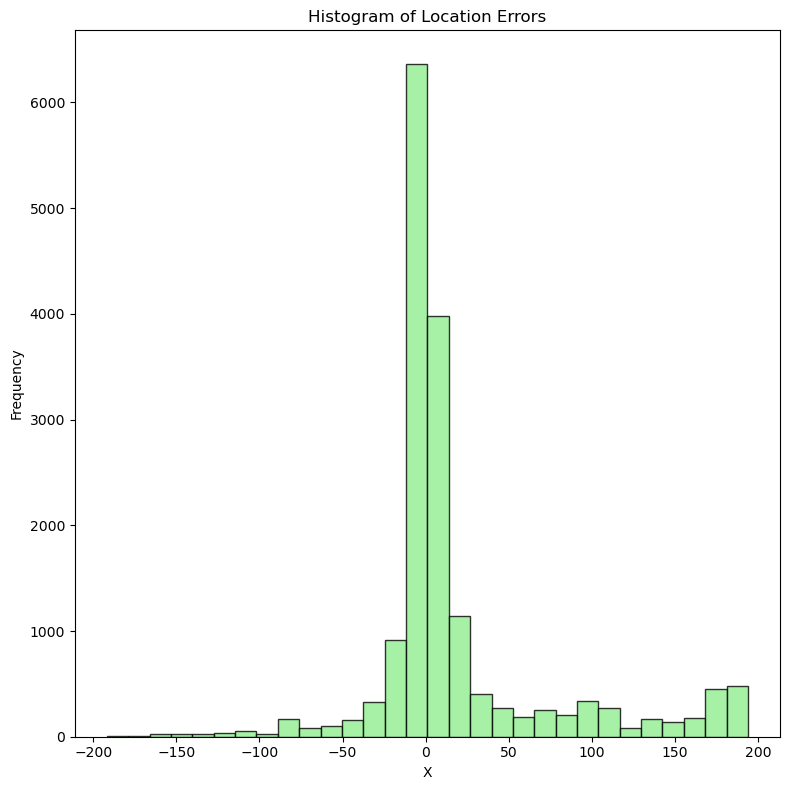

In [11]:
fig, axs = plt.subplots(1, 1, figsize=(8, 8))

axs.hist(error_data['x_errors'], bins=30, color='lightgreen', edgecolor='black', alpha=0.8)
axs.set_title(f"Histogram of Location Errors")
axs.set_xlabel("X")
axs.set_ylabel("Frequency")

plt.tight_layout()
plt.show()

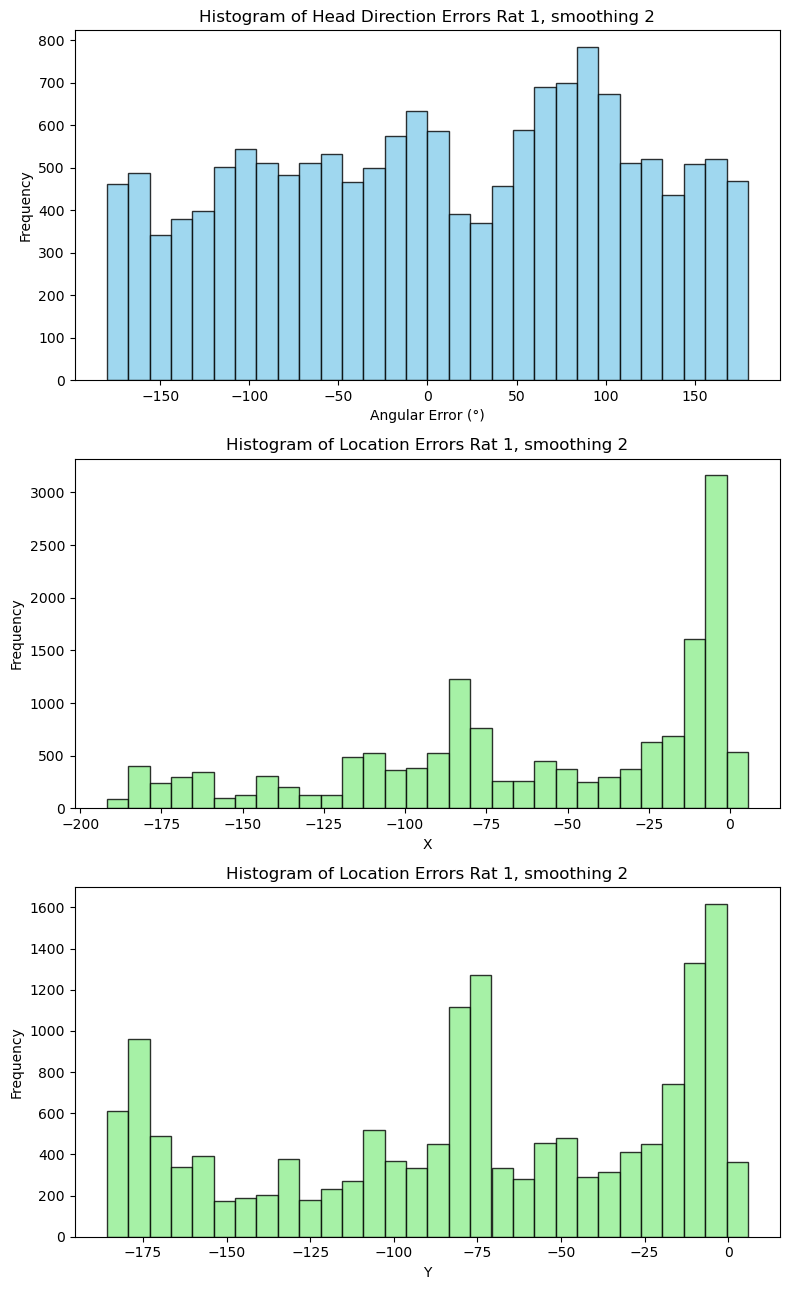

In [8]:
fig, axs = plt.subplots(3, 1, figsize=(8, 13))

axs[0].hist(error_data['hd_errors'], bins=30, color='skyblue', edgecolor='black', alpha=0.8)
axs[0].set_title(f"Histogram of Head Direction Errors Rat {rat}, smoothing 2")
axs[0].set_xlabel("Angular Error (°)")
axs[0].set_ylabel("Frequency")

axs[1].hist(error_data['x_errors'], bins=30, color='lightgreen', edgecolor='black', alpha=0.8)
axs[1].set_title(f"Histogram of Location Errors Rat {rat}, smoothing 2")
axs[1].set_xlabel("X")
axs[1].set_ylabel("Frequency")

axs[2].hist(error_data['y_errors'], bins=30, color='lightgreen', edgecolor='black', alpha=0.8)
axs[2].set_title(f"Histogram of Location Errors Rat {rat}, smoothing 2")
axs[2].set_xlabel("Y")
axs[2].set_ylabel("Frequency")

plt.tight_layout()
plt.show()

# notes:
# put the number of neurons in each md decoding plot
# check if the neurons that have a worse md/hd ratio are in the sessions where the decoding changes a lot with shuffled md
# scatter plots of the error for decoding, you'll need those but maybe just do the heatmap/density
# normalizing via each vertical slice might be helpful, you want to see that they don't change much per axis -> or maybe not because edge issues   
# maybe the md/hd decoding has better nans/firing rate than place cells
# might need a big smoothing kernel or something like 4x4, not smoothing current 
# maybe there's something similar going on when you get a better hd result from shuffling md -- it might smooth things out (like shuffling smoothes out the signal) 
# if that doesn't work, constrain decoding area to be much smaller -> nah, we didn't need to do this at all
# maybe just do 1d decoding from each 
# need to show if it's discretely sampled then there is no bias (histogram like what xuexin sent awhile ago, centered at 0) 




Original data points: 18225
Valid data points after removing NaN: 15527
Mean HD error: 7.543°
Mean Euclidean spatial error: 109.757 units
Covariance matrix:
[[10155.17312178  -424.22038549]
 [ -424.22038549  4217.54190284]]
Ellipse parameters:
  Center: (7.543, 109.757)
  Width: 201.845, Height: 129.420
  Angle: -4.1°


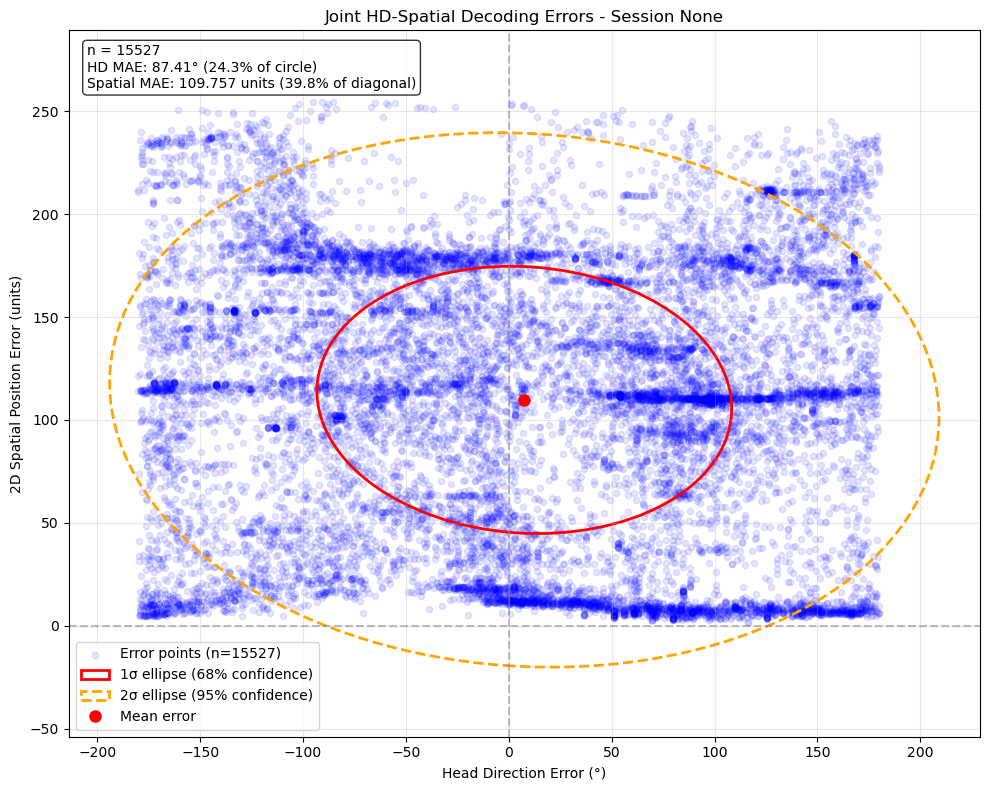


Correlation between HD and spatial errors: -0.065
1σ error ellipse area: 20516.766 square units


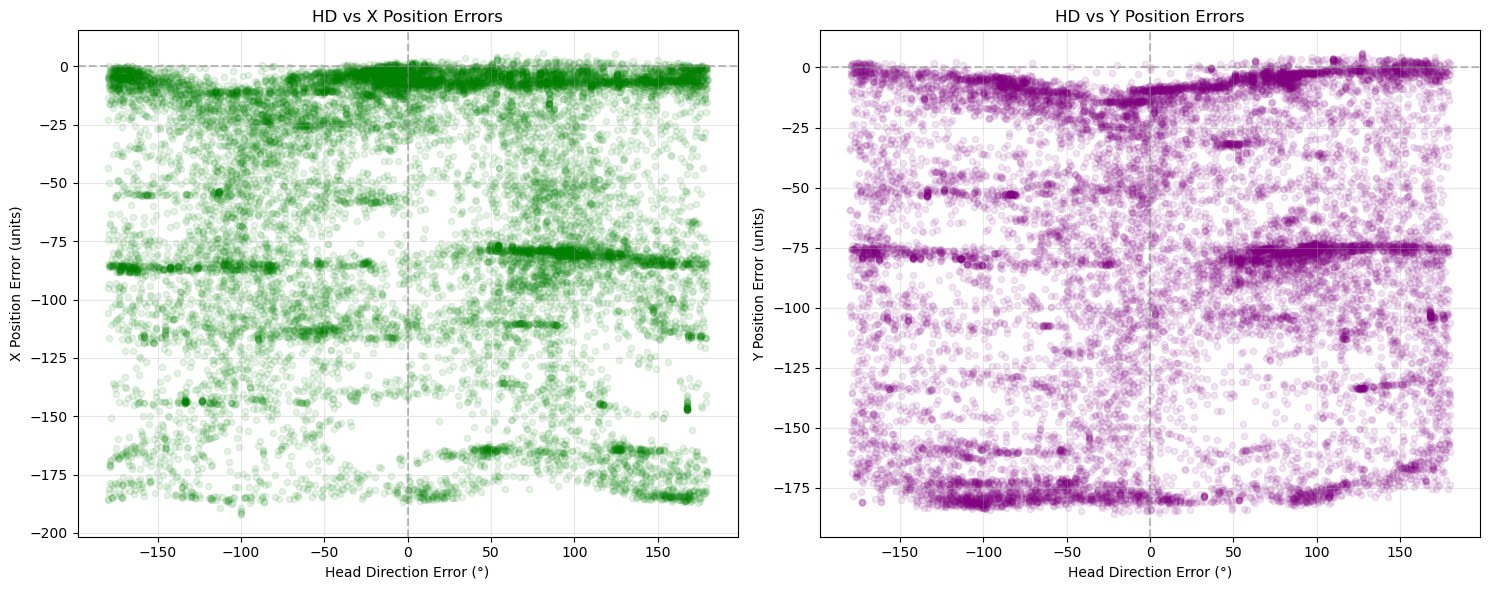

In [11]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches

# The euclidean_errors already combines x and y errors as sqrt(x_error^2 + y_error^2)
# This is more appropriate than using just x or y errors alone

# Create consistent mask for both arrays - remove NaN values from either array
nan_mask_hd = np.isnan(hd_errors)
nan_mask_euclidean = np.isnan(euclidean_errors)
combined_mask = nan_mask_hd | nan_mask_euclidean  # Remove if NaN in either

hd_errors_clean = hd_errors[~combined_mask]
euclidean_errors_clean = euclidean_errors[~combined_mask]

print(f"Original data points: {len(hd_errors)}")
print(f"Valid data points after removing NaN: {len(hd_errors_clean)}")

# Verify arrays are now the same length
assert len(hd_errors_clean) == len(euclidean_errors_clean), f"Length mismatch: HD={len(hd_errors_clean)}, Euclidean={len(euclidean_errors_clean)}"

# Stack errors for covariance calculation
errors = np.vstack((hd_errors_clean, euclidean_errors_clean))

# Create scatter plot
plt.figure(figsize=(10, 8))
plt.scatter(hd_errors_clean, euclidean_errors_clean, alpha=0.1, s=20, 
           color='blue', label=f'Error points (n={len(hd_errors_clean)})')

plt.xlabel('Head Direction Error (°)')
plt.ylabel('2D Spatial Position Error (units)')  # Updated to reflect Euclidean distance
plt.title(f'Joint HD-Spatial Decoding Errors - Session {session}')

# Compute mean and covariance
mean_hd = np.mean(hd_errors_clean)
mean_euclidean = np.mean(euclidean_errors_clean)
mean = np.array([mean_hd, mean_euclidean])

# Compute covariance matrix
cov = np.cov(errors)
print(f"Mean HD error: {mean_hd:.3f}°")
print(f"Mean Euclidean spatial error: {mean_euclidean:.3f} units")
print(f"Covariance matrix:\n{cov}")

# Eigendecomposition for ellipse parameters
eigvals, eigvecs = np.linalg.eig(cov)

# Sort eigenvalues and eigenvectors (largest first)
idx = eigvals.argsort()[::-1]
eigvals = eigvals[idx]
eigvecs = eigvecs[:, idx]

# Compute ellipse angle (in degrees)
angle = np.degrees(np.arctan2(eigvecs[1, 0], eigvecs[0, 0]))

# Ellipse dimensions for 1-sigma (68% confidence)
width = 2 * np.sqrt(eigvals[0])
height = 2 * np.sqrt(eigvals[1])

print(f"Ellipse parameters:")
print(f"  Center: ({mean_hd:.3f}, {mean_euclidean:.3f})")
print(f"  Width: {width:.3f}, Height: {height:.3f}")
print(f"  Angle: {angle:.1f}°")

# Plot 1-sigma ellipse
ellipse_1sig = patches.Ellipse(xy=mean, width=width, height=height, angle=angle,
                              edgecolor='red', facecolor='none', linewidth=2, 
                              label='1σ ellipse (68% confidence)')
plt.gca().add_patch(ellipse_1sig)

# Add 2-sigma ellipse for 95% confidence
width_2sig = 2 * np.sqrt(eigvals[0]) * 2
height_2sig = 2 * np.sqrt(eigvals[1]) * 2
ellipse_2sig = patches.Ellipse(xy=mean, width=width_2sig, height=height_2sig, angle=angle,
                              edgecolor='orange', facecolor='none', linewidth=2, linestyle='--',
                              label='2σ ellipse (95% confidence)')
plt.gca().add_patch(ellipse_2sig)

# Add mean point
plt.plot(mean_hd, mean_euclidean, 'ro', markersize=8, label=f'Mean error')

# Add zero lines for reference
plt.axhline(y=0, color='gray', linestyle='--', alpha=0.5)
plt.axvline(x=0, color='gray', linestyle='--', alpha=0.5)

plt.legend()
plt.grid(True, alpha=0.3)
plt.axis('equal')

# Add statistics to the plot
stats_text = f'n = {len(hd_errors_clean)}\n'
stats_text += f'HD MAE: {np.mean(np.abs(hd_errors_clean)):.2f}°'
stats_text += f' ({error_stats["hd_mean_abs_error_pct"]:.1f}% of circle)\n'
stats_text += f'Spatial MAE: {np.mean(euclidean_errors_clean):.3f} units'
stats_text += f' ({error_stats["euclidean_mean_error_pct"]:.1f}% of diagonal)'

plt.text(0.02, 0.98, stats_text, transform=plt.gca().transAxes, 
         verticalalignment='top', bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))

plt.tight_layout()
plt.show()

# Additional analysis: Correlation between HD and spatial errors
correlation = np.corrcoef(hd_errors_clean, euclidean_errors_clean)[0, 1]
print(f"\nCorrelation between HD and spatial errors: {correlation:.3f}")

# Calculate error ellipse area (for 1-sigma)
ellipse_area = np.pi * (width/2) * (height/2)
print(f"1σ error ellipse area: {ellipse_area:.3f} square units")

# Optional: Create separate plots for X vs HD and Y vs HD errors
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

# X errors vs HD errors
mask_x = ~(np.isnan(hd_errors) | np.isnan(x_errors))
ax1.scatter(hd_errors[mask_x], x_errors[mask_x], alpha=0.1, s=20, color='green')
ax1.set_xlabel('Head Direction Error (°)')
ax1.set_ylabel('X Position Error (units)')
ax1.set_title('HD vs X Position Errors')
ax1.axhline(y=0, color='gray', linestyle='--', alpha=0.5)
ax1.axvline(x=0, color='gray', linestyle='--', alpha=0.5)
ax1.grid(True, alpha=0.3)

# Y errors vs HD errors  
mask_y = ~(np.isnan(hd_errors) | np.isnan(y_errors))
ax2.scatter(hd_errors[mask_y], y_errors[mask_y], alpha=0.1, s=20, color='purple')
ax2.set_xlabel('Head Direction Error (°)')
ax2.set_ylabel('Y Position Error (units)')
ax2.set_title('HD vs Y Position Errors')
ax2.axhline(y=0, color='gray', linestyle='--', alpha=0.5)
ax2.axvline(x=0, color='gray', linestyle='--', alpha=0.5)
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [19]:
# if your signal is more of a HD and decidedly not MD, it's not a simple path integration formula, it might come more from like an optical flow or something from the HD+place cell info



## hd-md decoding

In [17]:

def extract_matlab_obj(obj):
    if not (isinstance(obj, mat_struct) or isinstance(obj, dict)):
        return obj

    out = {}
    obj = obj.__dict__ if isinstance(obj, mat_struct) else obj

    for key, val in obj.items():
        if key in ['_fieldnames', 'type', 'time_unit', 'data_unit', 'name']:
            continue

        if isinstance(val, (mat_struct, dict)):
            out[key] = extract_matlab_obj(val)
        elif isinstance(val, np.ndarray):
            arr = [extract_matlab_obj(v) for v in val]
            out[key] = np.array(arr)
        else:
            out[key] = val

    return out

def circular_difference(decoded, ground_truth):
    diff = (decoded - ground_truth + 180) % 360 - 180
    return diff

def load_behavioral_data(current_file_path, dataset, dataset_n=None, session=None, data_path=None):
    if dataset.lower() == 'dusz':
        data_path = current_file_path / f"data/{dataset}/Dataset_{dataset_n}/{session}/Data"
        
        tracking_data = pd.read_csv(data_path / "Tracking_data.csv")
        tracking_data.columns = ['timestamp', 'x', 'y', 'hd', 'pitch', 'roll']
        positions = tracking_data[['timestamp', 'x', 'y', 'hd']].to_numpy()
        
        velocity = loadmat(data_path / "Velocity.mat", struct_as_record=False, squeeze_me=True)
        velocity = extract_matlab_obj(velocity['vel'])
        velocity = np.column_stack((velocity['t'], velocity['data']))
        
        epochs = loadmat(data_path / "BehavEpochs.mat", struct_as_record=False, squeeze_me=True)
        if dataset_n == 6:
            epoch_data = extract_matlab_obj(epochs['wakeEp'])
        else:
            epoch_data = extract_matlab_obj(epochs['wake1Ep'])
        
        velocity_mask = (velocity[:, 0] > epoch_data['start']) & (velocity[:, 0] < epoch_data['stop'])
        velocity = velocity[velocity_mask]
        
        position_mask = (positions[:, 0] > epoch_data['start']) & (positions[:, 0] < epoch_data['stop'])
        positions = positions[position_mask]
        
        positions[:, 1] += abs(np.min(positions[:, 1]))
        positions[:, 2] += abs(np.min(positions[:, 2]))
        
    elif dataset.lower() == 'pfeiffer':
        if data_path is None:
            data_path = "/home/mag/Space/data/PfeifferData/Rat1/Open1"
        
        # Load position data from .mat file
        positions = loadmat(f'{data_path}/Position_Data.mat')['Position_Data']
        
        epoch_data = None  # No epoch data for Pfeiffer
        
        time_step_gap = positions[3, 0] - positions[2, 0]
        point_steps = np.diff(positions[:, 1:3], axis=0)
        point_steps = np.vstack((point_steps, point_steps[-1]))
        point_dist = np.linalg.norm(point_steps, axis=1) / time_step_gap
        
        velocity = np.column_stack((positions[:, 0], point_dist))
        
    else:
        raise ValueError(f"Unknown dataset type: {dataset}. Use 'dusz' or 'pfeiffer'")
    
    return positions, velocity, epoch_data

def compute_movement_direction(positions, window_size=5):
    """Compute movement direction from position data"""
    timestamps = positions[:, 0]
    x = positions[:, 1]
    y = positions[:, 2]
    
    # Smooth positions before computing direction
    from scipy.ndimage import uniform_filter1d
    x_smooth = uniform_filter1d(x, size=window_size, mode='nearest')
    y_smooth = uniform_filter1d(y, size=window_size, mode='nearest')
    
    # Compute movement direction
    dx = np.gradient(x_smooth)
    dy = np.gradient(y_smooth)
    
    # Calculate angle in degrees (0-360)
    md = (np.degrees(np.arctan2(dy, dx)) + 360) % 360
    
    # For stationary periods, movement direction is undefined
    speed = np.sqrt(dx**2 + dy**2)
    md[speed < 0.01] = np.nan  # Threshold for essentially stationary
    
    return md

def compute_ground_truth_hd_md(positions, time_centers, velocity, velocity_filter):
    timestamps = positions[:, 0]
    hd = positions[:, 3]
    
    # Compute movement direction
    md = compute_movement_direction(positions)
    
    # Interpolate HD and MD to time centers
    ground_hd_interp = (np.interp(time_centers, timestamps, hd) + 360) % 360
    
    # For MD, need to handle NaN values carefully
    valid_md = ~np.isnan(md)
    if np.sum(valid_md) > 1:
        ground_md_interp = np.interp(time_centers, timestamps[valid_md], md[valid_md])
    else:
        ground_md_interp = np.full(len(time_centers), np.nan)
    
    # Apply velocity filter
    velocity_interp = np.full(len(time_centers), np.nan)
    for i in range(len(time_centers)):
        mask = (velocity[:, 0] >= time_centers[i] - 0.06) & (velocity[:, 0] <= time_centers[i] + 0.06)
        if np.any(mask):
            velocity_interp[i] = np.nanmean(velocity[mask, 1])
    
    valid_velocity = (velocity_interp >= velocity_filter) & (~np.isnan(velocity_interp))
    ground_hd_filtered = np.where(valid_velocity, ground_hd_interp, np.nan)
    ground_md_filtered = np.where(valid_velocity, ground_md_interp, np.nan)
    
    return ground_hd_filtered, ground_md_filtered

def analyze_cv_errors_hd_md(save_path, positions, velocity, velocity_filter, n_hd_bins=17, num_folds=4):
    hd_errors_all = []
    md_errors_all = []
    combined_errors_all = []
    
    for cv in range(num_folds):
        # Adjust file naming for HD-MD decoding
        #base_name = f"decoded_md_{n_hd_bins}_{n_hd_bins}_cv{cv}"
        
        # Try to load the decoded HD and MD data
        try:
            #print(f"{save_path}/decoded_hd_{n_hd_bins}_{n_hd_bins}_cv{cv}.npy")
            decoded_hd = np.load(f"{save_path}/decoded_hd_{n_hd_bins}_{n_hd_bins}_cv{cv}.npy")
            decoded_md = np.load(f"{save_path}/decoded_md_{n_hd_bins}_{n_hd_bins}_cv{cv}.npy")
            time_centers_cv = np.load(f"{save_path}/time_centers_cv{cv}.npy")
        except FileNotFoundError:
            # Alternative naming convention
            #base_name = f"decoded_cv{cv}_hd_md_{n_hd_bins}_{n_hd_bins}"
            #try:
            #    decoded_hd = np.load(f"{save_path}/{base_name}_hd.npy")
            #    decoded_md = np.load(f"{save_path}/{base_name}_md.npy")
            #    time_centers_cv = np.load(f"{save_path}/{base_name}_time_centers.npy")
            #except FileNotFoundError:
            print(f"Warning: Could not find decoded files for CV fold {cv}")
            continue
        
        # Compute ground truth for HD and MD
        ground_hd_test, ground_md_test = compute_ground_truth_hd_md(
            positions, time_centers_cv, velocity, velocity_filter
        )
        
        print(f"  CV fold {cv}: {len(time_centers_cv)} test samples")
        
        # Compute circular errors for both HD and MD
        hd_error = circular_difference(decoded_hd, ground_hd_test)
        md_error = circular_difference(decoded_md, ground_md_test)
        
        # Combined error (normalized angular difference)
        hd_error_normalized = hd_error / 180.0  # Scale to [-1, 1]
        md_error_normalized = md_error / 180.0  # Scale to [-1, 1]
        combined_error = np.sqrt(hd_error_normalized**2 + md_error_normalized**2)
        
        hd_errors_all.append(hd_error)
        md_errors_all.append(md_error)
        combined_errors_all.append(combined_error)
    
    if not hd_errors_all:
        print("Error: No valid CV folds found")
        return None, None, None, None, None
    
    hd_errors = np.concatenate(hd_errors_all)
    md_errors = np.concatenate(md_errors_all)
    combined_errors = np.concatenate(combined_errors_all)
    
    error_stats = {
        'hd_mean_abs_error': np.nanmean(np.abs(hd_errors)),
        'hd_median_abs_error': np.nanmedian(np.abs(hd_errors)),
        'hd_std_error': np.nanstd(np.abs(hd_errors)),
        'hd_mean_abs_error_pct': (np.nanmean(np.abs(hd_errors)) / 360) * 100,
        'hd_median_abs_error_pct': (np.nanmedian(np.abs(hd_errors)) / 360) * 100,
        'md_mean_abs_error': np.nanmean(np.abs(md_errors)),
        'md_median_abs_error': np.nanmedian(np.abs(md_errors)),
        'md_std_error': np.nanstd(np.abs(md_errors)),
        'md_mean_abs_error_pct': (np.nanmean(np.abs(md_errors)) / 360) * 100,
        'md_median_abs_error_pct': (np.nanmedian(np.abs(md_errors)) / 360) * 100,
        'combined_mean_error': np.nanmean(combined_errors),
        'combined_median_error': np.nanmedian(combined_errors),
        'combined_std_error': np.nanstd(combined_errors),
        'total_samples': len(hd_errors),
        'hd_valid_samples': np.sum(~np.isnan(hd_errors)),
        'md_valid_samples': np.sum(~np.isnan(md_errors)),
        'angular_correlation': np.nanmean(np.cos(np.radians(hd_errors - md_errors)))
    }
    
    return error_stats, hd_errors, md_errors, combined_errors


print(f"HD-MD Decoding Error Analysis")
print(f"Dataset: {dataset}/Dataset_{dataset_n}/{session}")
print(f"Bins: HD={n_hd_bins}, MD={n_hd_bins}")
print(f"Velocity threshold: {velocity_filter} cm/s")
print("-" * 50)

# Load behavioral data
print("Loading behavioral data...")
if dataset == 'dusz':
    positions, velocity, epoch_data = load_behavioral_data(
        current_file_path, dataset='dusz', dataset_n=dataset_n, session=session
    )
elif dataset == 'pfeiffer':
    positions, velocity, epoch_data = load_behavioral_data(
        current_file_path, dataset='pfeiffer', 
        data_path="/home/mag/Space/data/PfeifferData/Rat1/Open1"
    )

# Analyze cross-validation errors for HD-MD
print("Analyzing cross-validation errors for HD-MD...")
error_stats, hd_errors, md_errors, combined_errors = analyze_cv_errors_hd_md(
    save_path, positions, velocity, velocity_filter, n_hd_bins
)

if error_stats is None:
    print("Error analysis failed - no valid data found")
else:
    # Print results
    print("\n" + "="*50)
    print("HD-MD DECODING ERROR ANALYSIS RESULTS")
    print("="*50)

    print(f"\nHead Direction (HD) Errors:")
    print(f"  Mean Absolute Error:   {error_stats['hd_mean_abs_error']:.2f}° ({error_stats['hd_mean_abs_error_pct']:.1f}% of circle)")
    print(f"  Median Absolute Error: {error_stats['hd_median_abs_error']:.2f}° ({error_stats['hd_median_abs_error_pct']:.1f}% of circle)")
    print(f"  Standard Deviation:    {error_stats['hd_std_error']:.2f}°")

    print(f"\nMovement Direction (MD) Errors:")
    print(f"  Mean Absolute Error:   {error_stats['md_mean_abs_error']:.2f}° ({error_stats['md_mean_abs_error_pct']:.1f}% of circle)")
    print(f"  Median Absolute Error: {error_stats['md_median_abs_error']:.2f}° ({error_stats['md_median_abs_error_pct']:.1f}% of circle)")
    print(f"  Standard Deviation:    {error_stats['md_std_error']:.2f}°")

    print(f"\nCombined HD-MD Errors:")
    print(f"  Mean Error:            {error_stats['combined_mean_error']:.3f}")
    print(f"  Median Error:          {error_stats['combined_median_error']:.3f}")
    print(f"  Standard Deviation:    {error_stats['combined_std_error']:.3f}")
    print(f"  Angular Correlation:   {error_stats['angular_correlation']:.3f}")

    print(f"\nSample Statistics:")
    print(f"  Total Samples:         {error_stats['total_samples']}")
    print(f"  HD Valid Samples:      {error_stats['hd_valid_samples']} ({100*error_stats['hd_valid_samples']/error_stats['total_samples']:.1f}%)")
    print(f"  MD Valid Samples:      {error_stats['md_valid_samples']} ({100*error_stats['md_valid_samples']/error_stats['total_samples']:.1f}%)")

    # Save error data for further analysis
    error_data = {
        'hd_errors': hd_errors,
        'md_errors': md_errors,
        'combined_errors': combined_errors,
        'error_stats': error_stats
    }

    save_file = f"{save_path}/error_analysis_hd_md_{n_hd_bins}_{n_hd_bins}.npy"
    np.save(save_file, error_data)
    print(f"\nError analysis results saved to {save_file}")


HD-MD Decoding Error Analysis
Dataset: dusz/Dataset_6/A1821-190910
Bins: HD=17, MD=17
Velocity threshold: 2 cm/s
--------------------------------------------------
Loading behavioral data...
Analyzing cross-validation errors for HD-MD...
  CV fold 0: 5640 test samples
  CV fold 1: 5640 test samples
  CV fold 2: 5640 test samples
  CV fold 3: 5639 test samples

HD-MD DECODING ERROR ANALYSIS RESULTS

Head Direction (HD) Errors:
  Mean Absolute Error:   16.19° (4.5% of circle)
  Median Absolute Error: 10.32° (2.9% of circle)
  Standard Deviation:    23.84°

Movement Direction (MD) Errors:
  Mean Absolute Error:   nan° (nan% of circle)
  Median Absolute Error: nan° (nan% of circle)
  Standard Deviation:    nan°

Combined HD-MD Errors:
  Mean Error:            nan
  Median Error:          nan
  Standard Deviation:    nan
  Angular Correlation:   nan

Sample Statistics:
  Total Samples:         22559
  HD Valid Samples:      20387 (90.4%)
  MD Valid Samples:      0 (0.0%)

Error analysis res

/tmp/ipykernel_3544387/4094382700.py:188: RuntimeWarning: Mean of empty slice
  'md_mean_abs_error': np.nanmean(np.abs(md_errors)),
/tmp/ipykernel_3544387/4094382700.py:189: RuntimeWarning: All-NaN slice encountered
  'md_median_abs_error': np.nanmedian(np.abs(md_errors)),
/home/mag/miniconda3/envs/predictive-code/lib/python3.11/site-packages/numpy/lib/nanfunctions.py:1879: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
/tmp/ipykernel_3544387/4094382700.py:191: RuntimeWarning: Mean of empty slice
  'md_mean_abs_error_pct': (np.nanmean(np.abs(md_errors)) / 360) * 100,
/tmp/ipykernel_3544387/4094382700.py:192: RuntimeWarning: All-NaN slice encountered
  'md_median_abs_error_pct': (np.nanmedian(np.abs(md_errors)) / 360) * 100,
/tmp/ipykernel_3544387/4094382700.py:193: RuntimeWarning: Mean of empty slice
  'combined_mean_error': np.nanmean(combined_errors),
/tmp/ipykernel_3544387/4094382700.py:194: RuntimeWarning: All-NaN sl

ValueError: autodetected range of [nan, nan] is not finite

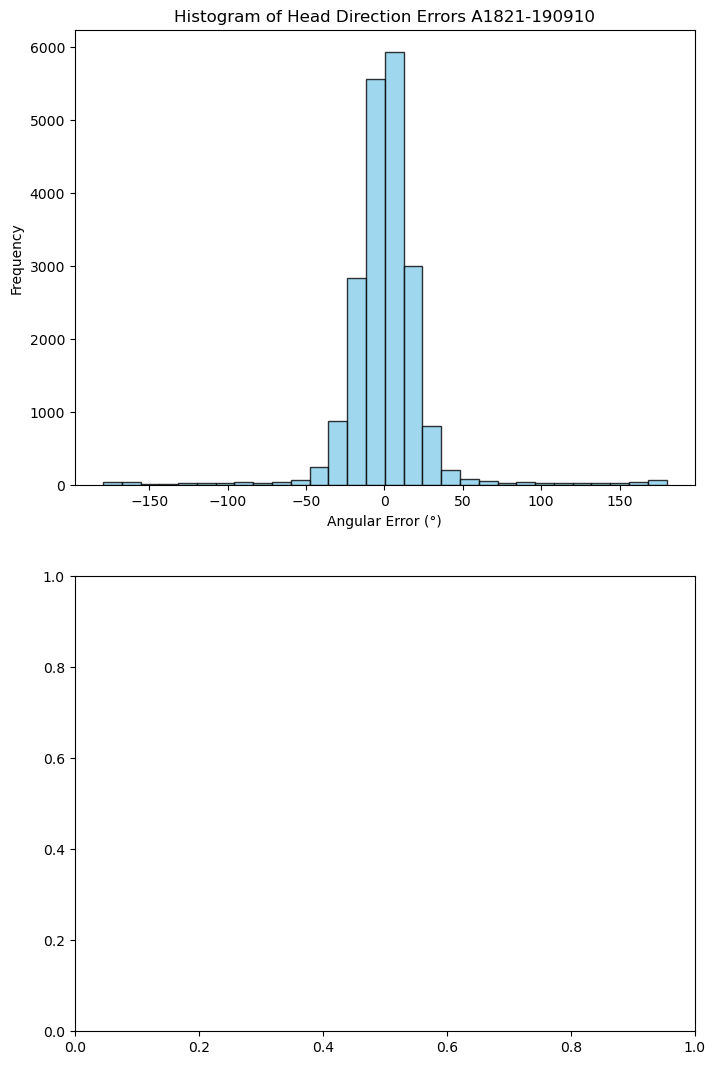

In [14]:
fig, axs = plt.subplots(2, 1, figsize=(8, 13))

axs[0].hist(error_data['hd_errors'], bins=30, color='skyblue', edgecolor='black', alpha=0.8)
axs[0].set_title(f"Histogram of Head Direction Errors {session}")
axs[0].set_xlabel("Angular Error (°)")
axs[0].set_ylabel("Frequency")

axs[1].hist(error_data['md_errors'], bins=30, color='lightgreen', edgecolor='black', alpha=0.8)
axs[1].set_title(f"Histogram of Movement Direction Errors {session}")
axs[1].set_xlabel("Angular Error (°)")
axs[1].set_ylabel("Frequency")

plt.tight_layout()
plt.show()

Original data points: 22559
Valid data points after removing NaN: 0
Mean HD error: nan°
Mean MD error: nan°
Covariance matrix:
[[nan nan]
 [nan nan]]


/home/mag/miniconda3/envs/predictive-code/lib/python3.11/site-packages/numpy/core/fromnumeric.py:3504: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
/home/mag/miniconda3/envs/predictive-code/lib/python3.11/site-packages/numpy/core/_methods.py:129: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)
/home/mag/miniconda3/envs/predictive-code/lib/python3.11/site-packages/numpy/lib/function_base.py:520: RuntimeWarning: Mean of empty slice.
  avg = a.mean(axis, **keepdims_kw)
/home/mag/miniconda3/envs/predictive-code/lib/python3.11/site-packages/numpy/core/_methods.py:121: RuntimeWarning: invalid value encountered in divide
  ret = um.true_divide(
/tmp/ipykernel_3544387/4168380999.py:40: RuntimeWarning: Degrees of freedom <= 0 for slice
  cov = np.cov(errors)
/home/mag/miniconda3/envs/predictive-code/lib/python3.11/site-packages/numpy/lib/function_base.py:2748: RuntimeWarning: divide by zero encountered in

LinAlgError: Array must not contain infs or NaNs

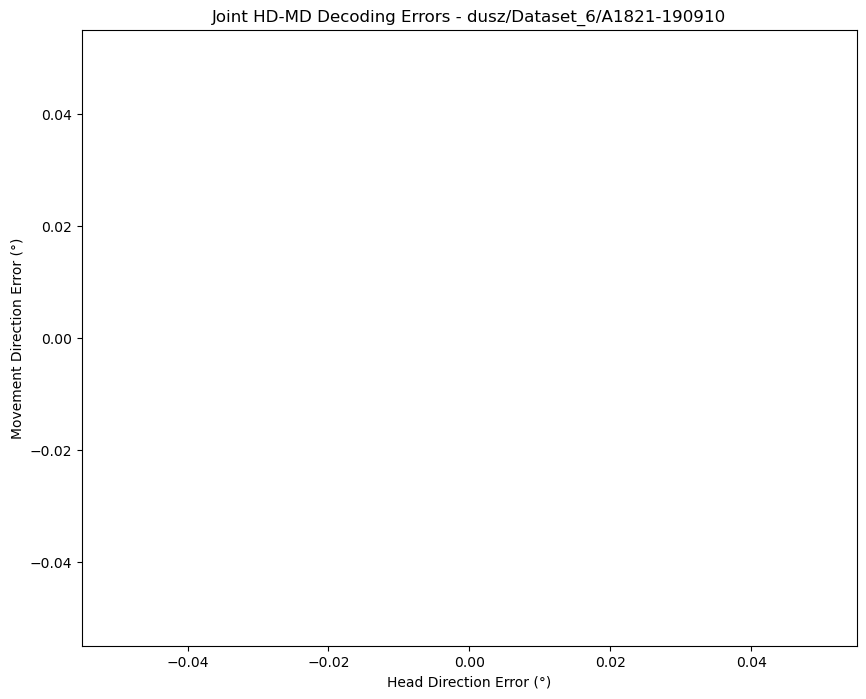

In [21]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches

# Assuming hd_errors and md_errors are already computed from the analysis above
# Both are angular errors in degrees

# Create consistent mask for both arrays - remove NaN values from either array
nan_mask_hd = np.isnan(hd_errors)
nan_mask_md = np.isnan(md_errors)
combined_mask = nan_mask_hd | nan_mask_md  # Remove if NaN in either

hd_errors_clean = hd_errors[~combined_mask]
md_errors_clean = md_errors[~combined_mask]

print(f"Original data points: {len(hd_errors)}")
print(f"Valid data points after removing NaN: {len(hd_errors_clean)}")

# Verify arrays are now the same length
assert len(hd_errors_clean) == len(md_errors_clean), f"Length mismatch: HD={len(hd_errors_clean)}, MD={len(md_errors_clean)}"

# Stack errors for covariance calculation
errors = np.vstack((hd_errors_clean, md_errors_clean))

# Create scatter plot
plt.figure(figsize=(10, 8))
plt.scatter(hd_errors_clean, md_errors_clean, alpha=0.1, s=20, 
           color='blue', label=f'Error points (n={len(hd_errors_clean)})')

plt.xlabel('Head Direction Error (°)')
plt.ylabel('Movement Direction Error (°)')
plt.title(f'Joint HD-MD Decoding Errors - {dataset}/Dataset_{dataset_n}/{session}')

# Compute mean and covariance
mean_hd = np.mean(hd_errors_clean)
mean_md = np.mean(md_errors_clean)
mean = np.array([mean_hd, mean_md])

# Compute covariance matrix
cov = np.cov(errors)
print(f"Mean HD error: {mean_hd:.3f}°")
print(f"Mean MD error: {mean_md:.3f}°")
print(f"Covariance matrix:\n{cov}")

# Eigendecomposition for ellipse parameters
eigvals, eigvecs = np.linalg.eig(cov)

# Sort eigenvalues and eigenvectors (largest first)
idx = eigvals.argsort()[::-1]
eigvals = eigvals[idx]
eigvecs = eigvecs[:, idx]

# Compute ellipse angle (in degrees)
angle = np.degrees(np.arctan2(eigvecs[1, 0], eigvecs[0, 0]))

# Ellipse dimensions for 1-sigma (68% confidence)
width = 2 * np.sqrt(eigvals[0])
height = 2 * np.sqrt(eigvals[1])

print(f"Ellipse parameters:")
print(f"  Center: ({mean_hd:.3f}, {mean_md:.3f})")
print(f"  Width: {width:.3f}°, Height: {height:.3f}°")
print(f"  Angle: {angle:.1f}°")

# Plot 1-sigma ellipse
ellipse_1sig = patches.Ellipse(xy=mean, width=width, height=height, angle=angle,
                              edgecolor='red', facecolor='none', linewidth=2, 
                              label='1σ ellipse (68% confidence)')
plt.gca().add_patch(ellipse_1sig)

# Add 2-sigma ellipse for 95% confidence
width_2sig = 2 * np.sqrt(eigvals[0]) * 2
height_2sig = 2 * np.sqrt(eigvals[1]) * 2
ellipse_2sig = patches.Ellipse(xy=mean, width=width_2sig, height=height_2sig, angle=angle,
                              edgecolor='orange', facecolor='none', linewidth=2, linestyle='--',
                              label='2σ ellipse (95% confidence)')
plt.gca().add_patch(ellipse_2sig)

# Add mean point
plt.plot(mean_hd, mean_md, 'ro', markersize=8, label=f'Mean error')

# Add zero lines for reference
plt.axhline(y=0, color='gray', linestyle='--', alpha=0.5)
plt.axvline(x=0, color='gray', linestyle='--', alpha=0.5)

# Add diagonal line (where HD error = MD error)
ax_min = min(plt.xlim()[0], plt.ylim()[0])
ax_max = max(plt.xlim()[1], plt.ylim()[1])
plt.plot([ax_min, ax_max], [ax_min, ax_max], 'k--', alpha=0.3, label='HD error = MD error')

plt.legend()
plt.grid(True, alpha=0.3)
plt.axis('equal')

# Add statistics to the plot
stats_text = f'n = {len(hd_errors_clean)}\n'
stats_text += f'HD MAE: {np.mean(np.abs(hd_errors_clean)):.2f}°'
stats_text += f' ({error_stats["hd_mean_abs_error_pct"]:.1f}% of circle)\n'
stats_text += f'MD MAE: {np.mean(np.abs(md_errors_clean)):.2f}°'
stats_text += f' ({error_stats["md_mean_abs_error_pct"]:.1f}% of circle)\n'
stats_text += f'Angular Correlation: {error_stats["angular_correlation"]:.3f}'

plt.text(0.02, 0.98, stats_text, transform=plt.gca().transAxes, 
         verticalalignment='top', bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))

plt.tight_layout()
plt.show()

# Additional analysis: Correlation between HD and MD errors
correlation = np.corrcoef(hd_errors_clean, md_errors_clean)[0, 1]
print(f"\nLinear correlation between HD and MD errors: {correlation:.3f}")
print(f"Angular correlation: {error_stats['angular_correlation']:.3f}")

# Calculate error ellipse area (for 1-sigma)
ellipse_area = np.pi * (width/2) * (height/2)
print(f"1σ error ellipse area: {ellipse_area:.3f} square degrees")


## Destroyed MD analysis


A1806-190307

Analyzing ORIGINAL decoding errors (MD)...
  CV fold 0: 2731 test samples, 2704 valid MD samples
  CV fold 1: 2731 test samples, 2731 valid MD samples
  CV fold 2: 2731 test samples, 2731 valid MD samples
  CV fold 3: 2731 test samples, 2710 valid MD samples

[ORIGINAL ]
  HD Mean Error: 71.79° (39.9%)
  MD Mean Error: 88.27° (49.0%)

Analyzing MD-DESTROYED decoding errors (MD)...
  CV fold 0: 2731 test samples, 2704 valid MD samples
  CV fold 1: 2731 test samples, 2731 valid MD samples
  CV fold 2: 2731 test samples, 2731 valid MD samples
  CV fold 3: 2731 test samples, 2710 valid MD samples

[MD-DESTROYED ]
  HD Mean Error: 60.52° (33.6%)
  MD Mean Error: 90.33° (50.2%)

COMPARISON RESULTS
  HD Error Change: -11.26° (×0.84)
  MD Error Change: +2.06° (×1.02)

[INTERPRETATION]
  ⚠ PARTIAL EVIDENCE for HD selectivity:
    - HD decoding remains accurate
    - But MD decoding not sufficiently impaired
    → Possible residual MD information or insufficient shuffling

Summary

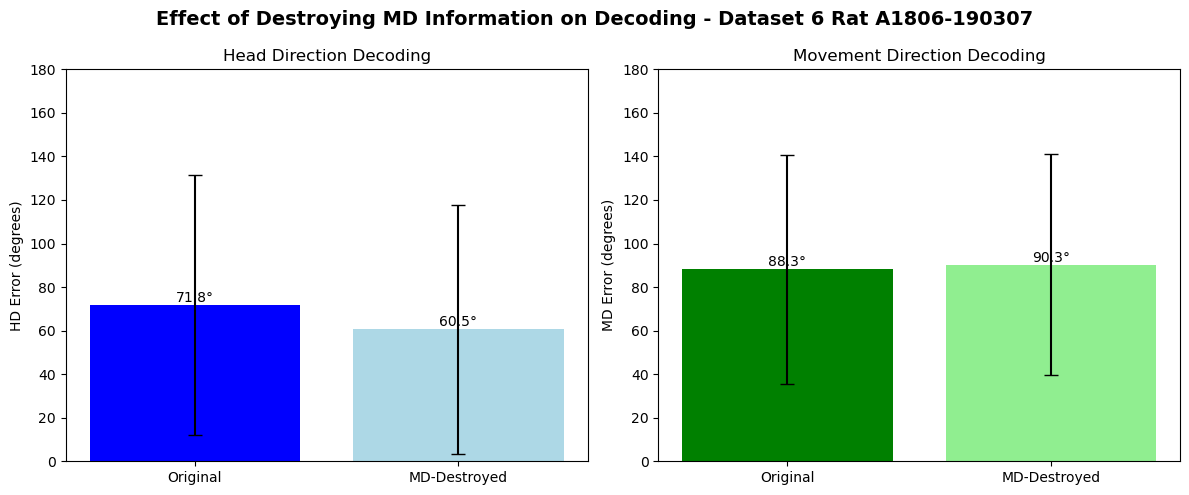

In [16]:
def extract_matlab_obj(obj):
    if not (isinstance(obj, mat_struct) or isinstance(obj, dict)):
        return obj

    out = {}
    obj = obj.__dict__ if isinstance(obj, mat_struct) else obj

    for key, val in obj.items():
        if key in ['_fieldnames', 'type', 'time_unit', 'data_unit', 'name']:
            continue

        if isinstance(val, (mat_struct, dict)):
            out[key] = extract_matlab_obj(val)
        elif isinstance(val, np.ndarray):
            arr = [extract_matlab_obj(v) for v in val]
            out[key] = np.array(arr)
        else:
            out[key] = val

    return out

def circular_difference(decoded, ground_truth):
    diff = (decoded - ground_truth + 180) % 360 - 180
    return diff

def load_behavioral_data(current_file_path, dataset, dataset_n=None, session=None, data_path=None):
    if dataset.lower() == 'dusz':
        data_path = current_file_path / f"data/{dataset}/Dataset_{dataset_n}/{session}/Data"
        
        tracking_data = pd.read_csv(data_path / "Tracking_data.csv")
        tracking_data.columns = ['timestamp', 'x', 'y', 'hd', 'pitch', 'roll']
        positions = tracking_data[['timestamp', 'x', 'y', 'hd']].to_numpy()
        
        velocity = loadmat(data_path / "Velocity.mat", struct_as_record=False, squeeze_me=True)
        velocity = extract_matlab_obj(velocity['vel'])
        velocity = np.column_stack((velocity['t'], velocity['data']))
        
        epochs = loadmat(data_path / "BehavEpochs.mat", struct_as_record=False, squeeze_me=True)
        if dataset_n == 6:
            epoch_data = extract_matlab_obj(epochs['wakeEp'])
        else:
            epoch_data = extract_matlab_obj(epochs['wake1Ep'])
        
        velocity_mask = (velocity[:, 0] > epoch_data['start']) & (velocity[:, 0] < epoch_data['stop'])
        velocity = velocity[velocity_mask]
        
        position_mask = (positions[:, 0] > epoch_data['start']) & (positions[:, 0] < epoch_data['stop'])
        positions = positions[position_mask]
        
        positions[:, 1] += abs(np.min(positions[:, 1]))
        positions[:, 2] += abs(np.min(positions[:, 2]))
        
    elif dataset.lower() == 'pfeiffer':
        if data_path is None:
            data_path = "/home/mag/Space/data/PfeifferData/Rat1/Open1"
        
        # Load position data from .mat file
        positions = loadmat(f'{data_path}/Position_Data.mat')['Position_Data']
        
        epoch_data = None  # No epoch data for Pfeiffer
        
        time_step_gap = positions[3, 0] - positions[2, 0]
        point_steps = np.diff(positions[:, 1:3], axis=0)
        point_steps = np.vstack((point_steps, point_steps[-1]))
        point_dist = np.linalg.norm(point_steps, axis=1) / time_step_gap
        
        velocity = np.column_stack((positions[:, 0], point_dist))
        
    else:
        raise ValueError(f"Unknown dataset type: {dataset}. Use 'dusz' or 'pfeiffer'")
    
    return positions, velocity, epoch_data

def get_md_from_xy(positions, smoothing_window=200):
    def circular_smooth(angles, smoothing_window):
        angles_rad = np.radians(angles)
        sin_vals = np.sin(angles_rad)
        cos_vals = np.cos(angles_rad)
        kernel = np.ones(smoothing_window) / smoothing_window
        smooth_sin = np.convolve(sin_vals, kernel, mode='same')
        smooth_cos = np.convolve(cos_vals, kernel, mode='same')
        smooth_angles = np.degrees(np.arctan2(smooth_sin, smooth_cos)) % 360
        return smooth_angles
    
    x = positions[:, 1]
    y = positions[:, 2]
    
    dx = x[1:] - x[:-1]
    dy = y[1:] - y[:-1]
    
    direction = np.degrees(np.arctan2(-dy, dx))
    direction = (direction + 360) % 360
    direction = circular_smooth(direction, smoothing_window=smoothing_window)
    direction = np.concatenate([direction, [direction[-1]]])
    
    return direction

def compare_results(stats_original, stats_destroyed):
    """Compare original and MD-destroyed results"""
    if stats_original is None or stats_destroyed is None:
        return None
    
    comparison = {
        'hd_error_change': stats_destroyed['hd_mean_abs_error'] - stats_original['hd_mean_abs_error'],
        'hd_error_ratio': stats_destroyed['hd_mean_abs_error'] / stats_original['hd_mean_abs_error'],
        'md_error_change': stats_destroyed['md_mean_abs_error'] - stats_original['md_mean_abs_error'],
        'md_error_ratio': stats_destroyed['md_mean_abs_error'] / stats_original['md_mean_abs_error'],
        'hd_preserved': stats_destroyed['hd_mean_abs_error'] < stats_original['hd_mean_abs_error'] * 1.2,
        'md_destroyed': stats_destroyed['md_mean_abs_error'] > stats_original['md_mean_abs_error'] * 1.5,
    }
    return comparison

def compute_ground_truth_hd_md(positions, time_centers, velocity, velocity_filter, smoothing_window=200):
    """
    Compute ground truth with MD calculated the same way as in the decode script.
    """
    timestamps = positions[:, 0]
    hd = positions[:, 3]
    
    # Use the same MD calculation as decode script
    md = get_md_from_xy(positions, smoothing_window=smoothing_window)
    
    # Interpolate HD and MD to time centers
    ground_hd_interp = (np.interp(time_centers, timestamps, hd) + 360) % 360
    ground_md_interp = (np.interp(time_centers, timestamps, md) + 360) % 360
    
    # Apply velocity filter (but don't make MD NaN - just mark invalid for error calculation)
    velocity_interp = np.full(len(time_centers), np.nan)
    for i in range(len(time_centers)):
        mask = (velocity[:, 0] >= time_centers[i] - 0.06) & (velocity[:, 0] <= time_centers[i] + 0.06)
        if np.any(mask):
            velocity_interp[i] = np.nanmean(velocity[mask, 1])
    
    valid_velocity = (velocity_interp >= velocity_filter) & (~np.isnan(velocity_interp))
    
    # Only set to NaN where velocity is too low (for fair comparison with decoder)
    ground_hd_filtered = np.where(valid_velocity, ground_hd_interp, np.nan)
    ground_md_filtered = np.where(valid_velocity, ground_md_interp, np.nan)
    
    return ground_hd_filtered, ground_md_filtered

# Updated analysis function with the MD computation
def analyze_cv_errors_hd_md(save_path, positions, velocity, velocity_filter, n_hd_bins=17, num_folds=4, md_destroyed=False, smoothing_window=75):
    """
    version with consistent MD calculation
    """
    hd_errors_all = []
    md_errors_all = []
    combined_errors_all = []
    
    suffix = "_md_destroyed" if md_destroyed else ""
    
    for cv in range(num_folds):
        try:
            decoded_hd = np.load(f"{save_path}/decoded_hd_{n_hd_bins}_{n_hd_bins}_cv{cv}{suffix}.npy")
            decoded_md = np.load(f"{save_path}/decoded_md_{n_hd_bins}_{n_hd_bins}_cv{cv}{suffix}.npy")
            
            time_centers_cv = np.load(f"{save_path}/time_centers_cv{cv}{suffix}.npy")
        except FileNotFoundError:
            print(f"Warning: Could not find decoded files for CV fold {cv} (suffix: '{suffix}')")
            continue
        
        # Use the ground truth computation
        ground_hd_test, ground_md_test = compute_ground_truth_hd_md(
            positions, time_centers_cv, velocity, velocity_filter, smoothing_window=smoothing_window
        )
        
        print(f"  CV fold {cv}: {len(time_centers_cv)} test samples, {np.sum(~np.isnan(ground_md_test))} valid MD samples")
        
        hd_error = circular_difference(decoded_hd, ground_hd_test)
        md_error = circular_difference(decoded_md, ground_md_test)
        
        hd_error_normalized = hd_error / 180.0
        md_error_normalized = md_error / 180.0
        combined_error = np.sqrt(hd_error_normalized**2 + md_error_normalized**2)
        
        hd_errors_all.append(hd_error)
        md_errors_all.append(md_error)
        combined_errors_all.append(combined_error)
    
    if not hd_errors_all:
        print("Error: No valid CV folds found")
        return None, None, None, None
    
    hd_errors = np.concatenate(hd_errors_all)
    md_errors = np.concatenate(md_errors_all)
    combined_errors = np.concatenate(combined_errors_all)
    
    error_stats = {
        'hd_mean_abs_error': np.nanmean(np.abs(hd_errors)),
        'hd_median_abs_error': np.nanmedian(np.abs(hd_errors)),
        'hd_std_error': np.nanstd(np.abs(hd_errors)),
        'hd_mean_abs_error_pct': (np.nanmean(np.abs(hd_errors)) / 180) * 100,
        'hd_median_abs_error_pct': (np.nanmedian(np.abs(hd_errors)) / 180) * 100,
        'md_mean_abs_error': np.nanmean(np.abs(md_errors)),
        'md_median_abs_error': np.nanmedian(np.abs(md_errors)),
        'md_std_error': np.nanstd(np.abs(md_errors)),
        'md_mean_abs_error_pct': (np.nanmean(np.abs(md_errors)) / 180) * 100,
        'md_median_abs_error_pct': (np.nanmedian(np.abs(md_errors)) / 180) * 100,
        'combined_mean_error': np.nanmean(combined_errors),
        'combined_median_error': np.nanmedian(combined_errors),
        'combined_std_error': np.nanstd(combined_errors),
        'total_samples': len(hd_errors),
        'hd_valid_samples': np.sum(~np.isnan(hd_errors)),
        'md_valid_samples': np.sum(~np.isnan(md_errors)),
        'angular_correlation': np.nanmean(np.cos(np.radians(hd_errors - md_errors)))
    }
    
    return error_stats, hd_errors, md_errors, combined_errors

for session in sessions:
    save_path = current_file_path / f'results/{dataset}' / f'Dataset_{dataset_n}/{session}'

    positions, velocity, epoch_data = load_behavioral_data(
        current_file_path, dataset='dusz', dataset_n=dataset_n, session=session
    )
    
    smoothing_window = 200 
    
    print("\n" + "="*60)
    print(session)
    print("="*60)
    
    print("\nAnalyzing ORIGINAL decoding errors (MD)...")
    stats_orig, hd_err_orig, md_err_orig, comb_err_orig = analyze_cv_errors_hd_md(
        save_path, positions, velocity, velocity_filter, 
        n_hd_bins, num_folds, md_destroyed=False, smoothing_window=smoothing_window
    )
    
    if stats_orig is not None:
        print("\n[ORIGINAL ]")
        print(f"  HD Mean Error: {stats_orig['hd_mean_abs_error']:.2f}° ({stats_orig['hd_mean_abs_error_pct']:.1f}%)")
        print(f"  MD Mean Error: {stats_orig['md_mean_abs_error']:.2f}° ({stats_orig['md_mean_abs_error_pct']:.1f}%)")
    
    print("\nAnalyzing MD-DESTROYED decoding errors (MD)...")
    stats_destroyed, hd_err_destroyed, md_err_destroyed, comb_err_destroyed = analyze_cv_errors_hd_md(
        save_path, positions, velocity, velocity_filter, 
        n_hd_bins, num_folds, md_destroyed=True, smoothing_window=smoothing_window
    )
    
    if stats_destroyed is not None:
        print("\n[MD-DESTROYED ]")
        print(f"  HD Mean Error: {stats_destroyed['hd_mean_abs_error']:.2f}° ({stats_destroyed['hd_mean_abs_error_pct']:.1f}%)")
        print(f"  MD Mean Error: {stats_destroyed['md_mean_abs_error']:.2f}° ({stats_destroyed['md_mean_abs_error_pct']:.1f}%)")
    
    # Compare results
    if stats_orig is not None and stats_destroyed is not None:
        comp = compare_results(stats_orig, stats_destroyed)
        
        print("\n" + "="*60)
        print("COMPARISON RESULTS")
        print("="*60)
        print(f"  HD Error Change: {comp['hd_error_change']:+.2f}° (×{comp['hd_error_ratio']:.2f})")
        print(f"  MD Error Change: {comp['md_error_change']:+.2f}° (×{comp['md_error_ratio']:.2f})")
        
        print("\n[INTERPRETATION]")
        if comp['hd_preserved'] and comp['md_destroyed']:
            print("  ✓ STRONG EVIDENCE for HD selectivity:")
            print("    - HD decoding remains accurate after destroying MD information")
            print("    - MD decoding severely impaired after destroying MD information")
            print("    → Cells are genuinely HD-selective, not MD-selective")
        elif comp['hd_preserved'] and not comp['md_destroyed']:
            print("  ⚠ PARTIAL EVIDENCE for HD selectivity:")
            print("    - HD decoding remains accurate")
            print("    - But MD decoding not sufficiently impaired")
            print("    → Possible residual MD information or insufficient shuffling")
        else:
            print("  ✗ INCONCLUSIVE:")
            print("    - Results suggest more investigation needed")
        
        # Visualization with results
        import matplotlib.pyplot as plt
        fig, axes = plt.subplots(1, 2, figsize=(12, 5))
        
        # HD comparison
        ax = axes[0]
        x_pos = [0, 1]
        hd_errors = [stats_orig['hd_mean_abs_error'], stats_destroyed['hd_mean_abs_error']]
        hd_std = [stats_orig['hd_std_error'], stats_destroyed['hd_std_error']]
        bars1 = ax.bar(x_pos, hd_errors, yerr=hd_std, capsize=5, color=['blue', 'lightblue'])
        ax.set_xticks(x_pos)
        ax.set_ylim(0, 180)
        ax.set_xticklabels(['Original', 'MD-Destroyed'])
        ax.set_ylabel('HD Error (degrees)')
        ax.set_title('Head Direction Decoding')
        
        # Add value labels on bars
        for bar, val in zip(bars1, hd_errors):
            height = bar.get_height()
            ax.text(bar.get_x() + bar.get_width()/2., height,
                    f'{val:.1f}°', ha='center', va='bottom')
        
        # MD comparison
        ax = axes[1]
        md_errors = [stats_orig['md_mean_abs_error'], stats_destroyed['md_mean_abs_error']]
        md_std = [stats_orig['md_std_error'], stats_destroyed['md_std_error']]
        bars2 = ax.bar(x_pos, md_errors, yerr=md_std, capsize=5, color=['green', 'lightgreen'])
        ax.set_ylim(0, 180)
        ax.set_xticks(x_pos)
        ax.set_xticklabels(['Original', 'MD-Destroyed'])
        ax.set_ylabel('MD Error (degrees)')
        ax.set_title('Movement Direction Decoding')
        
        # Add value labels on bars
        for bar, val in zip(bars2, md_errors):
            height = bar.get_height()
            ax.text(bar.get_x() + bar.get_width()/2., height,
                    f'{val:.1f}°', ha='center', va='bottom')
        
        plt.suptitle(f'Effect of Destroying MD Information on Decoding - Dataset {dataset_n} Rat {session}', 
                     fontsize=14, fontweight='bold')
        plt.tight_layout()
        plt.savefig(f'/home/mag/variance-analysis/figs/hd_md_decoding_destroy_md/{session}.png')
        #plt.show()
        
        print(f"\nSummary:")
        print(f"  HD decoding ratio: {comp['hd_error_ratio']:.2f}x (preserved if < 1.2x)")
        print(f"  MD decoding ratio: {comp['md_error_ratio']:.2f}x (destroyed if > 1.5x)")

In [20]:
current_file_path

PosixPath('/home/mag/variance-analysis')

In [15]:
num_folds = 4


Analyzing ORIGINAL MD decoding errors...
  CV 0: 2731 test bins, valid MD bins: 2304
  CV 1: 2731 test bins, valid MD bins: 1439
  CV 2: 2731 test bins, valid MD bins: 1944
  CV 3: 2731 test bins, valid MD bins: 951
  MD Mean Error: 77.94° (43.3%)

Analyzing SHUFFLED-MD decoding errors...
  CV 0: 2731 test bins, valid MD bins: 2304
  CV 1: 2731 test bins, valid MD bins: 1439
  CV 2: 2731 test bins, valid MD bins: 1944
  CV 3: 2731 test bins, valid MD bins: 951
  MD Mean Error (shuffled): 88.97° (49.4%)

== COMPARISON (MD-only) ==
  MD Error Change: +11.03° (×1.14)
  ⚠ MD not sufficiently destroyed (ratio ≤ 1.5x)
Saved figure to /home/mag/variance-analysis/figs/md_decoding_solo/Dataset_6/A1806-190307.png

Analyzing ORIGINAL MD decoding errors...
  CV 0: 1891 test bins, valid MD bins: 1758
  CV 1: 1891 test bins, valid MD bins: 1770
  CV 2: 1890 test bins, valid MD bins: 1781
  CV 3: 1890 test bins, valid MD bins: 1679
  MD Mean Error: 59.44° (33.0%)

Analyzing SHUFFLED-MD decoding erro

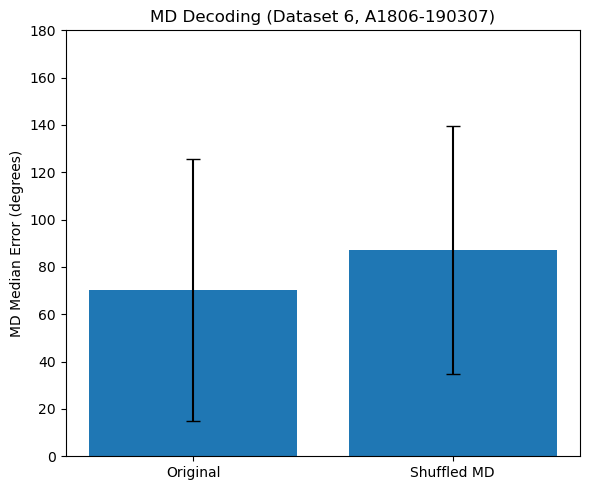

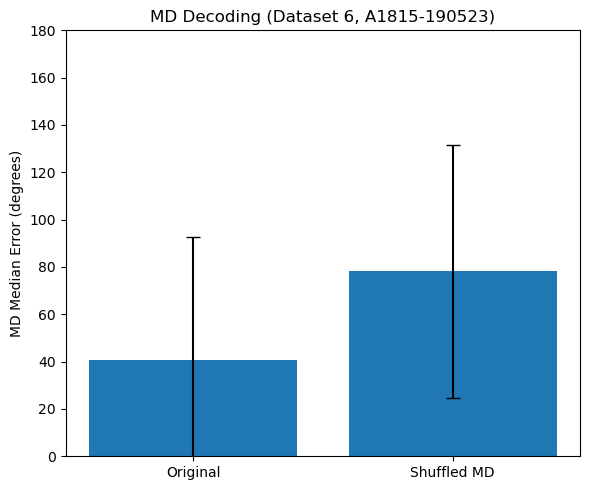

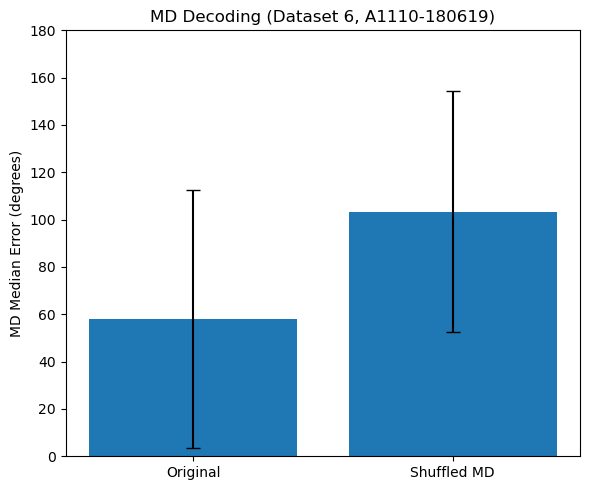

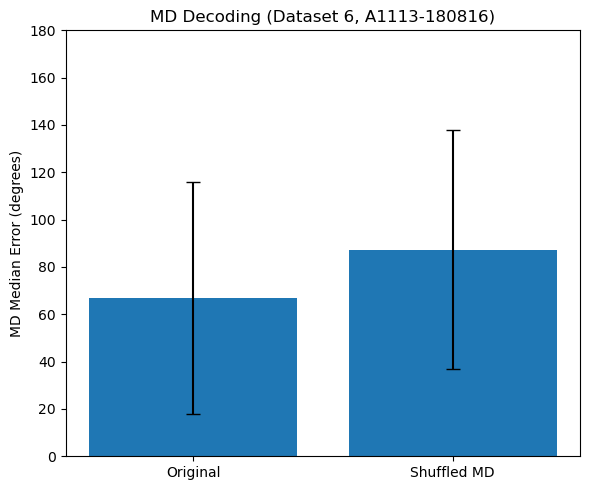

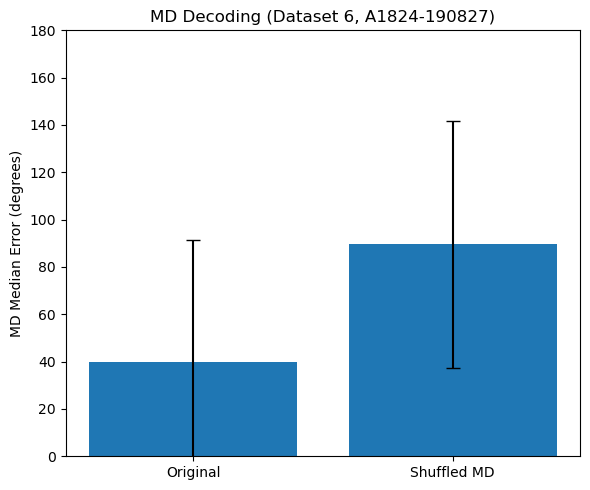

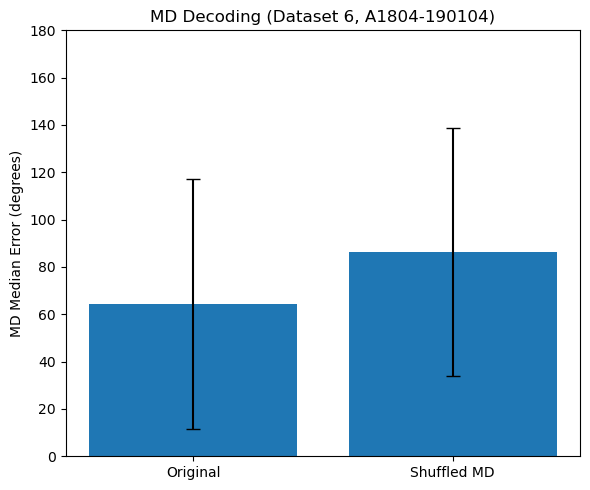

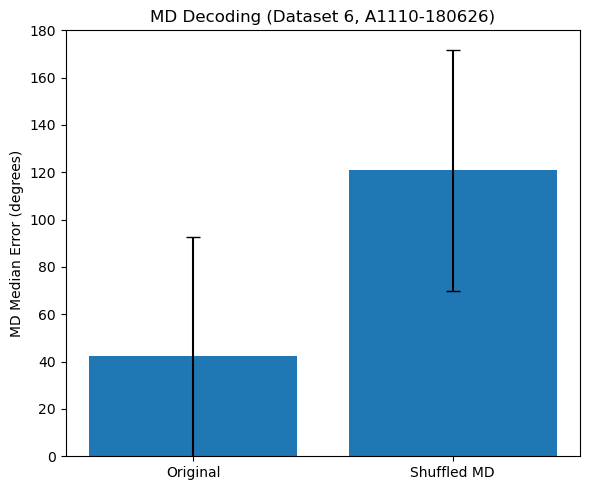

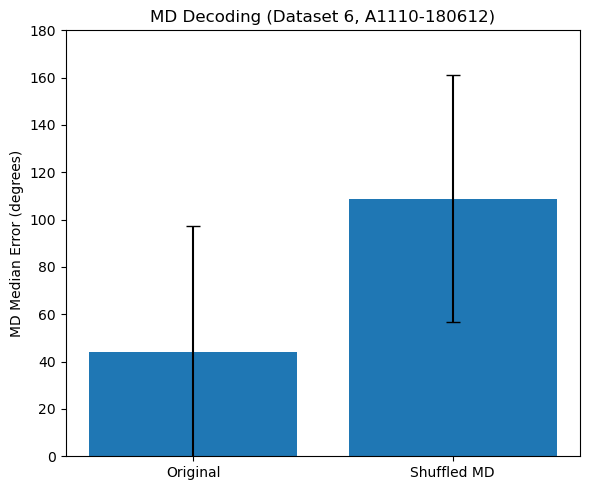

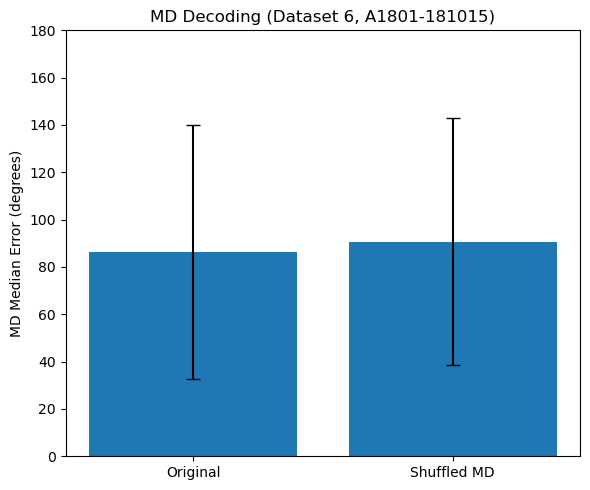

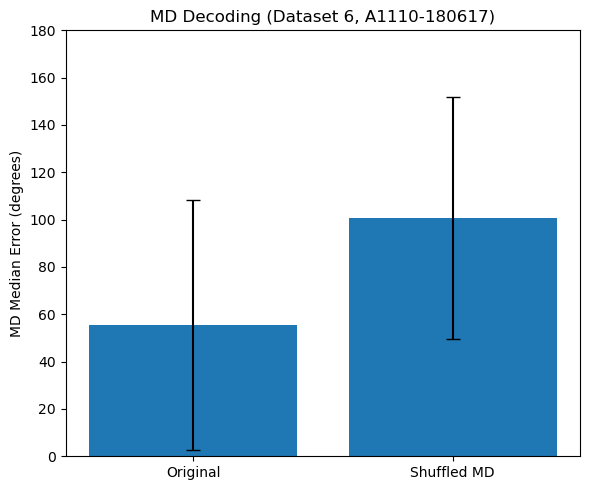

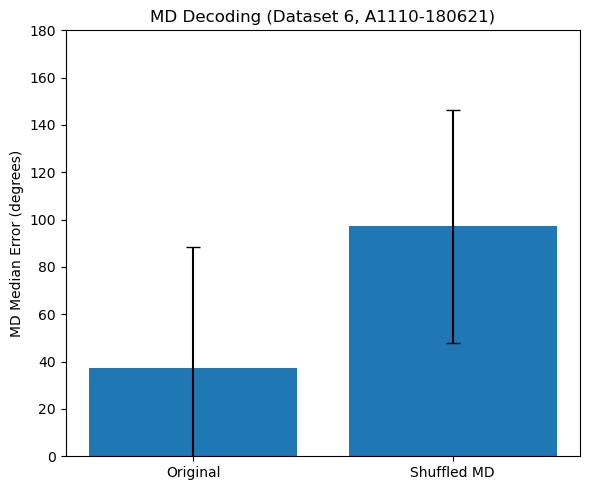

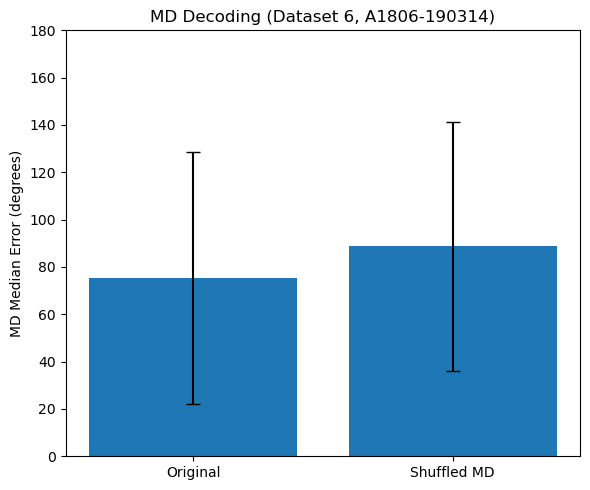

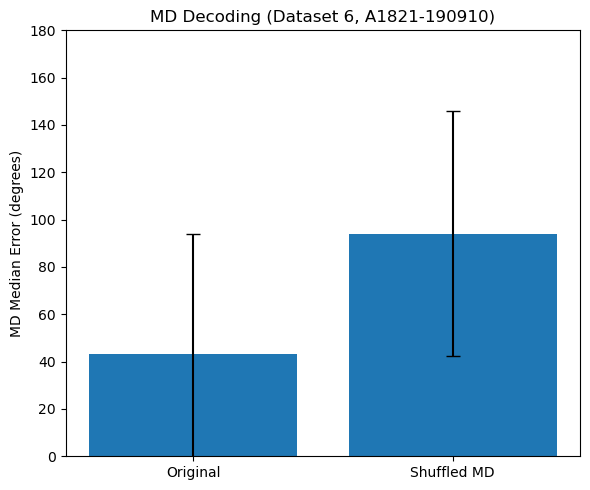

In [7]:
# =============================
# MD-only error analysis — Jupyter notebook cells
# (No overwrites: assumes helper defs like `extract_matlab_obj`,
#  `get_md_from_xy`, `circular_difference`, and `load_behavioral_data`
#  already exist in the notebook.)
# =============================

# --- Cell 1: Imports & parameters ---
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

for session in sessions:
    try:
        # Parameters (edit as needed)
        dataset = 'dusz'          # 'dusz' or 'pfeiffer'
        dataset_n = 6             # dataset number (e.g., 3)
        n_md_bins = 17
        num_folds = 4
        vel_threshold = 2.0
        smoothing_window = 200
        results_root = '/home/mag/variance-analysis/results/dusz'        # or e.g., Path('/home/mag/results/dusz')
        fig_out = Path(f'/home/mag/variance-analysis/figs/md_decoding_solo/Dataset_{dataset_n}/{session}.png')             # or e.g., Path('/home/mag/variance-analysis/figs/md_decoding_solo/R1.png')
        
        current_file_path = Path().resolve().parent
        results_root = Path(results_root) if results_root else (current_file_path / f"results/{dataset}")
        save_path = results_root / f"Dataset_{dataset_n}/{session}"
        
        
        # --- Cell 2: MD ground-truth helper (define only if missing) ---
        if 'compute_ground_truth_md' not in globals():
            def compute_ground_truth_md(positions, time_centers, velocity, velocity_filter, smoothing_window=200):
                """Compute ground-truth MD at time bin centers, with velocity filtering.
                Relies on existing `get_md_from_xy` helper.
                """
                timestamps = positions[:, 0]
                md = get_md_from_xy(positions, smoothing_window=smoothing_window)
                # Interpolate to decoder time centers
                ground_md_interp = (np.interp(time_centers, timestamps, md) + 360) % 360
                # Estimate velocity per center (±0.06 s window ~ 120 ms bins)
                velocity_interp = np.full(len(time_centers), np.nan)
                for i, t in enumerate(time_centers):
                    m = (velocity[:, 0] >= t - 0.06) & (velocity[:, 0] <= t + 0.06)
                    if np.any(m):
                        velocity_interp[i] = np.nanmean(velocity[m, 1])
                valid = (velocity_interp >= velocity_filter) & (~np.isnan(velocity_interp))
                ground_md_filtered = np.where(valid, ground_md_interp, np.nan)
                return ground_md_filtered
        
        
        # --- Cell 3: Core MD-only analysis (define only if missing) ---
        if 'analyze_cv_errors_md_only' not in globals():
            def analyze_cv_errors_md_only(save_path, positions, velocity, velocity_filter, n_md_bins=17, num_folds=4, shuffled_md=False, smoothing_window=200):
                """
                Analyze MD decoding errors across CV folds for the SOLO MD pipeline.
                Expects files saved by md_decoder_solo.py:
                  - decoded_md_{n_md_bins}_cv{cv}[_shuffled_md]_solo.npy
                  - time_centers_cv{cv}[_shuffled_md]_solo.npy
                Returns (error_stats, md_errors).
                """
                from pathlib import Path
                md_errors_all = []
                suffix = "_shuffled_md" if shuffled_md else ""
                for cv in range(num_folds):
                    dec_fp = Path(save_path) / f"decoded_md_{n_md_bins}_cv{cv}{suffix}_solo.npy"
                    tc_fp  = Path(save_path) / f"time_centers_cv{cv}{suffix}_solo.npy"
                    if not (dec_fp.exists() and tc_fp.exists()):
                        print(f"Warning: Missing files for CV {cv}: {dec_fp.name} or {tc_fp.name}")
                        continue
                    decoded_md = np.load(dec_fp)
                    time_centers_cv = np.load(tc_fp)
                    gt_md = compute_ground_truth_md(positions, time_centers_cv, velocity, velocity_filter, smoothing_window=smoothing_window)
                    print(f"  CV {cv}: {len(time_centers_cv)} test bins, valid MD bins: {np.sum(~np.isnan(gt_md))}")
                    md_error = circular_difference(decoded_md, gt_md)
                    md_errors_all.append(md_error)
                if not md_errors_all:
                    print("Error: No valid CV folds found for MD-only analysis.")
                    return None, None
                md_errors = np.concatenate(md_errors_all)
                error_stats = {
                    'md_mean_abs_error': np.nanmean(np.abs(md_errors)),
                    'md_median_abs_error': np.nanmedian(np.abs(md_errors)),
                    'md_std_error': np.nanstd(np.abs(md_errors)),
                    'md_mean_abs_error_pct': (np.nanmean(np.abs(md_errors)) / 180) * 100,
                    'md_median_abs_error_pct': (np.nanmedian(np.abs(md_errors)) / 180) * 100,
                    'total_samples': len(md_errors),
                    'md_valid_samples': np.sum(~np.isnan(md_errors)),
                }
                return error_stats, md_errors
        
        
        # --- Cell 4: Comparison helper (define only if missing) ---
        if 'compare_results_md' not in globals():
            def compare_results_md(stats_original, stats_shuffled):
                if stats_original is None or stats_shuffled is None:
                    return None
                return {
                    'md_error_change': stats_shuffled['md_mean_abs_error'] - stats_original['md_mean_abs_error'],
                    'md_error_ratio': stats_shuffled['md_mean_abs_error'] / stats_original['md_mean_abs_error'],
                    'md_destroyed': stats_shuffled['md_mean_abs_error'] > stats_original['md_mean_abs_error'] * 1.5,
                }
        
        
        # --- Cell 5: Load data (uses your existing `load_behavioral_data`) ---
        positions, velocity, _ = load_behavioral_data(
            current_file_path, dataset=dataset, dataset_n=dataset_n, session=session
        )
        
        
        # --- Cell 6: Run MD-only analysis (original vs shuffled) ---
        print("\nAnalyzing ORIGINAL MD decoding errors...")
        stats_orig, md_err_orig = analyze_cv_errors_md_only(
            save_path, positions, velocity, vel_threshold,
            n_md_bins=n_md_bins, num_folds=num_folds,
            shuffled_md=False, smoothing_window=smoothing_window
        )
        if stats_orig is not None:
            print(f"  MD Mean Error: {stats_orig['md_mean_abs_error']:.2f}° ({stats_orig['md_mean_abs_error_pct']:.1f}%)")
        
        print("\nAnalyzing SHUFFLED-MD decoding errors...")
        stats_shuf, md_err_shuf = analyze_cv_errors_md_only(
            save_path, positions, velocity, vel_threshold,
            n_md_bins=n_md_bins, num_folds=num_folds,
            shuffled_md=True, smoothing_window=smoothing_window
        )
        if stats_shuf is not None:
            print(f"  MD Mean Error (shuffled): {stats_shuf['md_mean_abs_error']:.2f}° ({stats_shuf['md_mean_abs_error_pct']:.1f}%)")
        
        
        # --- Cell 7: Print comparison & optional figure ---
        if (stats_orig is not None) and (stats_shuf is not None):
            comp = compare_results_md(stats_orig, stats_shuf)
            print("\n== COMPARISON (MD-only) ==")
            print(f"  MD Error Change: {comp['md_error_change']:+.2f}° (×{comp['md_error_ratio']:.2f})")
            if comp['md_destroyed']:
                print("  ✓ MD effectively destroyed by shuffle (ratio > 1.5x)")
            else:
                print("  ⚠ MD not sufficiently destroyed (ratio ≤ 1.5x)")
        
            if fig_out:
                fig, ax = plt.subplots(figsize=(6, 5))
                vals = [stats_orig['md_median_abs_error'], stats_shuf['md_median_abs_error']]
                stds = [stats_orig['md_std_error'], stats_shuf['md_std_error']]
                ax.bar([0, 1], vals, yerr=stds, capsize=5)
                ax.set_xticks([0, 1])
                ax.set_xticklabels(['Original', 'Shuffled MD'])
                ax.set_ylim(0, 180)
                ax.set_ylabel('MD Median Error (degrees)')
                ax.set_title(f'MD Decoding (Dataset {dataset_n}, {session})')
                plt.tight_layout()
                Path(fig_out).parent.mkdir(parents=True, exist_ok=True)
                plt.savefig(fig_out)
                print(f"Saved figure to {fig_out}")
            else:
                # quick inline bar if not saving
                fig, ax = plt.subplots(figsize=(6, 5))
                vals = [stats_orig['md_median_abs_error'], stats_shuf['md_median_abs_error']]
                stds = [stats_orig['md_std_error'], stats_shuf['md_std_error']]
                ax.bar([0, 1], vals, yerr=stds, capsize=5)
                ax.set_xticks([0, 1])
                ax.set_xticklabels(['Original', 'Shuffled MD'])
                ax.set_ylim(0, 180)
                ax.set_ylabel('MD Median Error (degrees)')
                ax.set_title(f'MD Decoding (Dataset {dataset_n}, {session})')
                plt.tight_layout()
                plt.show()
    except:
        continue

In [6]:
num_folds = 4


Session: A1806-190307

Analyzing ORIGINAL decoding errors...

[ORIGINAL RESULTS]
  HD Mean Error: 60.59° (33.7%)
  MD Mean Error: 93.32° (51.8%)
  Valid samples: HD=6638, MD=6638

Analyzing MD-SHUFFLED decoding errors...

[MD-SHUFFLED RESULTS]
  HD Mean Error: 60.35° (33.5%)
  MD Mean Error: 91.14° (50.6%)
  Valid samples: HD=6638, MD=6638

COMPARISON RESULTS
  HD Error Change: -0.24° (×1.00)
  MD Error Change: -2.18° (×0.98)

[INTERPRETATION]
  ⚠ PARTIAL EVIDENCE for HD selectivity:
    - HD decoding remains accurate
    - But MD decoding not sufficiently impaired
    → Possible residual MD information or insufficient shuffling


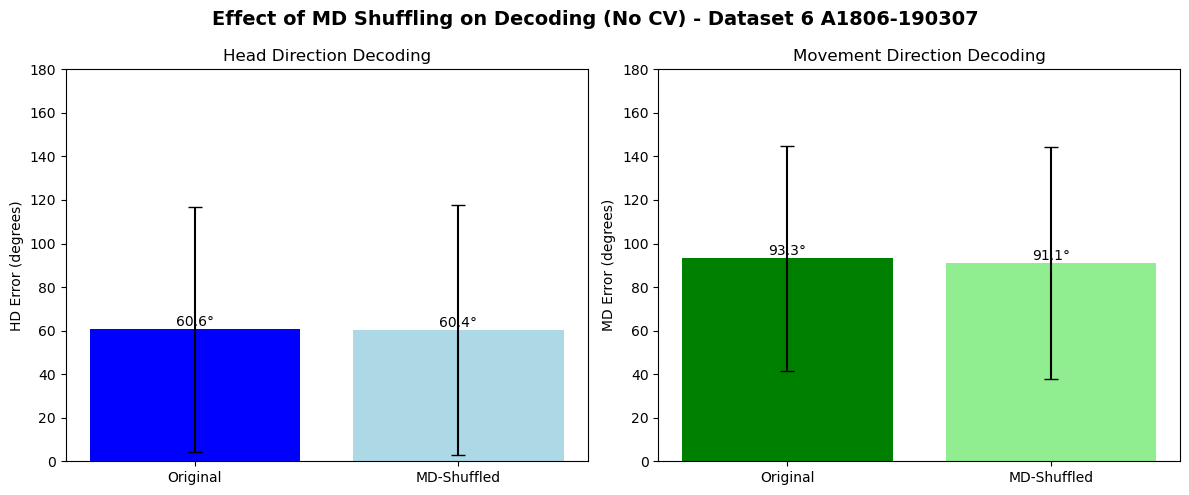


Session: A1815-190523

Analyzing ORIGINAL decoding errors...

[ORIGINAL RESULTS]
  HD Mean Error: 15.89° (8.8%)
  MD Mean Error: 87.62° (48.7%)
  Valid samples: HD=6988, MD=6988

Analyzing MD-SHUFFLED decoding errors...

[MD-SHUFFLED RESULTS]
  HD Mean Error: 15.87° (8.8%)
  MD Mean Error: 91.53° (50.8%)
  Valid samples: HD=6988, MD=6988

COMPARISON RESULTS
  HD Error Change: -0.02° (×1.00)
  MD Error Change: +3.91° (×1.04)

[INTERPRETATION]
  ⚠ PARTIAL EVIDENCE for HD selectivity:
    - HD decoding remains accurate
    - But MD decoding not sufficiently impaired
    → Possible residual MD information or insufficient shuffling


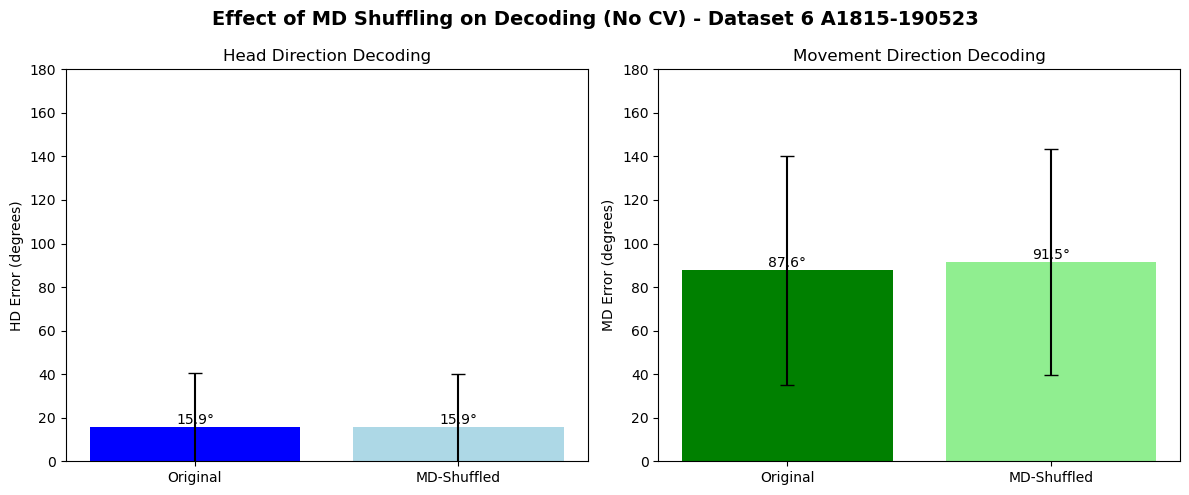


Session: A1110-180619

Analyzing ORIGINAL decoding errors...

[ORIGINAL RESULTS]
  HD Mean Error: 30.34° (16.9%)
  MD Mean Error: 92.27° (51.3%)
  Valid samples: HD=7359, MD=7359

Analyzing MD-SHUFFLED decoding errors...

[MD-SHUFFLED RESULTS]
  HD Mean Error: 29.90° (16.6%)
  MD Mean Error: 86.99° (48.3%)
  Valid samples: HD=7359, MD=7359

COMPARISON RESULTS
  HD Error Change: -0.44° (×0.99)
  MD Error Change: -5.28° (×0.94)

[INTERPRETATION]
  ⚠ PARTIAL EVIDENCE for HD selectivity:
    - HD decoding remains accurate
    - But MD decoding not sufficiently impaired
    → Possible residual MD information or insufficient shuffling


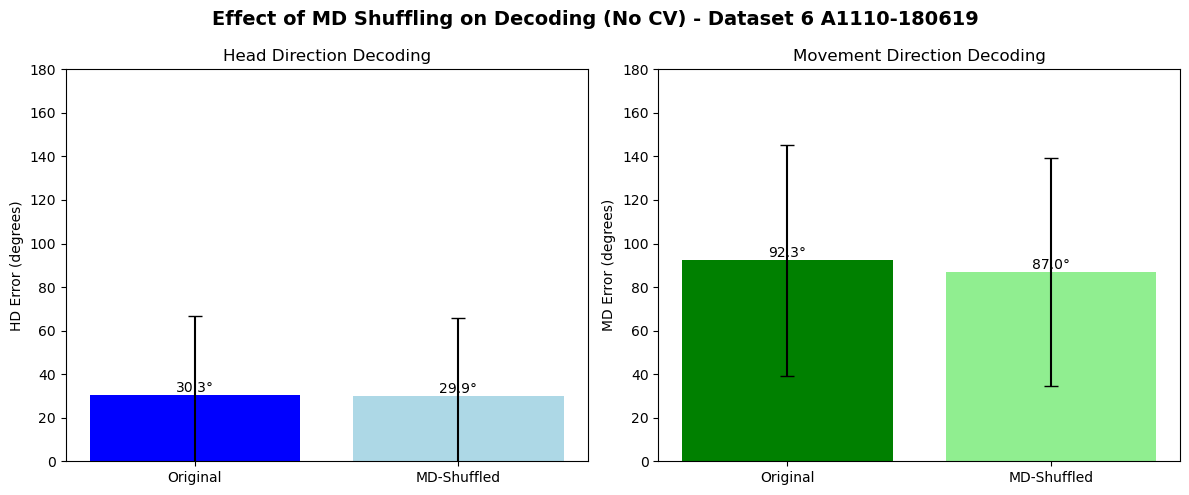


Session: A1113-180816

Analyzing ORIGINAL decoding errors...

[ORIGINAL RESULTS]
  HD Mean Error: 66.21° (36.8%)
  MD Mean Error: 89.75° (49.9%)
  Valid samples: HD=7811, MD=7811

Analyzing MD-SHUFFLED decoding errors...

[MD-SHUFFLED RESULTS]
  HD Mean Error: 65.94° (36.6%)
  MD Mean Error: 94.38° (52.4%)
  Valid samples: HD=7811, MD=7811

COMPARISON RESULTS
  HD Error Change: -0.28° (×1.00)
  MD Error Change: +4.63° (×1.05)

[INTERPRETATION]
  ⚠ PARTIAL EVIDENCE for HD selectivity:
    - HD decoding remains accurate
    - But MD decoding not sufficiently impaired
    → Possible residual MD information or insufficient shuffling


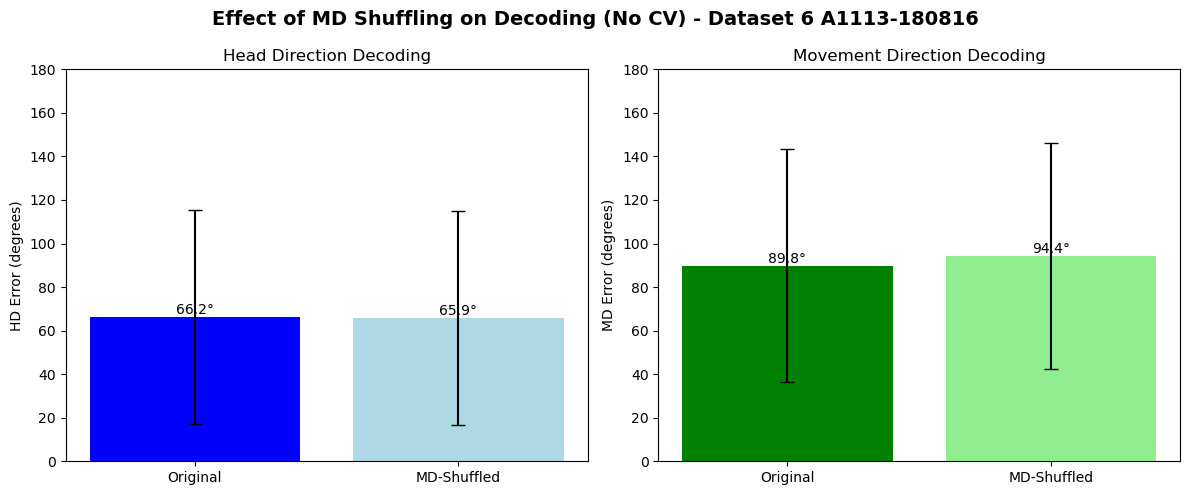


Session: A1824-190827

Analyzing ORIGINAL decoding errors...

[ORIGINAL RESULTS]
  HD Mean Error: 14.21° (7.9%)
  MD Mean Error: 88.62° (49.2%)
  Valid samples: HD=9144, MD=9144

Analyzing MD-SHUFFLED decoding errors...

[MD-SHUFFLED RESULTS]
  HD Mean Error: 14.39° (8.0%)
  MD Mean Error: 89.34° (49.6%)
  Valid samples: HD=9144, MD=9144

COMPARISON RESULTS
  HD Error Change: +0.18° (×1.01)
  MD Error Change: +0.73° (×1.01)

[INTERPRETATION]
  ⚠ PARTIAL EVIDENCE for HD selectivity:
    - HD decoding remains accurate
    - But MD decoding not sufficiently impaired
    → Possible residual MD information or insufficient shuffling


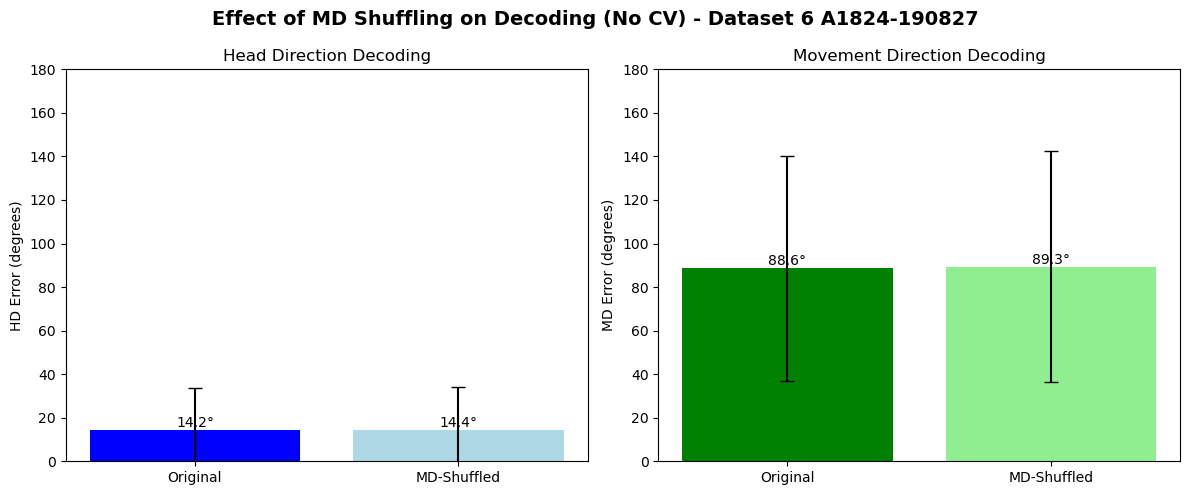


Session: A1804-190104

Analyzing ORIGINAL decoding errors...

[ORIGINAL RESULTS]
  HD Mean Error: 40.29° (22.4%)
  MD Mean Error: 92.91° (51.6%)
  Valid samples: HD=6591, MD=6591

Analyzing MD-SHUFFLED decoding errors...

[MD-SHUFFLED RESULTS]
  HD Mean Error: 39.48° (21.9%)
  MD Mean Error: 87.46° (48.6%)
  Valid samples: HD=6591, MD=6591

COMPARISON RESULTS
  HD Error Change: -0.81° (×0.98)
  MD Error Change: -5.44° (×0.94)

[INTERPRETATION]
  ⚠ PARTIAL EVIDENCE for HD selectivity:
    - HD decoding remains accurate
    - But MD decoding not sufficiently impaired
    → Possible residual MD information or insufficient shuffling


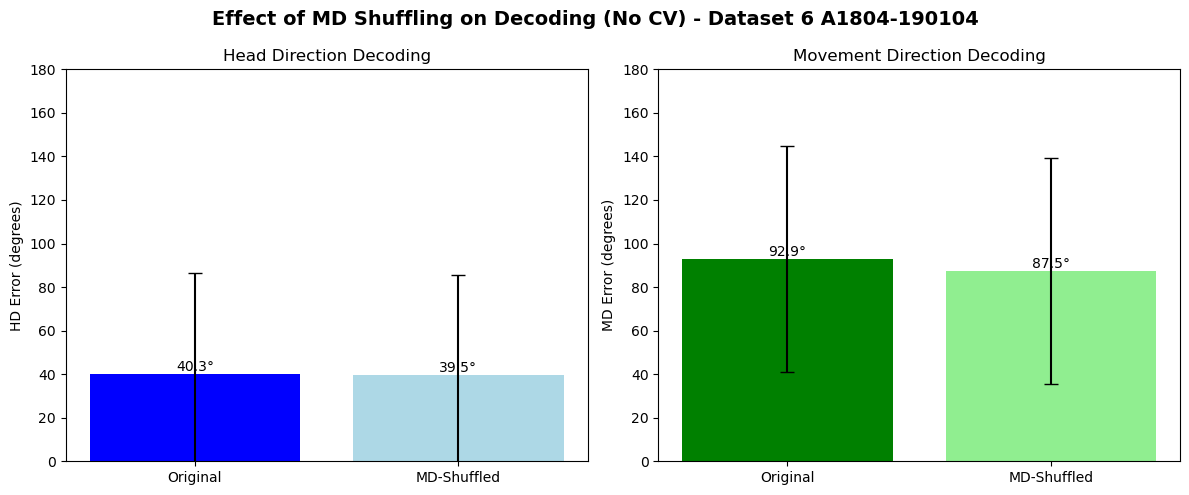


Session: A1110-180626

Analyzing ORIGINAL decoding errors...

[ORIGINAL RESULTS]
  HD Mean Error: 28.98° (16.1%)
  MD Mean Error: 93.49° (51.9%)
  Valid samples: HD=9635, MD=9635

Analyzing MD-SHUFFLED decoding errors...

[MD-SHUFFLED RESULTS]
  HD Mean Error: 28.35° (15.8%)
  MD Mean Error: 84.69° (47.0%)
  Valid samples: HD=9635, MD=9635

COMPARISON RESULTS
  HD Error Change: -0.63° (×0.98)
  MD Error Change: -8.81° (×0.91)

[INTERPRETATION]
  ⚠ PARTIAL EVIDENCE for HD selectivity:
    - HD decoding remains accurate
    - But MD decoding not sufficiently impaired
    → Possible residual MD information or insufficient shuffling


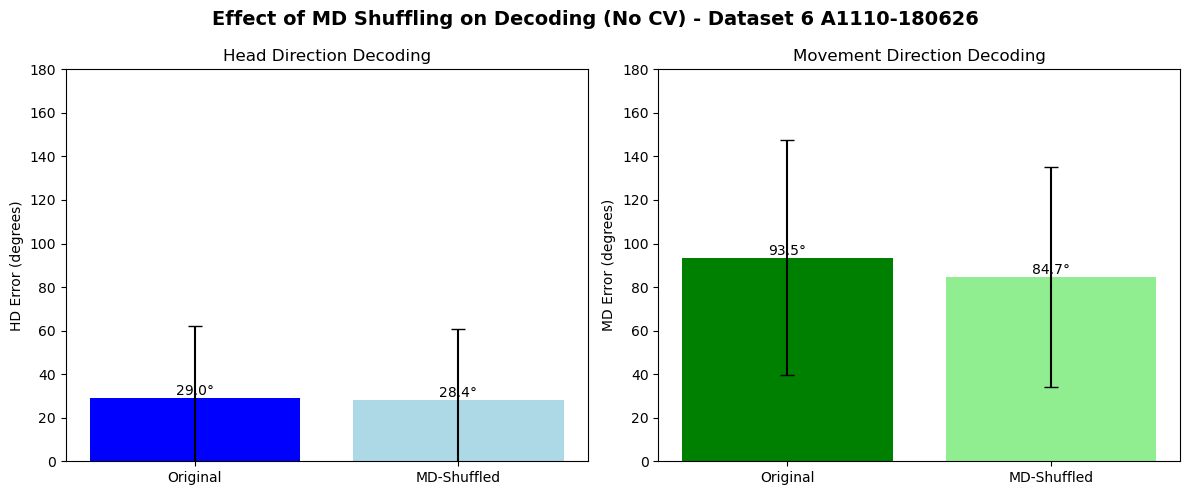


Session: A1110-180612

Analyzing ORIGINAL decoding errors...

[ORIGINAL RESULTS]
  HD Mean Error: 41.02° (22.8%)
  MD Mean Error: 98.41° (54.7%)
  Valid samples: HD=7714, MD=7714

Analyzing MD-SHUFFLED decoding errors...

[MD-SHUFFLED RESULTS]
  HD Mean Error: 40.03° (22.2%)
  MD Mean Error: 100.80° (56.0%)
  Valid samples: HD=7714, MD=7714

COMPARISON RESULTS
  HD Error Change: -0.99° (×0.98)
  MD Error Change: +2.38° (×1.02)

[INTERPRETATION]
  ⚠ PARTIAL EVIDENCE for HD selectivity:
    - HD decoding remains accurate
    - But MD decoding not sufficiently impaired
    → Possible residual MD information or insufficient shuffling


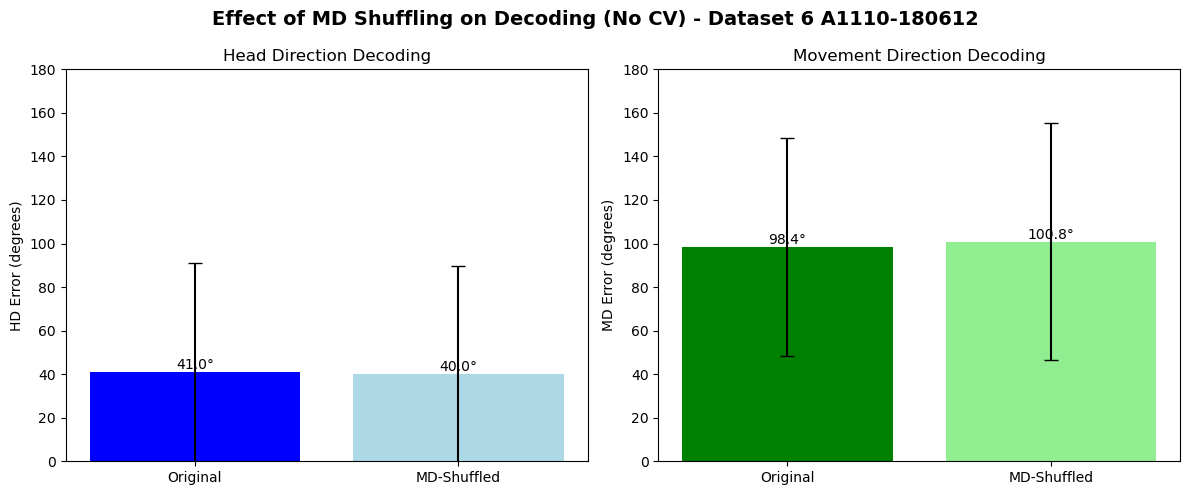


Session: A1801-181015

Analyzing ORIGINAL decoding errors...

[ORIGINAL RESULTS]
  HD Mean Error: 88.87° (49.4%)
  MD Mean Error: 93.57° (52.0%)
  Valid samples: HD=7132, MD=7132

Analyzing MD-SHUFFLED decoding errors...

[MD-SHUFFLED RESULTS]
  HD Mean Error: 89.93° (50.0%)
  MD Mean Error: 95.15° (52.9%)
  Valid samples: HD=7132, MD=7132

COMPARISON RESULTS
  HD Error Change: +1.06° (×1.01)
  MD Error Change: +1.58° (×1.02)

[INTERPRETATION]
  ⚠ PARTIAL EVIDENCE for HD selectivity:
    - HD decoding remains accurate
    - But MD decoding not sufficiently impaired
    → Possible residual MD information or insufficient shuffling


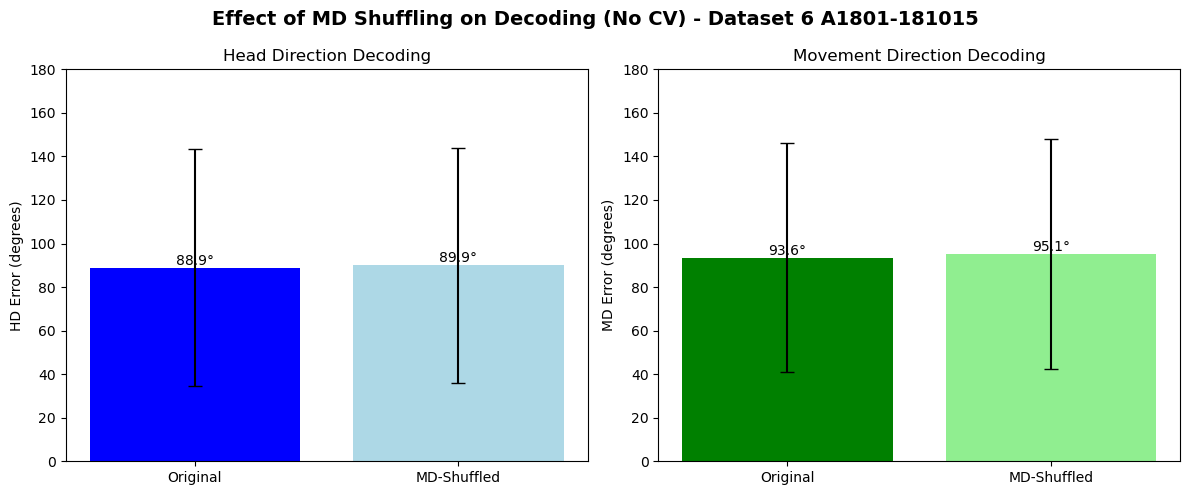


Session: A1110-180617

Analyzing ORIGINAL decoding errors...

[ORIGINAL RESULTS]
  HD Mean Error: 29.51° (16.4%)
  MD Mean Error: 95.50° (53.1%)
  Valid samples: HD=7715, MD=7715

Analyzing MD-SHUFFLED decoding errors...

[MD-SHUFFLED RESULTS]
  HD Mean Error: 27.04° (15.0%)
  MD Mean Error: 93.05° (51.7%)
  Valid samples: HD=7715, MD=7715

COMPARISON RESULTS
  HD Error Change: -2.47° (×0.92)
  MD Error Change: -2.45° (×0.97)

[INTERPRETATION]
  ⚠ PARTIAL EVIDENCE for HD selectivity:
    - HD decoding remains accurate
    - But MD decoding not sufficiently impaired
    → Possible residual MD information or insufficient shuffling


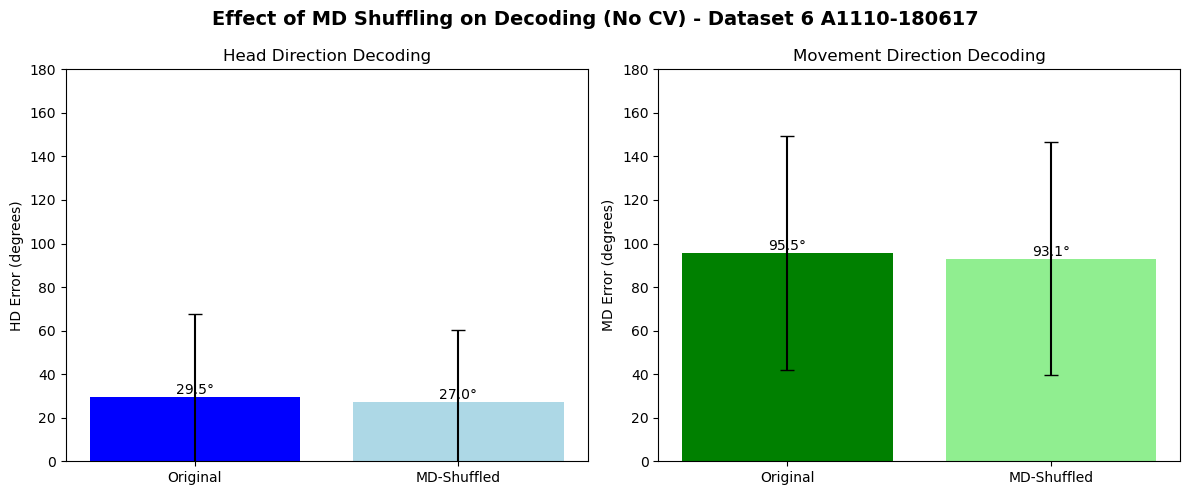


Session: A1110-180621

Analyzing ORIGINAL decoding errors...

[ORIGINAL RESULTS]
  HD Mean Error: 18.90° (10.5%)
  MD Mean Error: 92.93° (51.6%)
  Valid samples: HD=9851, MD=9851

Analyzing MD-SHUFFLED decoding errors...

[MD-SHUFFLED RESULTS]
  HD Mean Error: 18.85° (10.5%)
  MD Mean Error: 88.96° (49.4%)
  Valid samples: HD=9851, MD=9851

COMPARISON RESULTS
  HD Error Change: -0.06° (×1.00)
  MD Error Change: -3.97° (×0.96)

[INTERPRETATION]
  ⚠ PARTIAL EVIDENCE for HD selectivity:
    - HD decoding remains accurate
    - But MD decoding not sufficiently impaired
    → Possible residual MD information or insufficient shuffling


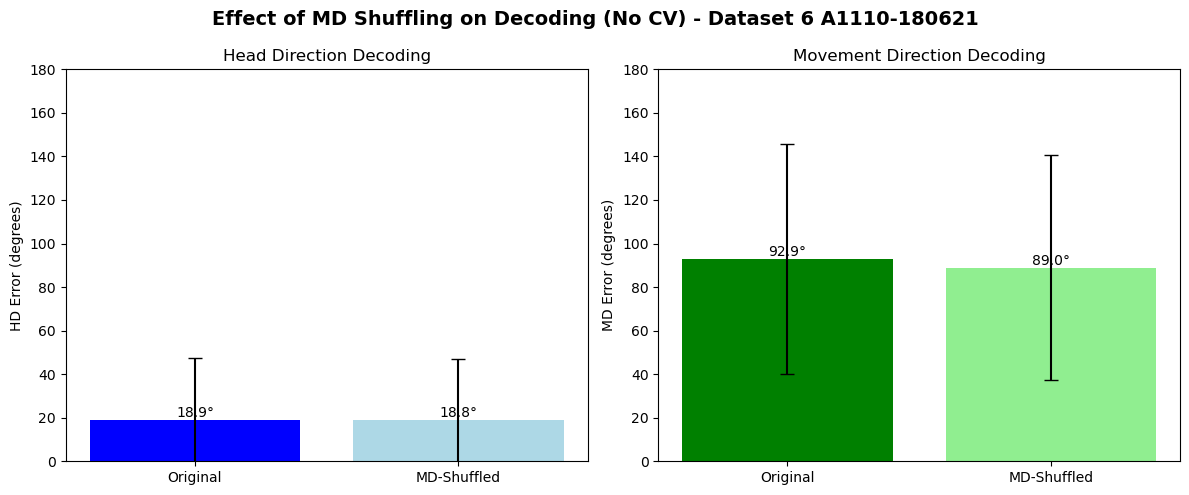


Session: A1806-190314

Analyzing ORIGINAL decoding errors...

[ORIGINAL RESULTS]
  HD Mean Error: 78.32° (43.5%)
  MD Mean Error: 89.24° (49.6%)
  Valid samples: HD=10096, MD=10096

Analyzing MD-SHUFFLED decoding errors...

[MD-SHUFFLED RESULTS]
  HD Mean Error: 77.34° (43.0%)
  MD Mean Error: 93.12° (51.7%)
  Valid samples: HD=10096, MD=10096

COMPARISON RESULTS
  HD Error Change: -0.98° (×0.99)
  MD Error Change: +3.87° (×1.04)

[INTERPRETATION]
  ⚠ PARTIAL EVIDENCE for HD selectivity:
    - HD decoding remains accurate
    - But MD decoding not sufficiently impaired
    → Possible residual MD information or insufficient shuffling


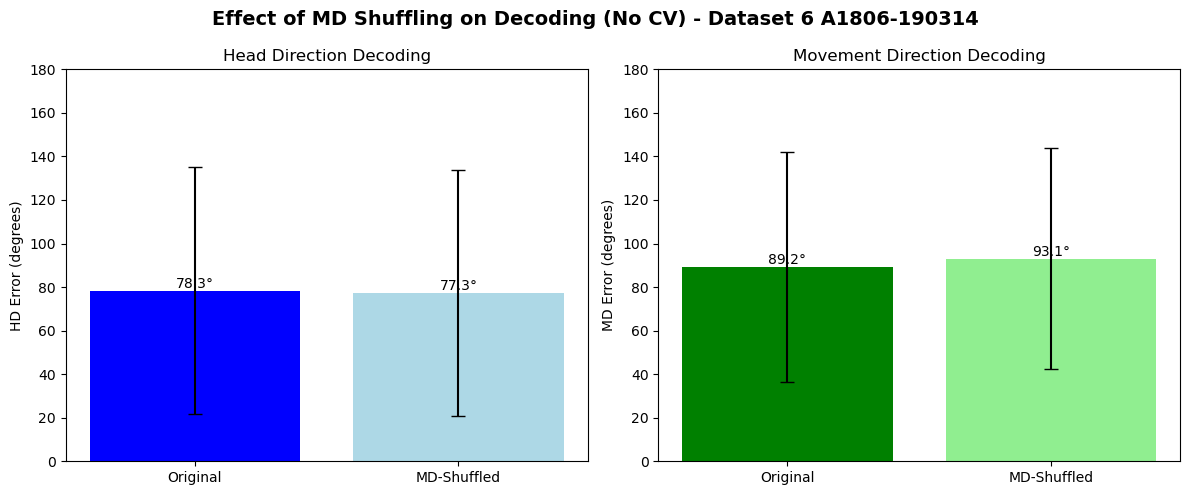


Session: A1821-190910

Analyzing ORIGINAL decoding errors...

[ORIGINAL RESULTS]
  HD Mean Error: 15.21° (8.5%)
  MD Mean Error: 87.79° (48.8%)
  Valid samples: HD=20387, MD=20387

Analyzing MD-SHUFFLED decoding errors...

[MD-SHUFFLED RESULTS]
  HD Mean Error: 15.39° (8.6%)
  MD Mean Error: 88.11° (49.0%)
  Valid samples: HD=20387, MD=20387

COMPARISON RESULTS
  HD Error Change: +0.18° (×1.01)
  MD Error Change: +0.32° (×1.00)

[INTERPRETATION]
  ⚠ PARTIAL EVIDENCE for HD selectivity:
    - HD decoding remains accurate
    - But MD decoding not sufficiently impaired
    → Possible residual MD information or insufficient shuffling


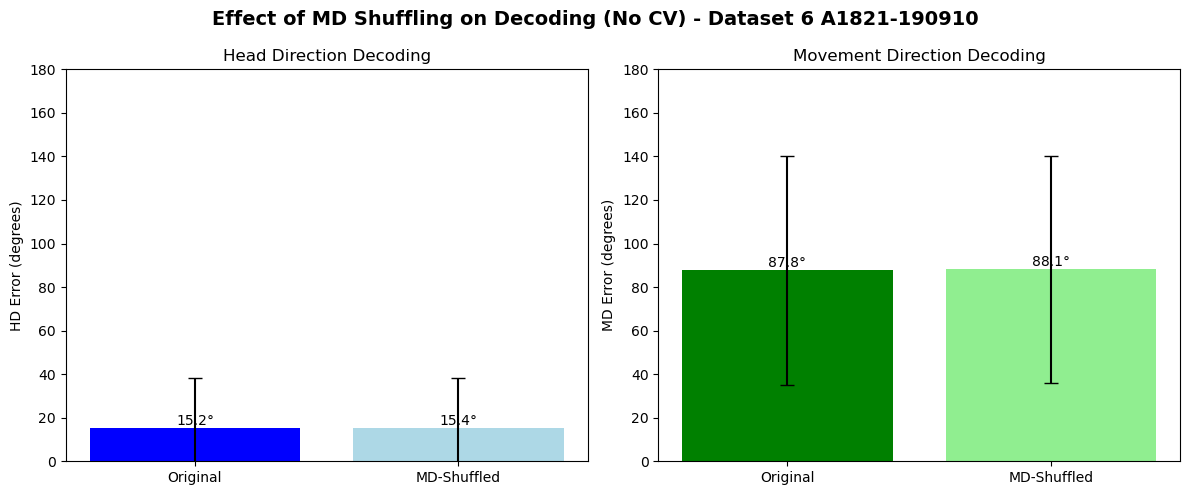


Session: A1808-190807

Analyzing ORIGINAL decoding errors...

[ORIGINAL RESULTS]
  HD Mean Error: 13.57° (7.5%)
  MD Mean Error: 89.61° (49.8%)
  Valid samples: HD=6550, MD=6550

Analyzing MD-SHUFFLED decoding errors...

[MD-SHUFFLED RESULTS]
  HD Mean Error: 13.59° (7.5%)
  MD Mean Error: 90.26° (50.1%)
  Valid samples: HD=6550, MD=6550

COMPARISON RESULTS
  HD Error Change: +0.02° (×1.00)
  MD Error Change: +0.65° (×1.01)

[INTERPRETATION]
  ⚠ PARTIAL EVIDENCE for HD selectivity:
    - HD decoding remains accurate
    - But MD decoding not sufficiently impaired
    → Possible residual MD information or insufficient shuffling


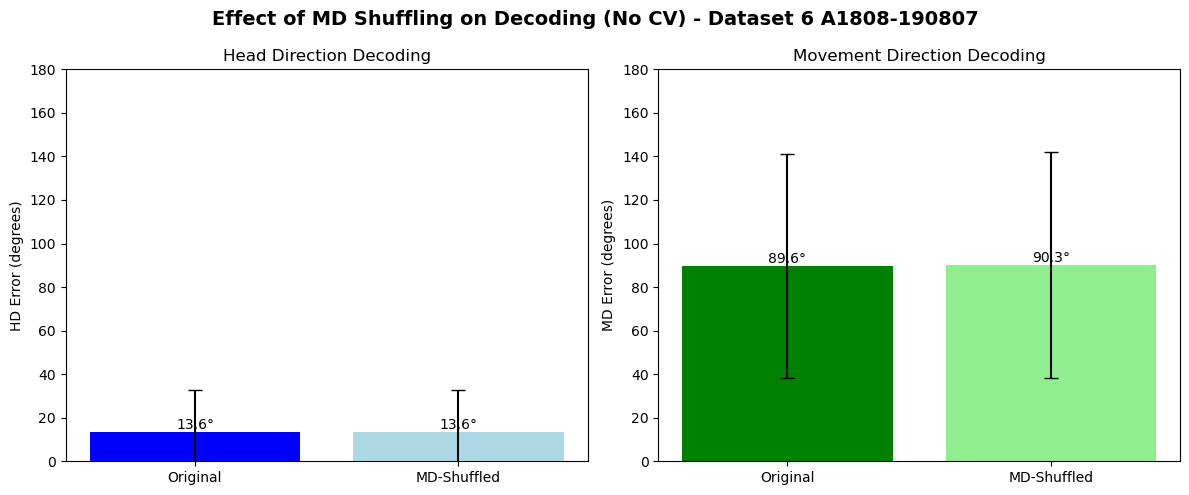


Session: A1113-180813

Analyzing ORIGINAL decoding errors...

[ORIGINAL RESULTS]
  HD Mean Error: 49.79° (27.7%)
  MD Mean Error: 95.29° (52.9%)
  Valid samples: HD=7814, MD=7814

Analyzing MD-SHUFFLED decoding errors...

[MD-SHUFFLED RESULTS]
  HD Mean Error: 48.99° (27.2%)
  MD Mean Error: 89.08° (49.5%)
  Valid samples: HD=7814, MD=7814

COMPARISON RESULTS
  HD Error Change: -0.81° (×0.98)
  MD Error Change: -6.21° (×0.93)

[INTERPRETATION]
  ⚠ PARTIAL EVIDENCE for HD selectivity:
    - HD decoding remains accurate
    - But MD decoding not sufficiently impaired
    → Possible residual MD information or insufficient shuffling


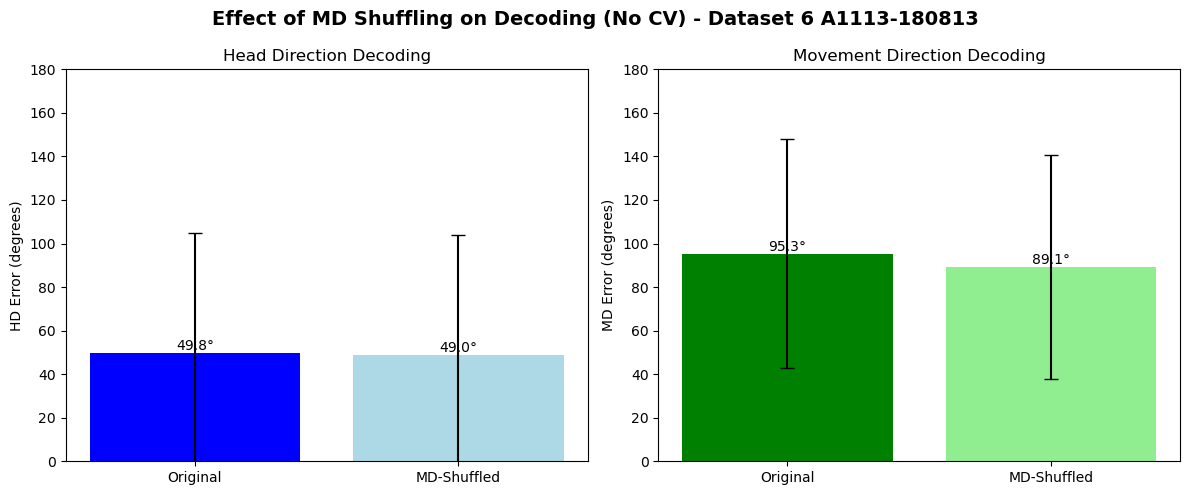


Session: A1813-190408

Analyzing ORIGINAL decoding errors...

[ORIGINAL RESULTS]
  HD Mean Error: 20.66° (11.5%)
  MD Mean Error: 91.07° (50.6%)
  Valid samples: HD=6804, MD=6804

Analyzing MD-SHUFFLED decoding errors...

[MD-SHUFFLED RESULTS]
  HD Mean Error: 20.24° (11.2%)
  MD Mean Error: 89.65° (49.8%)
  Valid samples: HD=6804, MD=6804

COMPARISON RESULTS
  HD Error Change: -0.41° (×0.98)
  MD Error Change: -1.42° (×0.98)

[INTERPRETATION]
  ⚠ PARTIAL EVIDENCE for HD selectivity:
    - HD decoding remains accurate
    - But MD decoding not sufficiently impaired
    → Possible residual MD information or insufficient shuffling


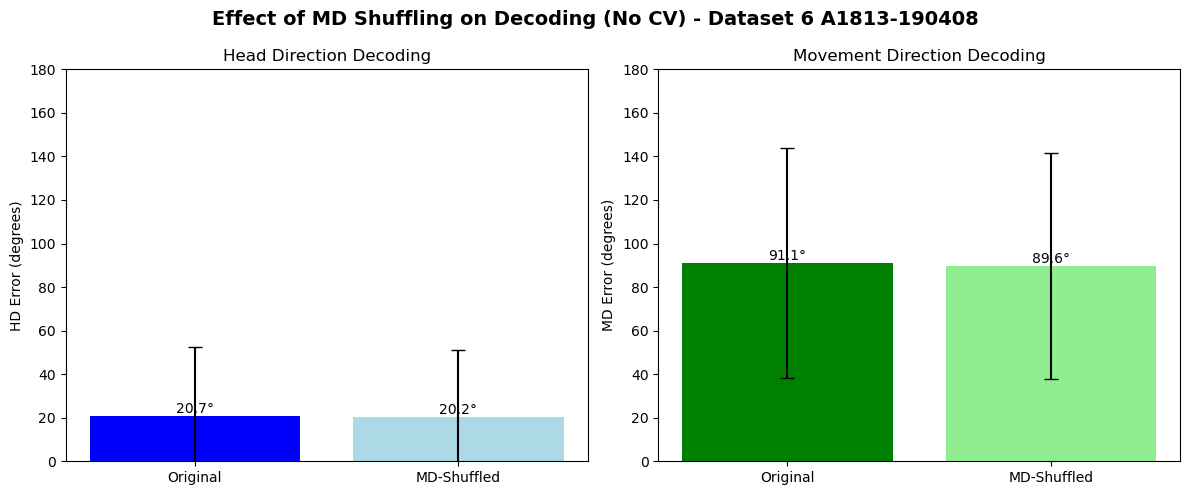


Session: A1106-180418

Analyzing ORIGINAL decoding errors...

[ORIGINAL RESULTS]
  HD Mean Error: 58.36° (32.4%)
  MD Mean Error: 93.11° (51.7%)
  Valid samples: HD=5508, MD=5508

Analyzing MD-SHUFFLED decoding errors...

[MD-SHUFFLED RESULTS]
  HD Mean Error: 58.84° (32.7%)
  MD Mean Error: 90.39° (50.2%)
  Valid samples: HD=5508, MD=5508

COMPARISON RESULTS
  HD Error Change: +0.47° (×1.01)
  MD Error Change: -2.72° (×0.97)

[INTERPRETATION]
  ⚠ PARTIAL EVIDENCE for HD selectivity:
    - HD decoding remains accurate
    - But MD decoding not sufficiently impaired
    → Possible residual MD information or insufficient shuffling


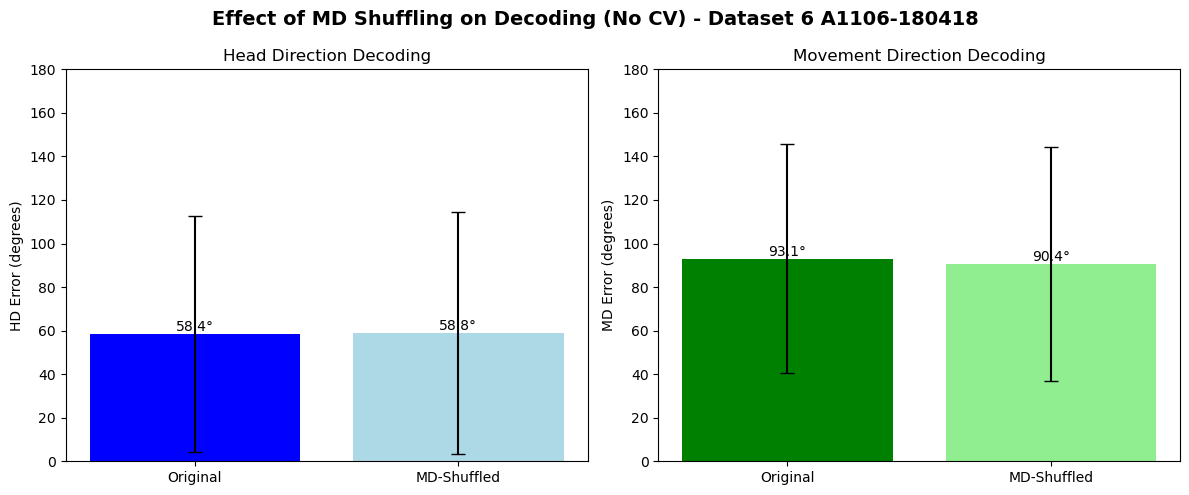


Session: A1801-181004

Analyzing ORIGINAL decoding errors...

[ORIGINAL RESULTS]
  HD Mean Error: 38.70° (21.5%)
  MD Mean Error: 92.39° (51.3%)
  Valid samples: HD=7308, MD=7308

Analyzing MD-SHUFFLED decoding errors...

[MD-SHUFFLED RESULTS]
  HD Mean Error: 36.81° (20.5%)
  MD Mean Error: 88.65° (49.3%)
  Valid samples: HD=7308, MD=7308

COMPARISON RESULTS
  HD Error Change: -1.89° (×0.95)
  MD Error Change: -3.73° (×0.96)

[INTERPRETATION]
  ⚠ PARTIAL EVIDENCE for HD selectivity:
    - HD decoding remains accurate
    - But MD decoding not sufficiently impaired
    → Possible residual MD information or insufficient shuffling


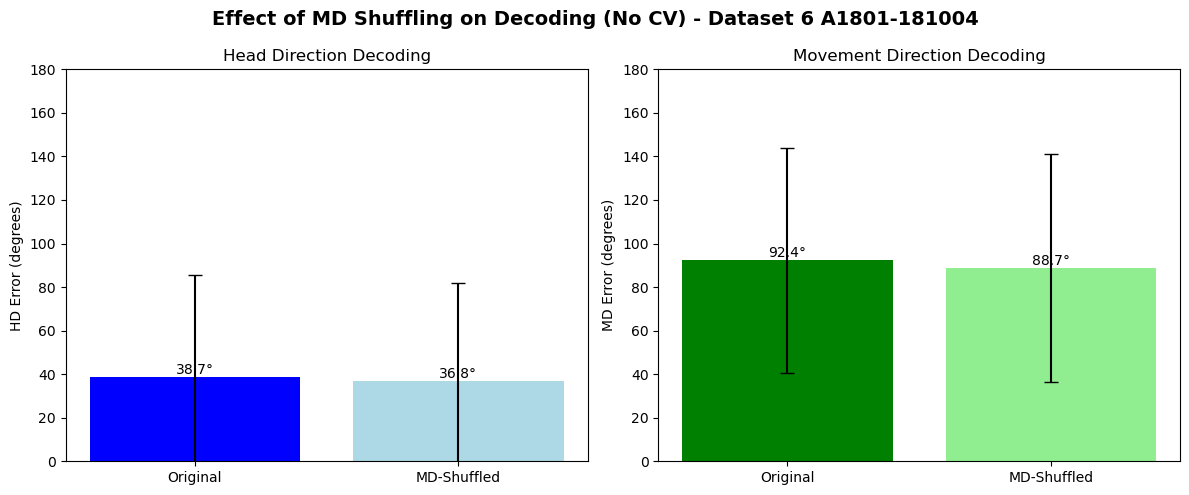


Session: A1804-181225

Analyzing ORIGINAL decoding errors...

[ORIGINAL RESULTS]
  HD Mean Error: 74.96° (41.6%)
  MD Mean Error: 89.65° (49.8%)
  Valid samples: HD=6721, MD=6721

Analyzing MD-SHUFFLED decoding errors...

[MD-SHUFFLED RESULTS]
  HD Mean Error: 75.98° (42.2%)
  MD Mean Error: 88.84° (49.4%)
  Valid samples: HD=6721, MD=6721

COMPARISON RESULTS
  HD Error Change: +1.02° (×1.01)
  MD Error Change: -0.81° (×0.99)

[INTERPRETATION]
  ⚠ PARTIAL EVIDENCE for HD selectivity:
    - HD decoding remains accurate
    - But MD decoding not sufficiently impaired
    → Possible residual MD information or insufficient shuffling


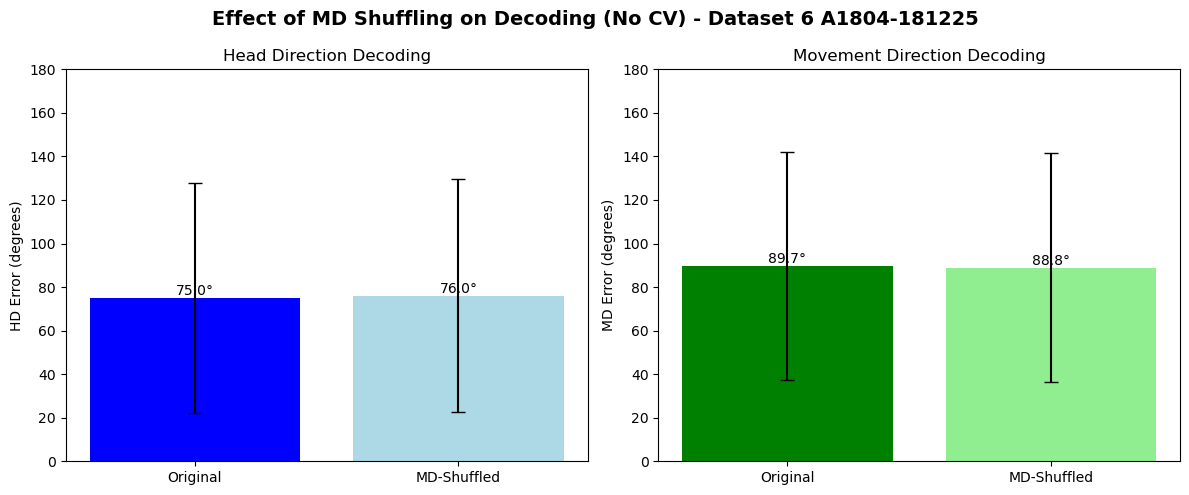


Session: A1106-180419

Analyzing ORIGINAL decoding errors...

[ORIGINAL RESULTS]
  HD Mean Error: 73.72° (41.0%)
  MD Mean Error: 89.23° (49.6%)
  Valid samples: HD=2221, MD=2221

Analyzing MD-SHUFFLED decoding errors...

[MD-SHUFFLED RESULTS]
  HD Mean Error: 46.09° (25.6%)
  MD Mean Error: 93.82° (52.1%)
  Valid samples: HD=2221, MD=2221

COMPARISON RESULTS
  HD Error Change: -27.63° (×0.63)
  MD Error Change: +4.59° (×1.05)

[INTERPRETATION]
  ⚠ PARTIAL EVIDENCE for HD selectivity:
    - HD decoding remains accurate
    - But MD decoding not sufficiently impaired
    → Possible residual MD information or insufficient shuffling


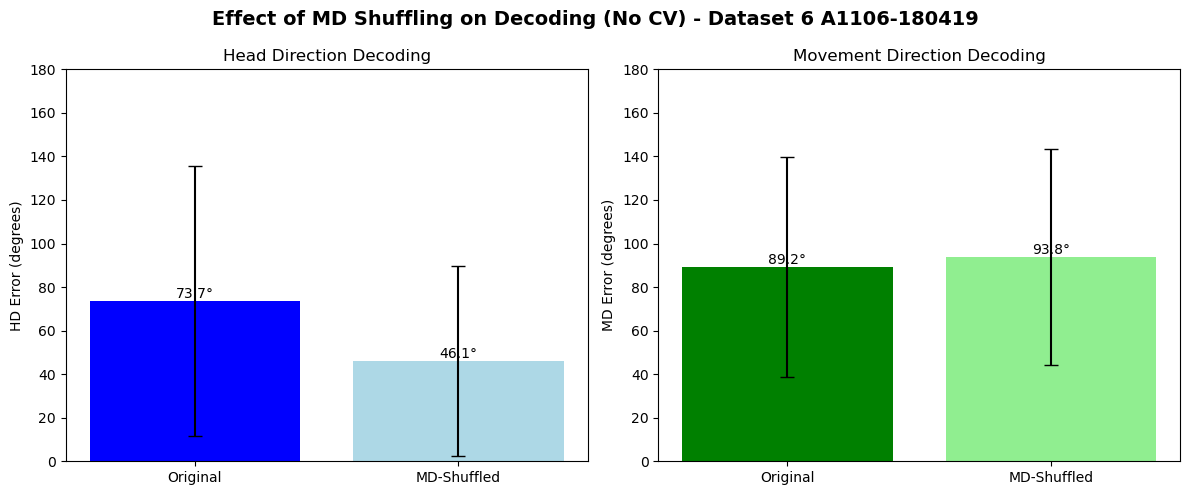


Session: A1110-180613

Analyzing ORIGINAL decoding errors...


In [ ]:
# Analysis code for Jupyter notebook - no cross-validation
import numpy as np
import matplotlib.pyplot as plt
from scipy.io import loadmat
from scipy.io.matlab._mio5_params import mat_struct
import pandas as pd
from pathlib import Path

# ============================================
# Helper Functions
# ============================================

def extract_matlab_obj(obj):
    if not (isinstance(obj, mat_struct) or isinstance(obj, dict)):
        return obj

    out = {}
    obj = obj.__dict__ if isinstance(obj, mat_struct) else obj

    for key, val in obj.items():
        if key in ['_fieldnames', 'type', 'time_unit', 'data_unit', 'name']:
            continue

        if isinstance(val, (mat_struct, dict)):
            out[key] = extract_matlab_obj(val)
        elif isinstance(val, np.ndarray):
            arr = [extract_matlab_obj(v) for v in val]
            out[key] = np.array(arr)
        else:
            out[key] = val

    return out

def circular_difference(decoded, ground_truth):
    diff = (decoded - ground_truth + 180) % 360 - 180
    return diff

def get_md_from_xy(positions, smoothing_window=75):
    """Compute MD using same method as decode script"""
    def rolling_mean(positions):
        kernel = np.ones(smoothing_window) / smoothing_window
        return np.convolve(positions, kernel, mode='same')
    
    x = rolling_mean(positions[:, 1])
    y = rolling_mean(positions[:, 2])
    
    dx = x[1:] - x[:-1]
    dy = y[1:] - y[:-1]
    
    direction = np.degrees(np.arctan2(-dy, dx))
    direction = (direction + 360) % 360
    
    direction = np.concatenate([direction, [direction[-1]]])
    
    return direction

def load_behavioral_data(current_file_path, dataset_n, session):
    data_path = current_file_path / f"data/dusz/Dataset_{dataset_n}/{session}/Data"
    
    # Load tracking data
    tracking_data = pd.read_csv(data_path / "Tracking_data.csv")
    tracking_data.columns = ['timestamp', 'x', 'y', 'hd', 'pitch', 'roll']
    positions = tracking_data[['timestamp', 'x', 'y', 'hd']].to_numpy()
    
    # Load velocity
    velocity = loadmat(data_path / "Velocity.mat", struct_as_record=False, squeeze_me=True)
    velocity = extract_matlab_obj(velocity['vel'])
    velocity = np.column_stack((velocity['t'], velocity['data']))
    
    # Load epochs
    epochs = loadmat(data_path / "BehavEpochs.mat", struct_as_record=False, squeeze_me=True)
    if dataset_n == 6:
        epoch_data = extract_matlab_obj(epochs['wakeEp'])
    else:
        epoch_data = extract_matlab_obj(epochs['wake1Ep'])
    
    # Filter by epoch
    velocity_mask = (velocity[:, 0] > epoch_data['start']) & (velocity[:, 0] < epoch_data['stop'])
    velocity = velocity[velocity_mask]
    
    position_mask = (positions[:, 0] > epoch_data['start']) & (positions[:, 0] < epoch_data['stop'])
    positions = positions[position_mask]
    
    # Normalize positions
    positions[:, 1] += abs(np.min(positions[:, 1]))
    positions[:, 2] += abs(np.min(positions[:, 2]))
    
    return positions, velocity, epoch_data

def analyze_simple_errors(save_path, positions, velocity, velocity_filter, 
                         n_hd_bins=17, n_md_bins=17, smoothing_window=75, shuffled=False):
    """
    Analyze errors for simplified (no CV) decoding.
    """
    suffix = "_shuffled" if shuffled else ""
    
    try:
        # Load decoded results
        decoded_hd = np.load(f"{save_path}/decoded_hd_simple_{n_hd_bins}_{n_md_bins}{suffix}.npy")
        decoded_md = np.load(f"{save_path}/decoded_md_simple_{n_hd_bins}_{n_md_bins}{suffix}.npy")
        time_centers = np.load(f"{save_path}/time_centers_simple{suffix}.npy")
    except FileNotFoundError:
        print(f"Could not find decoded files (suffix: '{suffix}')")
        return None, None, None, None
    
    # Compute ground truth HD and MD
    timestamps = positions[:, 0]
    hd = positions[:, 3]
    md = get_md_from_xy(positions, smoothing_window=smoothing_window)
    
    # Interpolate to time centers
    ground_hd_interp = (np.interp(time_centers, timestamps, hd) + 360) % 360
    ground_md_interp = (np.interp(time_centers, timestamps, md) + 360) % 360
    
    # Apply velocity filter
    velocity_interp = np.full(len(time_centers), np.nan)
    for i in range(len(time_centers)):
        mask = (velocity[:, 0] >= time_centers[i] - 0.06) & (velocity[:, 0] <= time_centers[i] + 0.06)
        if np.any(mask):
            velocity_interp[i] = np.nanmean(velocity[mask, 1])
    
    valid_velocity = (velocity_interp >= velocity_filter) & (~np.isnan(velocity_interp))
    
    # Set to NaN where velocity is too low
    ground_hd_filtered = np.where(valid_velocity, ground_hd_interp, np.nan)
    ground_md_filtered = np.where(valid_velocity, ground_md_interp, np.nan)
    
    # Compute errors
    hd_error = circular_difference(decoded_hd, ground_hd_filtered)
    md_error = circular_difference(decoded_md, ground_md_filtered)
    
    # Normalize and compute combined error
    hd_error_normalized = hd_error / 180.0
    md_error_normalized = md_error / 180.0
    combined_error = np.sqrt(hd_error_normalized**2 + md_error_normalized**2)
    
    # Calculate statistics
    error_stats = {
        'hd_mean_abs_error': np.nanmean(np.abs(hd_error)),
        'hd_median_abs_error': np.nanmedian(np.abs(hd_error)),
        'hd_std_error': np.nanstd(np.abs(hd_error)),
        'hd_mean_abs_error_pct': (np.nanmean(np.abs(hd_error)) / 180) * 100,
        'hd_median_abs_error_pct': (np.nanmedian(np.abs(hd_error)) / 180) * 100,
        'md_mean_abs_error': np.nanmean(np.abs(md_error)),
        'md_median_abs_error': np.nanmedian(np.abs(md_error)),
        'md_std_error': np.nanstd(np.abs(md_error)),
        'md_mean_abs_error_pct': (np.nanmean(np.abs(md_error)) / 180) * 100,
        'md_median_abs_error_pct': (np.nanmedian(np.abs(md_error)) / 180) * 100,
        'combined_mean_error': np.nanmean(combined_error),
        'combined_median_error': np.nanmedian(combined_error),
        'combined_std_error': np.nanstd(combined_error),
        'total_samples': len(hd_error),
        'hd_valid_samples': np.sum(~np.isnan(hd_error)),
        'md_valid_samples': np.sum(~np.isnan(md_error)),
        'angular_correlation': np.nanmean(np.cos(np.radians(hd_error - md_error)))
    }
    
    return error_stats, hd_error, md_error, combined_error

def compare_results(stats_original, stats_shuffled):
    """Compare original and MD-shuffled results"""
    if stats_original is None or stats_shuffled is None:
        return None
    
    comparison = {
        'hd_error_change': stats_shuffled['hd_mean_abs_error'] - stats_original['hd_mean_abs_error'],
        'hd_error_ratio': stats_shuffled['hd_mean_abs_error'] / stats_original['hd_mean_abs_error'],
        'md_error_change': stats_shuffled['md_mean_abs_error'] - stats_original['md_mean_abs_error'],
        'md_error_ratio': stats_shuffled['md_mean_abs_error'] / stats_original['md_mean_abs_error'],
        'hd_preserved': stats_shuffled['hd_mean_abs_error'] < stats_original['hd_mean_abs_error'] * 1.2,
        'md_destroyed': stats_shuffled['md_mean_abs_error'] > stats_original['md_mean_abs_error'] * 1.5,
    }
    return comparison

def plot_comparison(stats_orig, stats_shuffled, dataset_n, session, save_path=None):
    """Create comparison visualization"""
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))
    
    # HD comparison
    ax = axes[0]
    x_pos = [0, 1]
    hd_errors = [stats_orig['hd_mean_abs_error'], stats_shuffled['hd_mean_abs_error']]
    hd_std = [stats_orig['hd_std_error'], stats_shuffled['hd_std_error']]
    bars1 = ax.bar(x_pos, hd_errors, yerr=hd_std, capsize=5, color=['blue', 'lightblue'])
    ax.set_xticks(x_pos)
    ax.set_xticklabels(['Original', 'MD-Shuffled'])
    ax.set_ylabel('HD Error (degrees)')
    ax.set_ylim(0, 180)
    ax.set_title('Head Direction Decoding')
    
    for bar, val in zip(bars1, hd_errors):
        height = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2., height,
                f'{val:.1f}°', ha='center', va='bottom')
    
    # MD comparison
    ax = axes[1]
    md_errors = [stats_orig['md_mean_abs_error'], stats_shuffled['md_mean_abs_error']]
    md_std = [stats_orig['md_std_error'], stats_shuffled['md_std_error']]
    bars2 = ax.bar(x_pos, md_errors, yerr=md_std, capsize=5, color=['green', 'lightgreen'])
    ax.set_ylim(0, 180)
    ax.set_xticks(x_pos)
    ax.set_xticklabels(['Original', 'MD-Shuffled'])
    ax.set_ylabel('MD Error (degrees)')
    ax.set_title('Movement Direction Decoding')
    
    for bar, val in zip(bars2, md_errors):
        height = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2., height,
                f'{val:.1f}°', ha='center', va='bottom')
    
    plt.suptitle(f'Effect of MD Shuffling on Decoding (No CV) - Dataset {dataset_n} {session}', 
                 fontsize=14, fontweight='bold')
    plt.tight_layout()
    
    plt.savefig(f'/home/mag/variance-analysis/figs/hd_md_decoding_destroy_md/{session}_no_cv.png')
    
    plt.show()

# ============================================
# Set Parameters (edit these as needed)
# ============================================

current_file_path = Path().resolve().parent
dataset_n = 6  # Change as needed
n_hd_bins = 17
n_md_bins = 17
velocity_filter = 2
smoothing_window = 75

for session in sessions:

    # ============================================
    # Run Analysis
    # ============================================
    
    save_path = current_file_path / f'results/dusz/Dataset_{dataset_n}/{session}'
    
    # Load behavioral data
    positions, velocity, epoch_data = load_behavioral_data(
        current_file_path, dataset_n=dataset_n, session=session
    )
    
    print("\n" + "="*60)
    print(f"Session: {session}")
    print("="*60)
    
    # Analyze original decoding
    print("\nAnalyzing ORIGINAL decoding errors...")
    stats_orig, hd_err_orig, md_err_orig, comb_err_orig = analyze_simple_errors(
        save_path, positions, velocity, velocity_filter, 
        n_hd_bins, n_md_bins, smoothing_window, shuffled=False
    )
    
    if stats_orig is not None:
        print("\n[ORIGINAL RESULTS]")
        print(f"  HD Mean Error: {stats_orig['hd_mean_abs_error']:.2f}° ({stats_orig['hd_mean_abs_error_pct']:.1f}%)")
        print(f"  MD Mean Error: {stats_orig['md_mean_abs_error']:.2f}° ({stats_orig['md_mean_abs_error_pct']:.1f}%)")
        print(f"  Valid samples: HD={stats_orig['hd_valid_samples']}, MD={stats_orig['md_valid_samples']}")
    
    # Analyze shuffled MD decoding
    print("\nAnalyzing MD-SHUFFLED decoding errors...")
    stats_shuffled, hd_err_shuffled, md_err_shuffled, comb_err_shuffled = analyze_simple_errors(
        save_path, positions, velocity, velocity_filter, 
        n_hd_bins, n_md_bins, smoothing_window, shuffled=True
    )
    
    if stats_shuffled is not None:
        print("\n[MD-SHUFFLED RESULTS]")
        print(f"  HD Mean Error: {stats_shuffled['hd_mean_abs_error']:.2f}° ({stats_shuffled['hd_mean_abs_error_pct']:.1f}%)")
        print(f"  MD Mean Error: {stats_shuffled['md_mean_abs_error']:.2f}° ({stats_shuffled['md_mean_abs_error_pct']:.1f}%)")
        print(f"  Valid samples: HD={stats_shuffled['hd_valid_samples']}, MD={stats_shuffled['md_valid_samples']}")
    
    # Compare results
    if stats_orig is not None and stats_shuffled is not None:
        comp = compare_results(stats_orig, stats_shuffled)
        
        print("\n" + "="*60)
        print("COMPARISON RESULTS")
        print("="*60)
        print(f"  HD Error Change: {comp['hd_error_change']:+.2f}° (×{comp['hd_error_ratio']:.2f})")
        print(f"  MD Error Change: {comp['md_error_change']:+.2f}° (×{comp['md_error_ratio']:.2f})")
        
        print("\n[INTERPRETATION]")
        if comp['hd_preserved'] and comp['md_destroyed']:
            print("  ✓ STRONG EVIDENCE for HD selectivity:")
            print("    - HD decoding remains accurate after shuffling MD")
            print("    - MD decoding severely impaired after shuffling MD")
            print("    → Cells are genuinely HD-selective, not MD-selective")
        elif comp['hd_preserved'] and not comp['md_destroyed']:
            print("  ⚠ PARTIAL EVIDENCE for HD selectivity:")
            print("    - HD decoding remains accurate")
            print("    - But MD decoding not sufficiently impaired")
            print("    → Possible residual MD information or insufficient shuffling")
        else:
            print("  ✗ INCONCLUSIVE:")
            print("    - Results suggest more investigation needed")
        
        # Create visualization
        plot_comparison(stats_orig, stats_shuffled, dataset_n, session, save_path)

## more movement dir fuckery

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.io import loadmat
import pandas as pd
from tqdm import tqdm

def circular_smooth(angles, smoothing_window=5):
    """Apply circular smoothing to angles"""
    angles_rad = np.radians(angles)
    
    sin_vals = np.sin(angles_rad)
    cos_vals = np.cos(angles_rad)
    
    kernel = np.ones(smoothing_window) / smoothing_window
    
    smooth_sin = np.convolve(sin_vals, kernel, mode='same')
    smooth_cos = np.convolve(cos_vals, kernel, mode='same')
    
    smooth_angles = np.degrees(np.arctan2(smooth_sin, smooth_cos)) % 360
    return smooth_angles

def get_md_from_xy(positions, smoothing_window=75):
    """Calculate movement direction from x,y positions"""
    x = positions[:, 1]
    y = positions[:, 2]
    
    dx = x[1:] - x[:-1]
    dy = y[1:] - y[:-1]

    direction = np.degrees(np.arctan2(-dy, dx))
    direction = (direction + 360) % 360
    direction = circular_smooth(direction, smoothing_window=smoothing_window)

    direction = np.concatenate([direction, [direction[-1]]])
    return direction

def circular_difference(angle1, angle2):
    """Calculate the minimum angular difference between two angles (in degrees)"""
    diff = (angle1 - angle2 + 180) % 360 - 180
    return np.abs(diff)

def optimize_smoothing_window(positions, window_range=(1, 200), velocity_threshold=2):
    """
    Find the optimal smoothing window size that best aligns movement direction with head direction.
    
    Args:
        positions: array with columns [timestamp, x, y, hd]
        window_range: tuple of (min_window, max_window) to test
        velocity_threshold: minimum velocity to include in analysis (cm/s)
    
    Returns:
        best_window: optimal window size
        results: dict with window sizes and corresponding errors
    """
    
    # Extract head direction
    hd = positions[:, 3]
    hd = (hd + 360) % 360
    
    # Calculate velocity for filtering (optional)
    x = positions[:, 1]
    y = positions[:, 2]
    dt = positions[1:, 0] - positions[:-1, 0]
    dx = x[1:] - x[:-1]
    dy = y[1:] - y[:-1]
    velocity = np.sqrt(dx**2 + dy**2) / dt
    velocity = np.concatenate([velocity, [velocity[-1]]])
    
    # Filter by velocity
    valid_mask = velocity >= velocity_threshold
    
    window_sizes = range(window_range[0], window_range[1] + 1)
    mean_errors = []
    median_errors = []
    correlations = []
    
    print(f"Testing window sizes from {window_range[0]} to {window_range[1]}...")
    
    for window in tqdm(window_sizes):
        # Calculate movement direction with current window
        md = get_md_from_xy(positions, smoothing_window=window)
        
        # Calculate circular difference between md and hd
        diff = circular_difference(md[valid_mask], hd[valid_mask])
        
        # Store metrics
        mean_errors.append(np.mean(diff))
        median_errors.append(np.median(diff))
        
        # Also calculate circular correlation
        hd_rad = np.radians(hd[valid_mask])
        md_rad = np.radians(md[valid_mask])
        sin_diff = np.sin(hd_rad - md_rad)
        cos_diff = np.cos(hd_rad - md_rad)
        r = np.sqrt(np.mean(cos_diff)**2 + np.mean(sin_diff)**2)
        correlations.append(r)
    
    # Find best window (minimum mean error)
    best_idx = np.argmin(mean_errors)
    best_window = list(window_sizes)[best_idx]
    
    results = {
        'window_sizes': list(window_sizes),
        'mean_errors': mean_errors,
        'median_errors': median_errors,
        'correlations': correlations,
        'best_window': best_window,
        'best_mean_error': mean_errors[best_idx],
        'best_correlation': correlations[best_idx]
    }
    
    return best_window, results

def plot_optimization_results(results):
    """Plot the optimization results"""
    fig, axes = plt.subplots(3, 1, figsize=(10, 10))
    
    # Plot mean angular error
    axes[0].plot(results['window_sizes'], results['mean_errors'], 'b-', alpha=0.7)
    axes[0].axvline(results['best_window'], color='r', linestyle='--', 
                    label=f'Best window: {results["best_window"]}')
    axes[0].set_xlabel('Smoothing Window Size')
    axes[0].set_ylabel('Mean Angular Error (degrees)')
    axes[0].set_title('Mean Angular Difference between Movement and Head Direction')
    axes[0].legend()
    axes[0].grid(True, alpha=0.3)
    
    # Plot median angular error
    axes[1].plot(results['window_sizes'], results['median_errors'], 'g-', alpha=0.7)
    axes[1].axvline(results['best_window'], color='r', linestyle='--')
    axes[1].set_xlabel('Smoothing Window Size')
    axes[1].set_ylabel('Median Angular Error (degrees)')
    axes[1].set_title('Median Angular Difference')
    axes[1].grid(True, alpha=0.3)
    
    # Plot circular correlation
    axes[2].plot(results['window_sizes'], results['correlations'], 'purple', alpha=0.7)
    axes[2].axvline(results['best_window'], color='r', linestyle='--')
    axes[2].set_xlabel('Smoothing Window Size')
    axes[2].set_ylabel('Circular Correlation')
    axes[2].set_title('Circular Correlation between Movement and Head Direction')
    axes[2].grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.show()

# Example usage in Jupyter notebook:
def run_optimization(dataset, rat, epoch='wake1'):
    """
    Main function to run the optimization for a specific dataset and rat.
    
    Args:
        dataset: dataset number
        rat: rat ID string
        epoch: 'wake1' or 'wake' (for dataset 6)
    """
    from pathlib import Path
    
    # Set up paths
    current_path = Path().resolve().parent
    data_path = current_path / f"data/dusz/Dataset_{dataset}/{rat}/Data"
    
    # Load epochs
    epochs = loadmat(data_path / "BehavEpochs.mat", struct_as_record=False, squeeze_me=True)
    
    # Handle dataset 6 differently
    if dataset == 6:
        epoch_data = epochs['wakeEp'].__dict__
    else:
        epoch_data = epochs[f'{epoch}Ep'].__dict__
    
    # Load tracking data
    tracking_data = pd.read_csv(data_path / "Tracking_data.csv")
    tracking_data = tracking_data.set_axis(['timestamp', 'x', 'y', 'hd', 'pitch', 'roll'], axis=1)
    
    # Extract positions
    positions = tracking_data[['timestamp', 'x', 'y', 'hd']].to_numpy()
    
    # Filter by epoch
    position_mask = (positions[:, 0] > epoch_data['start']) & (positions[:, 0] < epoch_data['stop'])
    positions = positions[position_mask]
    
    # Normalize positions
    positions[:, 1] += abs(np.min(positions[:, 1]))
    positions[:, 2] += abs(np.min(positions[:, 2]))
    
    # Run optimization
    best_window, results = optimize_smoothing_window(positions, window_range=(50, 700))
    
    # Print results
    print(f"\n{'='*50}")
    print(f"OPTIMIZATION RESULTS FOR Dataset {dataset}, Rat {rat}")
    print(f"{'='*50}")
    print(f"Best smoothing window size: {best_window}")
    print(f"Mean angular error at best window: {results['best_mean_error']:.2f} degrees")
    print(f"Circular correlation at best window: {results['best_correlation']:.3f}")
    print(f"{'='*50}\n")
    
    # Plot results
    plot_optimization_results(results)
    
    # Optional: Show comparison of MD vs HD at best window
    md_best = get_md_from_xy(positions, smoothing_window=best_window)
    hd = (positions[:, 3] + 360) % 360
    
    fig, ax = plt.subplots(figsize=(12, 4))
    time_subset = slice(1000, 2000)  # Show first 1000 samples
    ax.plot(positions[time_subset, 0], hd[time_subset], 'b-', alpha=0.7, label='Head Direction')
    ax.plot(positions[time_subset, 0], md_best[time_subset], 'r-', alpha=0.7, label=f'Movement Direction (window={best_window})')
    ax.set_xlabel('Time (s)')
    ax.set_ylabel('Direction (degrees)')
    ax.set_title('Comparison of Head Direction vs Optimized Movement Direction')
    ax.legend()
    ax.grid(True, alpha=0.3)
    plt.show()
    
    return best_window, results

/tmp/ipykernel_1798480/2769410851.py:66: RuntimeWarning: divide by zero encountered in divide
  velocity = np.sqrt(dx**2 + dy**2) / dt


Testing window sizes from 50 to 700...


100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 651/651 [00:12<00:00, 53.12it/s]



OPTIMIZATION RESULTS FOR Dataset 6, Rat A1110-180617
Best smoothing window size: 302
Mean angular error at best window: -13.51 degrees
Circular correlation at best window: 0.444



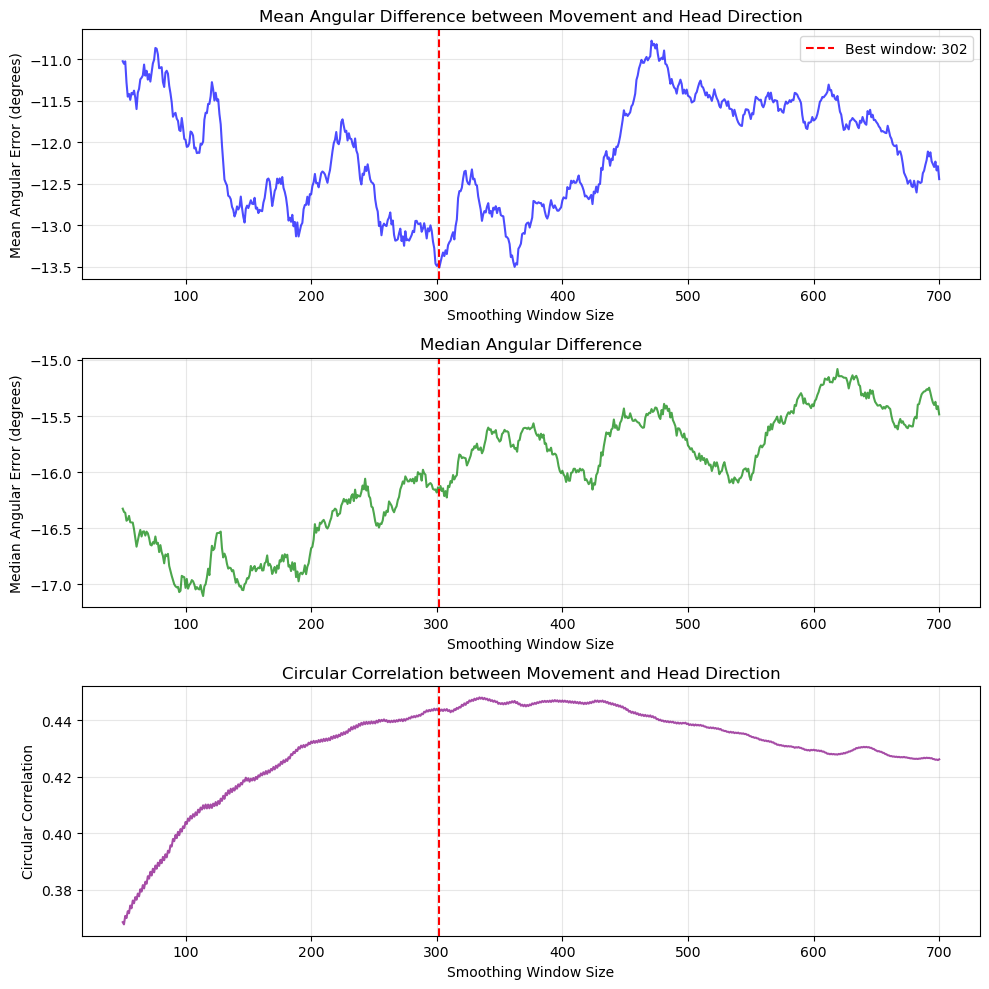

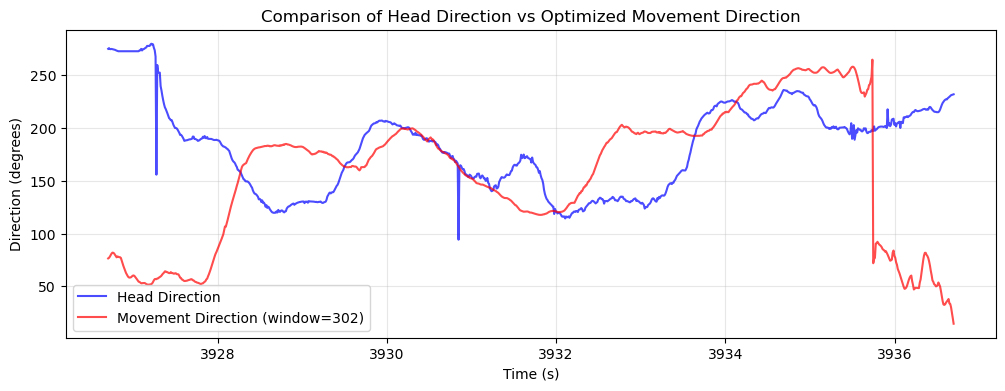

(302,
 {'window_sizes': [50,
   51,
   52,
   53,
   54,
   55,
   56,
   57,
   58,
   59,
   60,
   61,
   62,
   63,
   64,
   65,
   66,
   67,
   68,
   69,
   70,
   71,
   72,
   73,
   74,
   75,
   76,
   77,
   78,
   79,
   80,
   81,
   82,
   83,
   84,
   85,
   86,
   87,
   88,
   89,
   90,
   91,
   92,
   93,
   94,
   95,
   96,
   97,
   98,
   99,
   100,
   101,
   102,
   103,
   104,
   105,
   106,
   107,
   108,
   109,
   110,
   111,
   112,
   113,
   114,
   115,
   116,
   117,
   118,
   119,
   120,
   121,
   122,
   123,
   124,
   125,
   126,
   127,
   128,
   129,
   130,
   131,
   132,
   133,
   134,
   135,
   136,
   137,
   138,
   139,
   140,
   141,
   142,
   143,
   144,
   145,
   146,
   147,
   148,
   149,
   150,
   151,
   152,
   153,
   154,
   155,
   156,
   157,
   158,
   159,
   160,
   161,
   162,
   163,
   164,
   165,
   166,
   167,
   168,
   169,
   170,
   171,
   172,
   173,
   174,
   175,
   176,
   177,
   1

In [27]:
run_optimization(dataset=6, rat=sessions[9])

In [38]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.io import loadmat
import pandas as pd
from scipy.signal import savgol_filter
from scipy.stats import circmean, circstd

def diagnostic_analysis(positions, velocity_threshold=2):
    """
    Run comprehensive diagnostics on MD vs HD alignment issues.
    """
    
    # Extract components
    timestamps = positions[:, 0]
    x = positions[:, 1]
    y = positions[:, 2]
    hd = positions[:, 3]
    hd = (hd + 360) % 360
    
    # Calculate sampling rate
    dt = np.median(np.diff(timestamps))
    sampling_rate = 1.0 / dt
    print(f"Sampling rate: {sampling_rate:.2f} Hz")
    print(f"Median time step: {dt:.4f} seconds")
    
    # 1. CHECK POSITION DATA QUALITY
    print("\n" + "="*50)
    print("1. POSITION DATA QUALITY CHECK")
    print("="*50)
    
    # Calculate instantaneous displacement
    dx = np.diff(x)
    dy = np.diff(y)
    displacement = np.sqrt(dx**2 + dy**2)
    
    print(f"Mean displacement per frame: {np.mean(displacement):.4f} cm")
    print(f"Median displacement per frame: {np.median(displacement):.4f} cm")
    print(f"Max displacement per frame: {np.max(displacement):.4f} cm")
    print(f"% of frames with <0.1cm movement: {100 * np.mean(displacement < 0.1):.1f}%")
    
    # Calculate velocity
    velocity = displacement / dt
    print(f"Mean velocity: {np.mean(velocity):.2f} cm/s")
    print(f"% of time below {velocity_threshold} cm/s: {100 * np.mean(velocity < velocity_threshold):.1f}%")
    
    # 2. CHECK HEAD DIRECTION VARIABILITY
    print("\n" + "="*50)
    print("2. HEAD DIRECTION ANALYSIS")
    print("="*50)
    
    # Calculate angular velocity of head
    hd_unwrapped = np.unwrap(np.radians(hd))
    hd_angular_vel = np.abs(np.diff(hd_unwrapped)) / dt
    
    print(f"Mean HD angular velocity: {np.degrees(np.mean(hd_angular_vel)):.1f} deg/s")
    print(f"Max HD angular velocity: {np.degrees(np.max(hd_angular_vel)):.1f} deg/s")
    print(f"HD range: {np.min(hd):.1f} to {np.max(hd):.1f} degrees")
    
    # 3. CALCULATE MD WITH DIFFERENT METHODS
    print("\n" + "="*50)
    print("3. MOVEMENT DIRECTION CALCULATION COMPARISON")
    print("="*50)
    
    results = {}
    
    # Method 1: Raw instantaneous
    md_raw = np.degrees(np.arctan2(-dy, dx))
    md_raw = (md_raw + 360) % 360
    md_raw = np.concatenate([md_raw, [md_raw[-1]]])
    results['raw'] = md_raw
    
    # Method 2: Smooth positions first, then calculate MD
    window_length = min(21, len(x) - 1)
    if window_length % 2 == 0:
        window_length -= 1
    
    if window_length >= 5:
        x_smooth = savgol_filter(x, window_length, 3)
        y_smooth = savgol_filter(y, window_length, 3)
        dx_smooth = np.diff(x_smooth)
        dy_smooth = np.diff(y_smooth)
        md_smooth_first = np.degrees(np.arctan2(-dy_smooth, dx_smooth))
        md_smooth_first = (md_smooth_first + 360) % 360
        md_smooth_first = np.concatenate([md_smooth_first, [md_smooth_first[-1]]])
        results['smooth_first'] = md_smooth_first
    
    # Method 3: Use larger time windows for displacement
    window_frames = int(0.5 / dt)  # 0.5 second window
    if window_frames > 1 and window_frames < len(x) - 1:
        md_windowed = np.zeros(len(x))
        for i in range(len(x)):
            start_idx = max(0, i - window_frames)
            end_idx = min(len(x) - 1, i + window_frames)
            if end_idx > start_idx:
                dx_win = x[end_idx] - x[start_idx]
                dy_win = y[end_idx] - y[start_idx]
                if np.sqrt(dx_win**2 + dy_win**2) > 0.1:  # Only if moved > 0.1cm
                    md_windowed[i] = (np.degrees(np.arctan2(-dy_win, dx_win)) + 360) % 360
                else:
                    md_windowed[i] = np.nan
        results['windowed'] = md_windowed
    
    # 4. CHECK FOR SYSTEMATIC OFFSET
    print("\n" + "="*50)
    print("4. CHECKING FOR SYSTEMATIC OFFSET")
    print("="*50)
    
    # Only use high velocity periods for offset calculation
    high_vel_mask = velocity > velocity_threshold * 2
    high_vel_indices = np.where(high_vel_mask)[0]
    
    if len(high_vel_indices) > 100:
        # Test different rotation offsets
        offsets = np.arange(0, 360, 10)
        correlations = []
        
        for offset in offsets:
            hd_rotated = (hd[high_vel_indices] + offset) % 360
            md_test = md_raw[high_vel_indices]
            
            # Calculate circular correlation
            hd_rad = np.radians(hd_rotated)
            md_rad = np.radians(md_test)
            sin_diff = np.sin(hd_rad - md_rad)
            cos_diff = np.cos(hd_rad - md_rad)
            r = np.sqrt(np.mean(cos_diff)**2 + np.mean(sin_diff)**2)
            correlations.append(r)
        
        best_offset_idx = np.argmax(correlations)
        best_offset = offsets[best_offset_idx]
        best_correlation = correlations[best_offset_idx]
        
        print(f"Best offset: {best_offset} degrees")
        print(f"Correlation at best offset: {best_correlation:.3f}")
        
        if best_correlation > 0.5:
            print("POTENTIAL FIX: There appears to be a systematic rotation offset!")
    
    # 5. PLOT DIAGNOSTICS
    fig, axes = plt.subplots(3, 2, figsize=(15, 12))
    
    # Plot 1: Trajectory
    axes[0, 0].plot(x, y, 'b-', alpha=0.3, linewidth=0.5)
    axes[0, 0].scatter(x[::100], y[::100], c=hd[::100], cmap='hsv', s=20, vmin=0, vmax=360)
    axes[0, 0].set_xlabel('X position (cm)')
    axes[0, 0].set_ylabel('Y position (cm)')
    axes[0, 0].set_title('Trajectory (colored by HD)')
    axes[0, 0].set_aspect('equal')
    
    # Plot 2: Velocity distribution
    axes[0, 1].hist(velocity, bins=50, alpha=0.7, edgecolor='black')
    axes[0, 1].axvline(velocity_threshold, color='r', linestyle='--', label=f'Threshold: {velocity_threshold} cm/s')
    axes[0, 1].set_xlabel('Velocity (cm/s)')
    axes[0, 1].set_ylabel('Count')
    axes[0, 1].set_title('Velocity Distribution')
    axes[0, 1].legend()
    
    # Plot 3: HD vs MD (raw) scatter
    if len(high_vel_indices) > 0:
        sample_indices = high_vel_indices[::max(1, len(high_vel_indices)//1000)]
        axes[1, 0].scatter(hd[sample_indices], md_raw[sample_indices], alpha=0.5, s=1)
        axes[1, 0].plot([0, 360], [0, 360], 'r--', alpha=0.5)
        axes[1, 0].set_xlabel('Head Direction (degrees)')
        axes[1, 0].set_ylabel('Movement Direction (degrees)')
        axes[1, 0].set_title(f'HD vs MD Scatter (velocity > {velocity_threshold*2} cm/s)')
        axes[1, 0].set_xlim([0, 360])
        axes[1, 0].set_ylim([0, 360])
    
    # Plot 4: Time series comparison
    time_slice = slice(0, min(2000, len(timestamps)))
    axes[1, 1].plot(timestamps[time_slice], hd[time_slice], 'b-', alpha=0.7, label='HD')
    axes[1, 1].plot(timestamps[time_slice], md_raw[time_slice], 'r-', alpha=0.3, label='MD (raw)')
    axes[1, 1].set_xlabel('Time (s)')
    axes[1, 1].set_ylabel('Direction (degrees)')
    axes[1, 1].set_title('HD vs MD Time Series')
    axes[1, 1].legend()
    
    # Plot 5: Angular difference distribution
    angular_diff = np.abs((hd[high_vel_indices] - md_raw[high_vel_indices] + 180) % 360 - 180)
    axes[2, 0].hist(angular_diff, bins=36, alpha=0.7, edgecolor='black')
    axes[2, 0].set_xlabel('Angular Difference (degrees)')
    axes[2, 0].set_ylabel('Count')
    axes[2, 0].set_title('HD-MD Angular Difference Distribution')
    axes[2, 0].axvline(90, color='r', linestyle='--', alpha=0.5, label='90° (perpendicular)')
    axes[2, 0].axvline(180, color='g', linestyle='--', alpha=0.5, label='180° (opposite)')
    axes[2, 0].legend()
    
    # Plot 6: Displacement per frame
    axes[2, 1].hist(displacement, bins=50, alpha=0.7, edgecolor='black')
    axes[2, 1].set_xlabel('Displacement per frame (cm)')
    axes[2, 1].set_ylabel('Count')
    axes[2, 1].set_title('Frame-to-frame Displacement')
    axes[2, 1].axvline(0.1, color='r', linestyle='--', label='0.1 cm threshold')
    axes[2, 1].legend()
    
    plt.tight_layout()
    plt.show()
    
    return results

def test_backwards_movement(positions):
    """
    Test if the animal frequently moves backwards relative to head direction.
    """
    x = positions[:, 1]
    y = positions[:, 2]
    hd = positions[:, 3]
    
    # Calculate movement vector
    dx = np.diff(x)
    dy = np.diff(y)
    
    # Calculate expected movement direction based on HD
    hd_rad = np.radians(hd[:-1])
    expected_dx = np.cos(hd_rad)
    expected_dy = np.sin(hd_rad)
    
    # Calculate dot product (positive = forward, negative = backward)
    dot_product = dx * expected_dx + dy * expected_dy
    
    # Calculate percentage of backward movement
    backward_percentage = 100 * np.mean(dot_product < 0)
    
    print("\n" + "="*50)
    print("FORWARD/BACKWARD MOVEMENT ANALYSIS")
    print("="*50)
    print(f"Percentage of time moving backward: {backward_percentage:.1f}%")
    print(f"Percentage of time moving forward: {100 - backward_percentage:.1f}%")
    
    if backward_percentage > 30:
        print("WARNING: Significant backward movement detected!")
        print("This could explain low MD-HD correlation.")
    
    return dot_product

# Usage example
def run_diagnostics(dataset, rat, epoch='wake1'):
    """Run all diagnostics on your data."""
    from pathlib import Path
    
    # Load data (same as before)
    current_path = Path().resolve().parent
    data_path = current_path / f"data/dusz/Dataset_{dataset}/{rat}/Data"
    
    epochs = loadmat(data_path / "BehavEpochs.mat", struct_as_record=False, squeeze_me=True)
    
    if dataset == 6:
        epoch_data = epochs['wakeEp'].__dict__
    else:
        epoch_data = epochs[f'{epoch}Ep'].__dict__
    
    tracking_data = pd.read_csv(data_path / "Tracking_data.csv")
    tracking_data = tracking_data.set_axis(['timestamp', 'x', 'y', 'hd', 'pitch', 'roll'], axis=1)
    
    positions = tracking_data[['timestamp', 'x', 'y', 'hd']].to_numpy()
    position_mask = (positions[:, 0] > epoch_data['start']) & (positions[:, 0] < epoch_data['stop'])
    positions = positions[position_mask]
    
    # Normalize
    positions[:, 1] += abs(np.min(positions[:, 1]))
    positions[:, 2] += abs(np.min(positions[:, 2]))
    
    # Run diagnostics
    print("Running comprehensive diagnostics...")
    results = diagnostic_analysis(positions)
    
    # Test for backward movement
    dot_products = test_backwards_movement(positions)
    
    return results, dot_products

Running comprehensive diagnostics...
Sampling rate: 100.00 Hz
Median time step: 0.0100 seconds

1. POSITION DATA QUALITY CHECK
Mean displacement per frame: 0.0369 cm
Median displacement per frame: 0.0179 cm
Max displacement per frame: 1.4788 cm
% of frames with <0.1cm movement: 90.3%
Mean velocity: 3.69 cm/s
% of time below 2 cm/s: 52.1%

2. HEAD DIRECTION ANALYSIS
Mean HD angular velocity: 79.8 deg/s
Max HD angular velocity: 17960.5 deg/s
HD range: 0.0 to 360.0 degrees

3. MOVEMENT DIRECTION CALCULATION COMPARISON

4. CHECKING FOR SYSTEMATIC OFFSET
Best offset: 0 degrees
Correlation at best offset: 0.518
POTENTIAL FIX: There appears to be a systematic rotation offset!


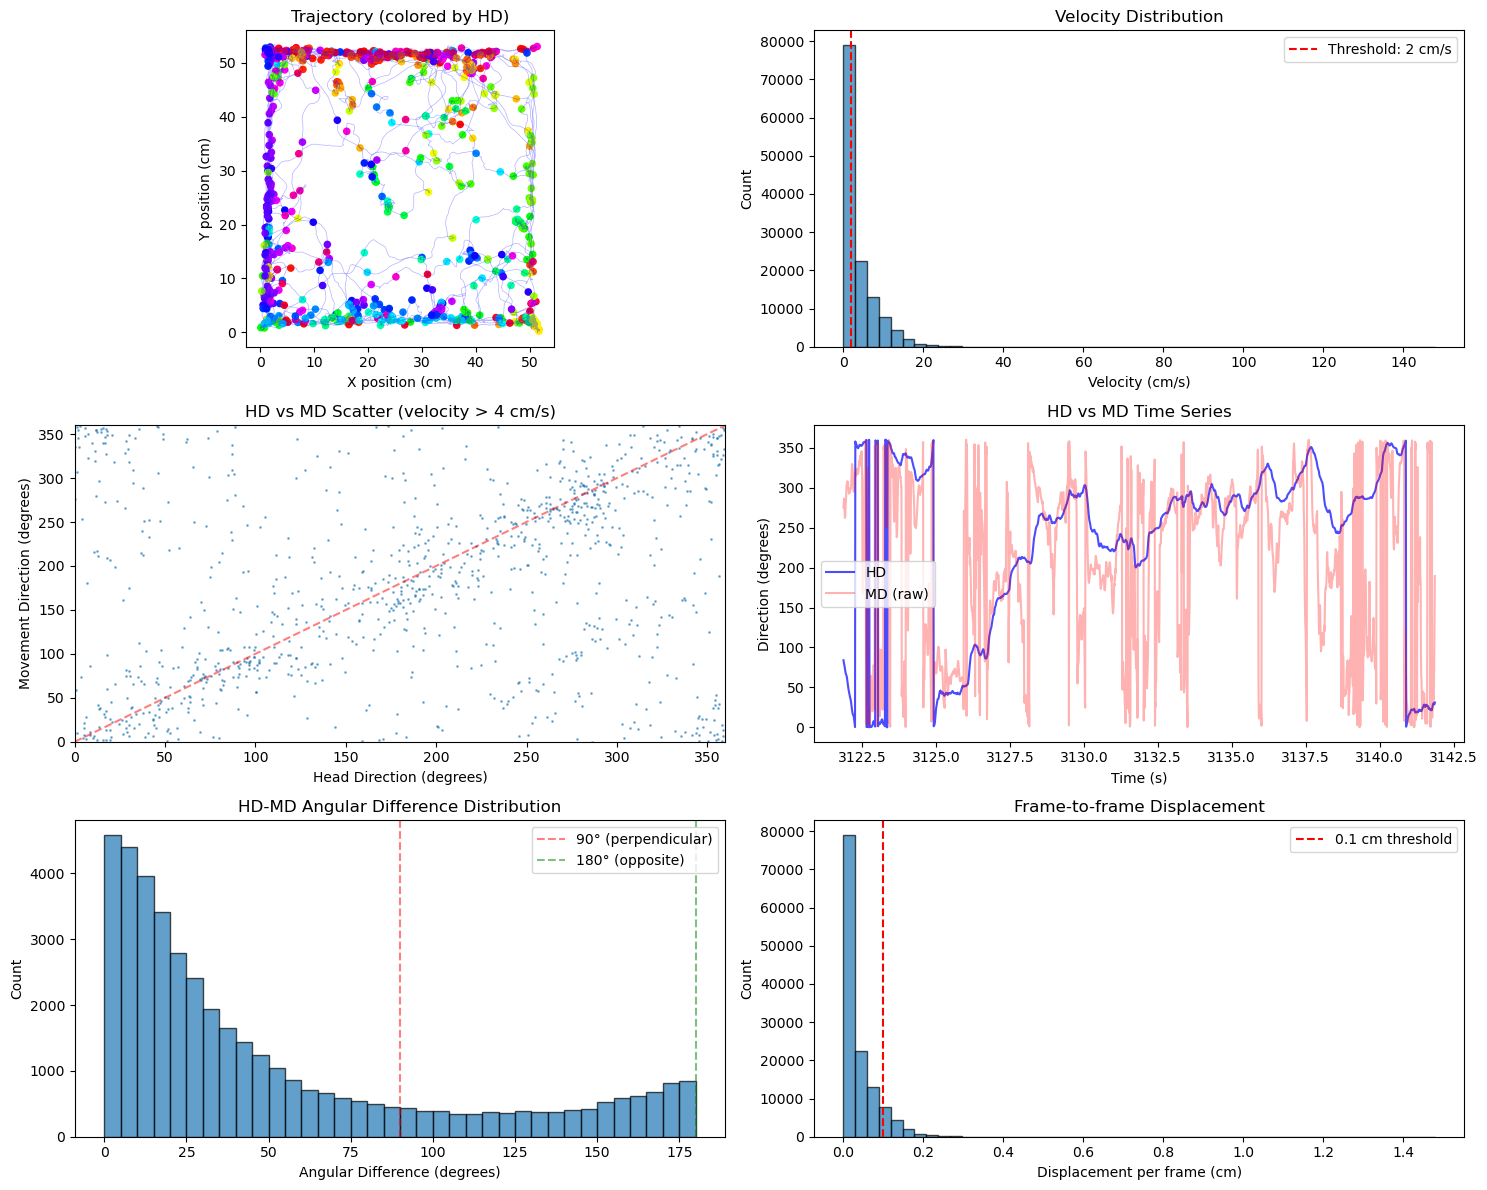


FORWARD/BACKWARD MOVEMENT ANALYSIS
Percentage of time moving backward: 47.8%
Percentage of time moving forward: 52.2%
This could explain low MD-HD correlation.


In [39]:
results, dot_products = run_diagnostics(dataset=6, rat=sessions[0])

In [43]:
import numpy as np

def get_md_from_xy(positions, smoothing_window=75):
    """
    Calculate movement direction from x,y positions.
    positions columns: [timestamp, x, y, hd]
    """
    x = positions[:, 1]
    y = positions[:, 2]
    dx = x[1:] - x[:-1]
    dy = y[1:] - y[:-1]
    direction = np.degrees(np.arctan2(-dy, dx))
    direction = (direction + 360) % 360
    direction = circular_smooth(direction, smoothing_window=smoothing_window)
    # pad to original length
    direction = np.concatenate([direction, [direction[-1]]])
    return direction

def _wrap180(a):
    return (a + 180) % 360 - 180

def _circ_mean_deg(angles_deg, weights=None):
    a = np.deg2rad(angles_deg)
    if weights is None:
        weights = np.ones_like(a)
    C = np.sum(weights * np.cos(a))
    S = np.sum(weights * np.sin(a))
    return (np.rad2deg(np.arctan2(S, C)) + 360) % 360

def _circ_std_deg(angles_deg):
    a = np.deg2rad(angles_deg)
    C = np.mean(np.cos(a))
    S = np.mean(np.sin(a))
    R = np.hypot(C, S)
    return np.rad2deg(np.sqrt(-2*np.log(max(R, 1e-12))))

def estimate_bias_and_lag(
    positions,
    vthr=5.0,                # only trust high-speed data
    window=75,               # reasonable (not huge) smoothing for MD
    max_lag_sec=2.0,         # search ± this many seconds
    prefilter=True           # drop low-speed before computing MD
):
    """
    Returns:
      diag: dict with best bias (deg), best lag (sec), and curves to plot.
    """
    # filter to high-speed
    speed = compute_speed_cm_per_s(positions)
    mask = speed >= float(vthr)
    if prefilter:
        pos_use = positions[mask]
    else:
        pos_use = positions

    if len(pos_use) < max(10, window + 5):
        raise ValueError("Not enough high-speed samples for diagnostics.")

    # compute MD/HD on the data we actually evaluate
    md = get_md_from_xy(pos_use, smoothing_window=window)
    hd = (pos_use[:, 3] + 360) % 360
    t = pos_use[:, 0]

    # sampling step (robust)
    dt = np.median(np.diff(t))
    if not np.isfinite(dt) or dt <= 0:
        raise ValueError("Nonpositive or invalid dt inferred from timestamps.")
    max_lag_samps = int(round(max_lag_sec / dt))
    lags = np.arange(-max_lag_samps, max_lag_samps + 1)
    lag_secs = lags * dt

    # unit vectors for MD/HD
    md_rad = np.deg2rad(md)
    hd_rad = np.deg2rad(hd)
    md_uv = np.stack([np.cos(md_rad), np.sin(md_rad)], axis=1)
    hd_uv = np.stack([np.cos(hd_rad), np.sin(hd_rad)], axis=1)

    # scan lags: for each lag, compute diff angles and their circular stats
    corr_vs_lag = []
    meanerr_vs_lag = []
    mederr_vs_lag = []
    bias_vs_lag = []
    std_vs_lag = []

    for L in lags:
        if L > 0:
            mdL = md[L:];  hdL = hd[:-L];  uv_dot = (md_uv[L:] * hd_uv[:-L]).sum(1)
        elif L < 0:
            k = -L
            mdL = md[:-k]; hdL = hd[k:];   uv_dot = (md_uv[:-k] * hd_uv[k:]).sum(1)
        else:
            mdL = md;     hdL = hd;       uv_dot = (md_uv * hd_uv).sum(1)

        # correlation proxy: mean dot product of unit vectors
        corr_vs_lag.append(np.mean(uv_dot))

        # per-lag bias: circular mean of (MD - HD)
        diff = _wrap180(mdL - hdL)
        biasL = _circ_mean_deg(diff)  # in [0,360)
        bias_vs_lag.append(biasL)

        # remove bias and compute errors
        debiased = _wrap180(diff - biasL)
        meanerr_vs_lag.append(np.mean(np.abs(debiased)))
        mederr_vs_lag.append(np.median(np.abs(debiased)))
        std_vs_lag.append(_circ_std_deg(debiased))

    corr_vs_lag = np.asarray(corr_vs_lag)
    meanerr_vs_lag = np.asarray(meanerr_vs_lag)
    mederr_vs_lag  = np.asarray(mederr_vs_lag)
    std_vs_lag     = np.asarray(std_vs_lag)
    bias_vs_lag    = np.asarray(bias_vs_lag)

    # choose lag that minimizes median absolute error after removing bias
    best_idx = int(np.nanargmin(mederr_vs_lag))
    best_lag_sec = float(lag_secs[best_idx])
    best_bias_deg = float(bias_vs_lag[best_idx])  # rotate HD by this to align to MD

    diag = {
        'vthr': float(vthr),
        'window': int(window),
        'lag_secs': lag_secs.tolist(),
        'corr_vs_lag': corr_vs_lag.tolist(),
        'meanerr_vs_lag': meanerr_vs_lag.tolist(),
        'mederr_vs_lag': mederr_vs_lag.tolist(),
        'std_vs_lag': std_vs_lag.tolist(),
        'bias_vs_lag': bias_vs_lag.tolist(),
        'best': {
            'lag_sec': best_lag_sec,
            'bias_deg': best_bias_deg,
            'median_abs_error_deg': float(mederr_vs_lag[best_idx]),
            'corr_at_best': float(corr_vs_lag[best_idx]),
        }
    }
    return diag

def apply_hd_corrections(t, hd_deg, bias_deg=0.0, lag_sec=0.0):
    """
    Returns HD corrected for constant bias and temporal lag.
    Circular interpolation is used for lag shifting.
    """
    # bias first
    hd_corr = (hd_deg + bias_deg) % 360
    if abs(lag_sec) < 1e-9:
        return hd_corr

    # circular interpolation of angles: interpolate on unit circle
    a = np.deg2rad(hd_corr)
    cx = np.cos(a); cy = np.sin(a)
    t_shifted = t + lag_sec
    cx_i = np.interp(t_shifted, t, cx)
    cy_i = np.interp(t_shifted, t, cy)
    # renormalize
    norm = np.hypot(cx_i, cy_i)
    cx_i = np.where(norm > 0, cx_i / norm, 1.0)
    cy_i = np.where(norm > 0, cy_i / norm, 0.0)
    return (np.rad2deg(np.arctan2(cy_i, cx_i)) + 360) % 360


In [44]:
from pathlib import Path

rat = sessions[0]
    
# Load data (same as before)
current_path = Path().resolve().parent
data_path = current_path / f"data/dusz/Dataset_6/{rat}/Data"

    
epochs = loadmat(data_path / "BehavEpochs.mat", struct_as_record=False, squeeze_me=True)
    
epoch_data = epochs['wakeEp'].__dict__

    
tracking_data = pd.read_csv(data_path / "Tracking_data.csv")
tracking_data = tracking_data.set_axis(['timestamp', 'x', 'y', 'hd', 'pitch', 'roll'], axis=1)
    
positions = tracking_data[['timestamp', 'x', 'y', 'hd']].to_numpy()
position_mask = (positions[:, 0] > epoch_data['start']) & (positions[:, 0] < epoch_data['stop'])
positions = positions[position_mask]
    
# Normalize
positions[:, 1] += abs(np.min(positions[:, 1]))
positions[:, 2] += abs(np.min(positions[:, 2]))

diag = estimate_bias_and_lag(positions, vthr=5.0, window=75, max_lag_sec=.01, prefilter=True)
print("Best bias (deg):", diag['best']['bias_deg'])
print("Best lag (s):   ", diag['best']['lag_sec'])
print("Median |err| at best (deg):", diag['best']['median_abs_error_deg'])

# apply corrections to HD, then re-run your optimization without needing huge windows
t = positions[:, 0]
hd = (positions[:, 3] + 360) % 360
hd_corr = apply_hd_corrections(t, hd, bias_deg=diag['best']['bias_deg'], lag_sec=diag['best']['lag_sec'])
pos_corr = positions.copy()
pos_corr[:, 3] = hd_corr

best_window, results = optimize_smoothing_window(
    pos_corr, window_range=(1, 400), velocity_threshold=5.0, prefilter=True, criterion='median_error'
)

Best bias (deg): 356.22898884851287
Best lag (s):    -0.010000000000218279
Median |err| at best (deg): 19.48962232614622
Testing window sizes 1..400 with velocity ≥ 5.0 cm/s (prefilter=True)


100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 400/400 [00:03<00:00, 102.20it/s]


In [37]:
best_window

244